# **What is this notebook?**

### Almost all of the figures in this paper were generated directly with Python.  Scripts used to calculate overarching statistics and to make the majority of figures used in the paper are included below.  Any questions or requests for additional information can be directed to me (Noah Jacobs) via email.  Multiple generative AI models (mainly Claude) were used to help create and improve this codebase.

# Section 3.2: Number of images reduced due to cloud cover

In [2]:
import pandas as pd
from pathlib import Path

BASE = Path(r"C:\Users\nj142\Desktop\Paper 1 Misc. Data")

FILES = {
    "Breakup": {
        "NS":  BASE / "BREAKUP_CLOUD_FILTERS" / "NS_cloud_classifications.csv",
        "YF":  BASE / "BREAKUP_CLOUD_FILTERS" / "YF_cloud_classifications.csv",
        "YKD": BASE / "BREAKUP_CLOUD_FILTERS" / "YKD_cloud_classifications.csv",
    },
    "Freezeup": {
        "NS":  BASE / "FREEZEUP_CLOUD_FILTERS" / "NS_cloud_classifications.csv",
        "YF":  BASE / "FREEZEUP_CLOUD_FILTERS" / "YF_cloud_classifications.csv",
        "YKD": BASE / "FREEZEUP_CLOUD_FILTERS" / "YKD_cloud_classifications.csv",
    },
}

# Classification values that count as "cloudy" for the combined bucket
CLOUDY_LABELS = {"Cloudy", "Very Cloudy"}
NOT_CLOUDY_LABEL = "Not Cloudy"


def summarize(filepath: Path, site: str, season: str) -> dict:
    df = pd.read_csv(filepath)

    if "Classification" not in df.columns:
        raise ValueError(f"'Classification' column not found in {filepath}")

    total = len(df)
    counts = df["Classification"].value_counts(dropna=False)

    not_cloudy_n = int(counts.get(NOT_CLOUDY_LABEL, 0))
    cloudy_n = int(sum(counts.get(label, 0) for label in CLOUDY_LABELS))

    other_n = total - not_cloudy_n - cloudy_n

    return {
        "season": season,
        "site": site,
        "total": total,
        "not_cloudy_n": not_cloudy_n,
        "not_cloudy_pct": (not_cloudy_n / total * 100) if total else 0,
        "cloudy_n": cloudy_n,
        "cloudy_pct": (cloudy_n / total * 100) if total else 0,
        "other_n": other_n,
        "raw_counts": counts.to_dict(),
    }


def print_combined(label: str, results: list) -> None:
    total = sum(r["total"] for r in results)
    not_cloudy = sum(r["not_cloudy_n"] for r in results)
    cloudy = sum(r["cloudy_n"] for r in results)
    other = sum(r["other_n"] for r in results)

    print(f"\n{label}")
    print(f"  Total images:       {total}")
    if total:
        print(f"  Not Cloudy:         {not_cloudy} ({not_cloudy/total*100:.1f}%)")
        print(f"  Cloudy/Very Cloudy: {cloudy} ({cloudy/total*100:.1f}%)")
        if other:
            print(f"  Other/uncategorized: {other}")


def main():
    all_results = []

    for season, site_files in FILES.items():
        season_results = []
        for site, path in site_files.items():
            if not path.exists():
                print(f"[WARNING] File not found for {season} {site}: {path}")
                continue
            season_results.append(summarize(path, site, season))

        print("=" * 70)
        print(f"{season.upper()}")
        print("=" * 70)
        for r in season_results:
            print(f"\nSite: {r['site']}")
            print(f"  Total images:      {r['total']}")
            print(f"  Not Cloudy:        {r['not_cloudy_n']} ({r['not_cloudy_pct']:.1f}%)")
            print(f"  Cloudy/Very Cloudy:{r['cloudy_n']:>6} ({r['cloudy_pct']:.1f}%)")
            if r["other_n"]:
                print(f"  Other/uncategorized: {r['other_n']}")
            print(f"  Raw category counts: {r['raw_counts']}")

        print("\n" + "-" * 70)
        print_combined(f"{season.upper()} COMBINED ACROSS ALL SITES", season_results)
        print()

        all_results.extend(season_results)

    print("=" * 70)
    print_combined("GRAND TOTAL (BREAKUP + FREEZEUP, ALL SITES)", all_results)
    print("=" * 70)


if __name__ == "__main__":
    main()

BREAKUP

Site: NS
  Total images:      4113
  Not Cloudy:        2720 (66.1%)
  Cloudy/Very Cloudy:  1393 (33.9%)
  Raw category counts: {'Not Cloudy': 2720, 'Very Cloudy': 1179, 'Cloudy': 214}

Site: YF
  Total images:      6756
  Not Cloudy:        5824 (86.2%)
  Cloudy/Very Cloudy:   932 (13.8%)
  Raw category counts: {'Not Cloudy': 5824, 'Cloudy': 483, 'Very Cloudy': 449}

Site: YKD
  Total images:      1986
  Not Cloudy:        1454 (73.2%)
  Cloudy/Very Cloudy:   313 (15.8%)
  Other/uncategorized: 219
  Raw category counts: {'Not Cloudy': 1454, 'Very Cloudy': 313, 'Some Clouds': 219}

----------------------------------------------------------------------

BREAKUP COMBINED ACROSS ALL SITES
  Total images:       12855
  Not Cloudy:         9998 (77.8%)
  Cloudy/Very Cloudy: 2638 (20.5%)
  Other/uncategorized: 219

FREEZEUP

Site: NS
  Total images:      986
  Not Cloudy:        502 (50.9%)
  Cloudy/Very Cloudy:   484 (49.1%)
  Raw category counts: {'Not Cloudy': 502, 'Very Cloudy':

# Figure 3: Image Histograms with Red Thresholding

c:\Users\nj142\AppData\Local\anaconda3\Lib\site-packages\pyogrio\core.py:39: RuntimeWarning: Could not detect PROJ data files. Set PROJ_LIB environment variable to the correct path.
  _init_proj_data()


ice-on: 182,650 lake pixels sampled (135,488 water / 47,162 ice at rho=0.095)
ice-off: 182,650 lake pixels sampled (60,843 water / 121,807 ice at rho=0.095)
histogram x range: 0.027 - 0.435 reflectance (tick step 0.1)


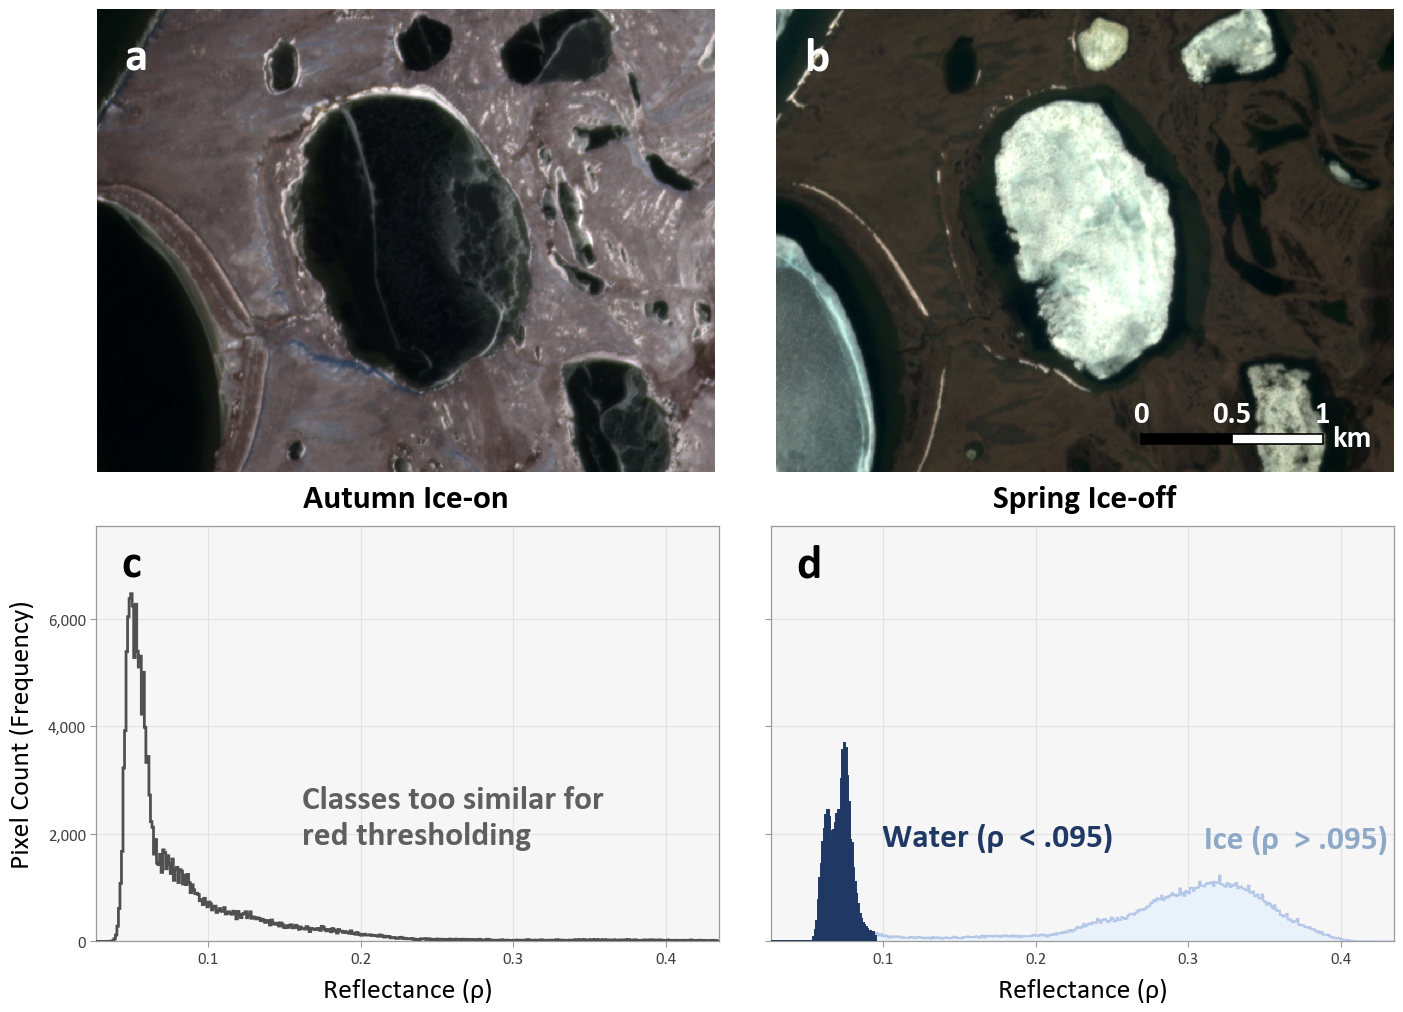

In [ ]:
"""
Ice-on vs. ice-off red-band threshold figure (PlanetScope + ALPOD lakes).

Layout (matches the reference figure):
    a  Autumn ice-on RGB      b  Spring ice-off RGB (+ scale bar)
    c  Ice-on red histogram   d  Ice-off red histogram split at the threshold
                                 (water = dark navy, ice = light blue)

Edit the CONFIG section below and run:
    python lake_ice_threshold_figure.py

* Several PlanetScope scenes can be given per season (e.g. when a scene seam
  runs through the lakes). They are mosaicked on the fly; where scenes overlap,
  the first file in the list that has valid data wins. Scenes in different UTM
  zones are warped to a common CRS automatically.
* Histograms sample the red band from every pixel under the selected lake
  polygons (each pixel counted once, even where scenes overlap).
* Zoom / pan / rotation only change the RGB panels, never the histograms.
* Exposure / contrast / saturation / white balance / gamma can be set
  separately for each RGB panel; they never affect the histograms.
* The histogram x-axis is auto-fitted to the bulk of the lake pixels (both
  seasons), so the spectral curves fill the panel. Set `xlim` to override.
* The histogram y-axis is fitted to the tallest visible bin, leaving just
  enough room above it for the panel letters.
"""

from dataclasses import dataclass, field
from pathlib import Path

import geopandas as gpd
import matplotlib.patches as mpatches
import matplotlib.patheffects as pe
import matplotlib.pyplot as plt
import numpy as np
import rasterio
import shapely
from matplotlib.ticker import FuncFormatter, MultipleLocator
from rasterio.enums import Resampling
from rasterio.features import geometry_mask
from rasterio.merge import merge
from rasterio.vrt import WarpedVRT


# =============================================================================
# CONFIG
# =============================================================================
@dataclass
class Config:
    # --- Inputs --------------------------------------------------------------
    # One or more PlanetScope SR GeoTIFFs per season. Order = priority in overlaps.
    ice_on_images: list = field(default_factory=lambda: [
        r"C:\Users\nj142\Desktop\Freezeup_Breakup_Attempt_2_-_First_Paper_psscene_analytic_sr_udm2\PSScene\20231004_215418_09_2479_3B_AnalyticMS_SR_clip.tif",
        r"C:\Users\nj142\Desktop\Freezeup_Breakup_Attempt_2_-_First_Paper_psscene_analytic_sr_udm2\PSScene\20231004_215415_99_2479_3B_AnalyticMS_SR_clip.tif",
        # r"E:\path\to\autumn_scene_2_ortho_analytic_4b_sr.tif",
    ])
    ice_off_images: list = field(default_factory=lambda: [
        r"C:\Users\nj142\Desktop\second_option_for_better_breakup_for_figure_for_first_paper_psscene_analytic_sr_udm2\PSScene\20250627_222710_77_24fa_3B_AnalyticMS_SR.tif"
        # r"E:\path\to\spring_scene_2_ortho_analytic_4b_sr.tif",
    ])
    lakes_shp: str = (r"E:\planetscope_lake_ice\Data\Input\Study Sites - Manual ALPOD Data"
                      r"\NS 50x50 km\NS Lakes from ALPOD Shapefile\NS_50x50km_lakes.shp")
    id_column: str = "id"         # falls back to "lake_id" / "id" if missing
    lake_ids: list = field(default_factory=lambda: [
    502465,
    ])

    # --- Bands / reflectance ---------------------------------------------------
    # 1-based band numbers. None = auto (4-band SR: R=3,G=2,B=1; 8-band SR: R=6,G=4,B=2)
    rgb_bands: tuple = None
    red_band: int = None
    reflectance_scale: float = 10000.0   # PlanetScope SR stores reflectance x 10,000
    threshold: float = 0.095             # red reflectance: < water, > ice

    # --- View: zoom / pan / rotation (RGB panels only) -----------------------
    rotation_deg: float = 0.0     # rotate the image counter-clockwise by this many degrees
    zoom: float = 0.8           # >1 zooms in, <1 zooms out (1 = lakes fit + padding)
    pad_frac: float = 0.10        # padding around the lakes at zoom = 1 (fraction of extent)
    view_width_m: float = None    # set to force an exact view width (overrides zoom/pad)
    pan_right_m: float = 0.0      # shift the view right (+) / left (-) on screen, metres
    pan_up_m: float = 0.0         # shift the view up (+) / down (-) on screen, metres
    display_res_m: float = None   # None = native resolution (3 m)
    show_lake_outlines: bool = False
    outline_color: str = "#FFD966"

    # --- RGB stretch -----------------------------------------------------------
    stretch_percentiles: tuple = (1, 99)  # computed over valid pixels in the view
    stretch_joint: bool = True    # same stretch for R, G, B (keeps natural colour balance)

    # --- Per-image colour adjustments (left = ice-on, right = ice-off) ---------
    # Each is a (left, right) pair; a single number applies to both panels.
    # Applied after the stretch, in this order: white balance -> exposure ->
    # contrast -> saturation -> gamma.
    exposure: tuple = (-0.5, 0.0)       # stops: -1 = half as bright, +1 = twice as bright
    contrast: tuple = (1.0, 1.0)        # around mid-grey: <1 flatter, >1 punchier
    saturation: tuple = (1.0, 0.85)     # 0 = greyscale, 1 = unchanged, >1 more vivid
    white_balance: tuple = ((1.0, 1.0, 1.0),   # (R, G, B) gains, left panel
                            (1.0, 1.0, 1.0))   # (R, G, B) gains, right panel
    gamma: tuple = (1.0, 0.8)           # <1 brightens midtones, >1 darkens

    # --- Scale bar / north arrow (drawn on panel b) ----------------------------
    scalebar_km: float = None     # None = auto "nice" length
    scalebar_max_frac: float = 0.3  # auto length is at most this fraction of the view width
    scalebar_loc: str = "lower right"  # "lower right" or "lower left"
    scalebar_fontsize: float = 22
    scalebar_text_color: str = "white"
    show_north_arrow: bool = None  # None = only when rotation_deg != 0

    # --- Histograms ------------------------------------------------------------
    bin_width: float = 10         # in scaled DN units (10 = 0.001 reflectance)
    xlim: tuple = None            # reflectance; None = auto-fit to the lake pixels, or e.g. (0.03, 0.30)
    xlim_percentiles: tuple = (0.5, 99.5)  # auto xlim covers this range of pixels (both seasons)
    xlim_pad_frac: float = 0.04   # extra room either side of the auto xlim
    xtick_step: float = None      # reflectance; None = auto, or e.g. 0.02
    ylim_max: float = None        # None = auto: tallest bin sits just under the panel letters
    ytick_step: float = None      # None = auto
    letter_pad: float = 0.02      # gap between the panel letter and the peak (axes fraction)
    split_ice_on: bool = False    # also colour panel c by the threshold
    shore_buffer_m: float = 0.0   # >0 shrinks polygons before sampling (drops mixed shore pixels)

    # --- Labels ------------------------------------------------------------------
    title_left: str = "Autumn Ice-on"
    title_right: str = "Spring Ice-off"
    text_c: str = "Classes too similar for\nred thresholding"
    # Label positions: None = auto-place clear of the curves, or (x, y) in axes
    # fraction for the label's left/centre edge, e.g. pos_water = (0.115, 0.46)
    pos_text_c: tuple = None
    pos_water: tuple = None
    pos_ice: tuple = None
    xlabel: str = "Reflectance (\u03c1)"
    ylabel: str = "Pixel Count (Frequency)"
    font: str = "Calibri"


# Colours sampled from the reference figure
WATER_COLOR = "#1F3864"       # navy fill/line + "Water" label
ICE_LINE = "#B4C7E7"          # light blue outline
ICE_FILL = "#E9F1FB"          # pale blue fill
ICE_TEXT = "#8EA9C8"          # "Ice" label
ICEON_LINE = "#505050"        # panel c curve
ICEON_TEXT = "#5F5F5F"        # panel c annotation
AX_FACE = "#F6F6F6"
GRID = "#E2E2E2"
SPINE = "#9A9A9A"


# =============================================================================
# Raster helpers
# =============================================================================
def default_bands(count):
    if count >= 8:
        return (6, 4, 2), 6
    if count >= 3:
        return (3, 2, 1), 3
    raise ValueError(f"Need at least 3 bands for RGB, raster has {count}")


def open_sources(paths, crs):
    """Open rasters, warping any that are not already in `crs`."""
    srcs, handles = [], []
    for p in paths:
        src = rasterio.open(p)
        handles.append(src)
        nodata = src.nodata if src.nodata is not None else 0
        if src.crs != crs:
            src = WarpedVRT(src, crs=crs, resampling=Resampling.nearest,
                            nodata=nodata, src_nodata=nodata)
            handles.append(src)
        srcs.append(src)
    return srcs, handles


def mosaic(paths, crs, bounds, res, indexes):
    """Mosaic `paths` over `bounds`; first raster with valid data wins."""
    srcs, handles = open_sources(paths, crs)
    nodata = handles[0].nodata if handles[0].nodata is not None else 0
    try:
        arr, transform = merge(srcs, bounds=bounds, res=(res, res), nodata=nodata,
                               indexes=list(indexes), method="first")
    finally:
        for h in reversed(handles):
            h.close()
    valid = np.all(arr != nodata, axis=0)
    return arr, transform, valid


# =============================================================================
# View geometry (rotated window)
# =============================================================================
class View:
    """A rotated rectangular window. Screen right = u, screen up = v (map units)."""

    def __init__(self, cx, cy, width, height, res, rotation_deg):
        t = np.deg2rad(rotation_deg)
        self.u = np.array([np.cos(t), -np.sin(t)])
        self.v = np.array([np.sin(t), np.cos(t)])
        self.cx, self.cy, self.res = cx, cy, res
        self.W = max(int(round(width / res)), 2)
        self.H = max(int(round(height / res)), 2)

    def corners(self):
        hw, hh = self.W * self.res / 2, self.H * self.res / 2
        return np.array([[self.cx, self.cy] + sx * hw * self.u + sy * hh * self.v
                         for sx in (-1, 1) for sy in (-1, 1)])

    def map_to_pixel(self, x, y):
        dx, dy = np.asarray(x) - self.cx, np.asarray(y) - self.cy
        du = dx * self.u[0] + dy * self.u[1]
        dv = dx * self.v[0] + dy * self.v[1]
        return du / self.res + self.W / 2 - 0.5, self.H / 2 - dv / self.res - 0.5

    def sample(self, arr, transform, nodata_mask):
        """Nearest-neighbour resample of (bands, rows, cols) into the view grid."""
        cols, rows = np.meshgrid(np.arange(self.W) + 0.5, np.arange(self.H) + 0.5)
        du = (cols - self.W / 2) * self.res
        dv = (self.H / 2 - rows) * self.res
        X = self.cx + du * self.u[0] + dv * self.v[0]
        Y = self.cy + du * self.u[1] + dv * self.v[1]
        c, r = ~transform * (X, Y)
        ci, ri = np.floor(c).astype(int), np.floor(r).astype(int)
        inside = (ci >= 0) & (ri >= 0) & (ci < arr.shape[2]) & (ri < arr.shape[1])
        out = np.zeros((arr.shape[0], self.H, self.W), dtype=arr.dtype)
        ok = np.zeros((self.H, self.W), dtype=bool)
        out[:, inside] = arr[:, ri[inside], ci[inside]]
        ok[inside] = nodata_mask[ri[inside], ci[inside]]
        return out, ok


def build_view(cfg, lakes, res, aspect):
    coords = shapely.get_coordinates(lakes.geometry.values)
    c0 = lakes.geometry.union_all().centroid
    tmp = View(c0.x, c0.y, 1, 1, 1, cfg.rotation_deg)
    dx, dy = coords[:, 0] - c0.x, coords[:, 1] - c0.y
    du = dx * tmp.u[0] + dy * tmp.u[1]
    dv = dx * tmp.v[0] + dy * tmp.v[1]
    # Re-centre on the lakes' extent in the rotated frame, then pan
    mu, mv = (du.min() + du.max()) / 2 + cfg.pan_right_m, (dv.min() + dv.max()) / 2 + cfg.pan_up_m
    cx, cy = np.array([c0.x, c0.y]) + mu * tmp.u + mv * tmp.v

    if cfg.view_width_m:
        w = cfg.view_width_m
        h = w / aspect
    else:
        w = max(du.max() - du.min(), 1) * (1 + 2 * cfg.pad_frac)
        h = max(dv.max() - dv.min(), 1) * (1 + 2 * cfg.pad_frac)
        if w / h < aspect:
            w = h * aspect
        else:
            h = w / aspect
        w, h = w / cfg.zoom, h / cfg.zoom
    return View(cx, cy, w, h, res, cfg.rotation_deg)


# =============================================================================
# Figure pieces
# =============================================================================
def per_image(value, i):
    """Pick panel i's setting from a (left, right) pair, or use a single value for both."""
    if isinstance(value, (list, tuple)) and len(value) == 2:
        return value[i]
    return value


def to_rgb(img, ok, cfg, i):
    """Stretch to 0-1, then apply panel i's white balance, exposure, contrast, saturation, gamma."""
    img = img.astype("float32")
    lo_p, hi_p = cfg.stretch_percentiles
    rgba = np.zeros(img.shape[1:] + (4,), dtype="float32")
    if not ok.any():
        return rgba
    if cfg.stretch_joint:
        vals = img[:, ok]
        lo, hi = np.percentile(vals, lo_p), np.percentile(vals, hi_p)
        lims = [(lo, hi)] * 3
    else:
        lims = [(np.percentile(b[ok], lo_p), np.percentile(b[ok], hi_p)) for b in img]
    # Keep values unclipped until the end so exposure can recover highlights
    rgb = np.stack([(img[k] - lo) / max(hi - lo, 1e-6) for k, (lo, hi) in enumerate(lims)], axis=-1)

    rgb *= np.asarray(per_image(cfg.white_balance, i), dtype="float32")
    rgb *= 2.0 ** per_image(cfg.exposure, i)
    rgb = (rgb - 0.5) * per_image(cfg.contrast, i) + 0.5
    lum = rgb @ np.array([0.2126, 0.7152, 0.0722], dtype="float32")
    rgb = lum[..., None] + (rgb - lum[..., None]) * per_image(cfg.saturation, i)
    rgba[..., :3] = np.clip(rgb, 0, 1) ** per_image(cfg.gamma, i)
    rgba[..., 3] = ok
    return rgba


def nice_length(max_km):
    # Lengths whose halves are also round numbers (bar has two segments)
    for n in (100, 50, 20, 10, 5, 4, 2, 1, 0.5, 0.4, 0.2, 0.1, 0.05, 0.02, 0.01):
        if n <= max_km:
            return n
    return max_km


def draw_scalebar(ax, view, cfg):
    """Classic two-segment black/white scale bar with labels above."""
    width_km = view.W * view.res / 1000
    km = cfg.scalebar_km or nice_length(width_km * cfg.scalebar_max_frac)
    unit, f = ("km", 1) if km >= 1 else ("m", 1000)
    L = km * 1000 / view.res                     # bar length in display pixels
    W, H = view.W, view.H
    bh = 0.022 * H                               # bar thickness
    unit_w = 0.07 * W                            # room for the unit label right of the bar
    m = 0.045 * W
    x0 = W - m - unit_w - L if cfg.scalebar_loc == "lower right" else m
    y0 = H - 0.06 * H - bh                       # top edge of the bar (y grows downward)
    for i, fc in enumerate(("black", "white")):
        ax.add_patch(mpatches.Rectangle((x0 + i * L / 2, y0), L / 2, bh, facecolor=fc,
                                        edgecolor="black", lw=1.2, zorder=6))
    kw = dict(fontsize=cfg.scalebar_fontsize, fontfamily=cfg.font, fontweight="bold",
              color=cfg.scalebar_text_color, zorder=6)
    for frac in (0, 0.5, 1):
        ax.text(x0 + frac * L, y0 - 0.012 * H, f"{km * frac * f:g}", ha="center", va="bottom", **kw)
    ax.text(x0 + L + 0.015 * W, y0 + bh / 2, unit, ha="left", va="center", **kw)


def draw_north_arrow(ax, view, rotation_deg):
    t = np.deg2rad(rotation_deg)
    dx, dy = -np.sin(t), -np.cos(t)              # screen coords, y down (UTM grid north)
    W, H = view.W, view.H
    cx, cy, L = W * 0.92, H * 0.20, 0.11 * H
    halo = [pe.withStroke(linewidth=3, foreground="black")]
    arrow = ax.annotate("", xy=(cx + dx * L / 2, cy + dy * L / 2), xytext=(cx - dx * L / 2, cy - dy * L / 2),
                        arrowprops=dict(arrowstyle="-|>,head_width=0.35,head_length=0.6",
                                        color="white", lw=2), zorder=7)
    arrow.arrow_patch.set_path_effects(halo)
    ax.text(cx + dx * L * 0.85, cy + dy * L * 0.85, "N", color="white", fontsize=16,
            fontweight="bold", ha="center", va="center", zorder=7, path_effects=halo)


def draw_rgb_panel(ax, rgba, view, lakes, letter, cfg):
    ax.imshow(rgba, interpolation="nearest")
    if cfg.show_lake_outlines:
        for geom in lakes.geometry:
            for poly in getattr(geom, "geoms", [geom]):
                px, py = view.map_to_pixel(*poly.exterior.xy)
                ax.plot(px, py, color=cfg.outline_color, lw=0.8)
    ax.set_xlim(-0.5, view.W - 0.5)
    ax.set_ylim(view.H - 0.5, -0.5)
    ax.set_axis_off()
    ax.text(0.045, 0.94, letter, transform=ax.transAxes, color="white", fontsize=34,
            fontweight="bold", va="top", ha="left", zorder=8)


def histogram(values, edges):
    counts, _ = np.histogram(values, bins=edges)
    return counts


def auto_xlim(samples, thr_dn, cfg):
    """x range covering the bulk of the lake pixels in both seasons (and the threshold)."""
    samples = [v for v in samples if v.size]
    if not samples:
        return 0, cfg.reflectance_scale
    p_lo, p_hi = cfg.xlim_percentiles
    lo = min(min(np.percentile(v, p_lo) for v in samples), thr_dn)
    hi = max(max(np.percentile(v, p_hi) for v in samples), thr_dn)
    pad = cfg.xlim_pad_frac * (hi - lo)
    return max(lo - pad, 0), hi + pad


def style_hist_axes(ax, cfg, xlim, xstep, ymax, ystep, show_ylabels):
    ax.set_facecolor(AX_FACE)
    ax.grid(True, color=GRID, lw=0.8)
    ax.set_axisbelow(True)
    for s in ax.spines.values():
        s.set_color(SPINE)
        s.set_linewidth(0.9)
    ax.set_xlim(*xlim)
    ax.set_ylim(0, ymax)
    ax.xaxis.set_major_locator(MultipleLocator(xstep))
    ax.yaxis.set_major_locator(MultipleLocator(ystep))
    # Data are in scaled DN; label the ticks in reflectance with just enough decimals
    step_r = xstep / cfg.reflectance_scale
    dec = next((d for d in range(6) if abs(round(step_r, d) - step_r) < 1e-9), 6)
    ax.xaxis.set_major_formatter(FuncFormatter(lambda v, _: f"{v / cfg.reflectance_scale:.{dec}f}"))
    ax.yaxis.set_major_formatter(FuncFormatter(lambda v, _: f"{v:,.0f}" if show_ylabels else ""))
    ax.tick_params(colors="#404040", labelsize=12, length=4, color=SPINE)
    ax.set_xlabel(cfg.xlabel, fontsize=20, labelpad=8)


def curve_clearance(ax, txt, counts, edges):
    """Lowest y (data units) at which `txt` sits above the curve, keeping it in the axes."""
    fig = ax.figure
    bb = txt.get_window_extent(fig.canvas.get_renderer()).transformed(ax.transData.inverted())
    x0, x1 = ax.get_xlim()
    shift = min(0, x1 - bb.x1 - 0.01 * (x1 - x0)) + max(0, x0 - bb.x0)
    lo, hi = bb.x0 + shift, bb.x1 + shift
    sel = (edges[1:] > lo) & (edges[:-1] < hi)
    under = counts[sel].max() if sel.any() else 0
    return under + 0.05 * ax.get_ylim()[1], shift, bb.height


def place_label(ax, text, counts, edges, pos, x_data, y_min, ha="left", **kw):
    """Fixed axes-fraction position, or auto: at x_data, just above the curve."""
    if pos is not None:
        return ax.text(*pos, text, transform=ax.transAxes, ha=ha, va="center", **kw)
    txt = ax.text(x_data, 0, text, ha=ha, va="bottom", **kw)
    y, shift, h = curve_clearance(ax, txt, counts, edges)
    ymax = ax.get_ylim()[1]
    txt.set_position((x_data + shift, min(max(y, y_min), 0.97 * ymax - h)))
    return txt


def draw_split_hist(ax, counts, edges, thr_dn, cfg, fs=24):
    n = int(np.searchsorted(edges, thr_dn))      # thr_dn is an edge by construction
    ax.stairs(counts[n:], edges[n:], fill=True, color=ICE_FILL, zorder=2)
    ax.stairs(counts[n:], edges[n:], color=ICE_LINE, lw=1.4, zorder=3)
    ax.stairs(counts[:n], edges[:n + 1], fill=True, color=WATER_COLOR, zorder=4)
    ax.stairs(counts[:n], edges[:n + 1], color=WATER_COLOR, lw=1.4, zorder=4)
    t = f"{cfg.threshold:.3f}".lstrip("0")
    xr = np.diff(ax.get_xlim())[0]
    ice_mode = edges[n + np.argmax(counts[n:])] if counts[n:].any() else thr_dn + 0.4 * xr
    w = place_label(ax, f"Water (\u03c1  < {t})", counts, edges, cfg.pos_water,
                    thr_dn + 0.01 * xr, 0.45 * counts[:n].max(initial=0),
                    color=WATER_COLOR, fontsize=fs, fontweight="bold")
    # Ice label: right of the ice peak, but never overlapping the water label
    w_right = w.get_window_extent(ax.figure.canvas.get_renderer()) \
        .transformed(ax.transData.inverted()).x1
    place_label(ax, f"Ice (\u03c1  > {t})", counts, edges, cfg.pos_ice,
                max(ice_mode + 0.03 * xr, w_right + 0.06 * xr), 0,
                color=ICE_TEXT, fontsize=fs, fontweight="bold")


def draw_unsplit_hist(ax, counts, edges, cfg, fs=24):
    ax.stairs(counts, edges, color=ICEON_LINE, lw=2.0, zorder=3)
    kw = dict(color=ICEON_TEXT, fontsize=fs, fontweight="bold", linespacing=1.3)
    if cfg.pos_text_c is not None:
        return place_label(ax, cfg.text_c, counts, edges, cfg.pos_text_c, 0, 0, **kw)
    # Try a few horizontal slots and keep the one that needs the least height
    x0, x1 = ax.get_xlim()
    ymax = ax.get_ylim()[1]
    best = None
    for f in (0.33, 0.12, 0.55):
        txt = ax.text(x0 + f * (x1 - x0), 0, cfg.text_c, ha="left", va="bottom", **kw)
        y, shift, h = curve_clearance(ax, txt, counts, edges)
        y = max(y, 0.22 * ymax)
        txt.remove()
        if y + h < 0.8 * ymax and (best is None or y < best[1]):
            best = (x0 + f * (x1 - x0) + shift, y)
    if best is None:                              # nowhere clear: top-right corner
        best = (x0 + 0.55 * (x1 - x0), 0.6 * ymax)
    ax.text(*best, cfg.text_c, ha="left", va="bottom", **kw)


def nice_step(ymax, max_ticks=5):
    if ymax <= 0:
        return 1
    mag = 10 ** np.floor(np.log10(ymax / max_ticks))
    return next(s * mag for s in (1, 2, 2.5, 5, 10) if ymax / (s * mag) <= max_ticks)


def letter_headroom(ax, letter_txt, pad):
    """Axes fraction just below the panel letter, i.e. how high the curve may reach."""
    bb = letter_txt.get_window_extent(ax.figure.canvas.get_renderer()) \
        .transformed(ax.transAxes.inverted())
    return bb.y0 - pad


# =============================================================================
# Main
# =============================================================================
def make_figure(cfg: Config):
    plt.rcParams["font.family"] = cfg.font
    plt.rcParams["axes.unicode_minus"] = False

    # --- Lakes ---------------------------------------------------------------
    lakes_all = gpd.read_file(cfg.lakes_shp)
    col = next((c for c in (cfg.id_column, "lake_id", "id") if c in lakes_all.columns), None)
    if col is None:
        raise KeyError(f"No '{cfg.id_column}' column in {cfg.lakes_shp}")
    wanted = {str(i).strip() for i in cfg.lake_ids}
    lakes = lakes_all[lakes_all[col].astype("int64", errors="ignore").astype(str).isin(wanted)]
    missing = wanted - set(lakes[col].astype(str))
    if missing:
        print(f"WARNING: lake ids not found in '{col}': {sorted(missing)}")
    if lakes.empty:
        raise ValueError("None of the requested lake ids were found.")

    # --- Working CRS / bands -----------------------------------------------------
    with rasterio.open(cfg.ice_off_images[0]) as ref:
        work_crs, native_res, nbands = ref.crs, ref.res[0], ref.count
    auto_rgb, auto_red = default_bands(nbands)
    rgb = tuple(cfg.rgb_bands or auto_rgb)
    red = cfg.red_band or auto_red
    indexes = list(dict.fromkeys(list(rgb) + [red]))
    rgb_pos = [indexes.index(b) for b in rgb]
    red_pos = indexes.index(red)
    res = cfg.display_res_m or native_res

    lakes = lakes.to_crs(work_crs)
    sample_geoms = lakes.geometry
    if cfg.shore_buffer_m > 0:
        sample_geoms = sample_geoms.buffer(-cfg.shore_buffer_m)
        sample_geoms = sample_geoms[~sample_geoms.is_empty]

    # --- Figure layout -------------------------------------------------------------
    fw, fh = 15.0, 10.8
    fig = plt.figure(figsize=(fw, fh), facecolor="white")
    img_rects = [(0.105, 0.525, 0.412, 0.428), (0.558, 0.525, 0.412, 0.428)]
    hist_rects = [(0.105, 0.09, 0.415, 0.385), (0.555, 0.09, 0.415, 0.385)]
    aspect = (img_rects[0][2] * fw) / (img_rects[0][3] * fh)
    view = build_view(cfg, lakes, res, aspect)

    # Read area = view footprint + lakes (histograms use every selected lake)
    cx, cy = view.corners().T
    lb = lakes.total_bounds
    # Snap to the native pixel grid so lake sampling never depends on the view
    r = native_res
    bounds = (np.floor(min(cx.min(), lb[0]) / r) * r - 3 * r, np.floor(min(cy.min(), lb[1]) / r) * r - 3 * r,
              np.ceil(max(cx.max(), lb[2]) / r) * r + 3 * r, np.ceil(max(cy.max(), lb[3]) / r) * r + 3 * r)

    thr_dn = cfg.threshold * cfg.reflectance_scale
    edges = thr_dn + cfg.bin_width * np.arange(np.floor(-thr_dn / cfg.bin_width),
                                               np.ceil((cfg.reflectance_scale - thr_dn) / cfg.bin_width) + 1)

    hists, rgbs, samples = [], [], []
    for i, (name, paths) in enumerate((("ice-on", cfg.ice_on_images), ("ice-off", cfg.ice_off_images))):
        arr, transform, valid = mosaic(paths, work_crs, bounds, native_res, indexes)
        lake_mask = geometry_mask(sample_geoms, out_shape=valid.shape, transform=transform, invert=True)
        vals = arr[red_pos][lake_mask & valid].astype("float32")
        samples.append(vals)
        hists.append(histogram(vals, edges))
        n_w = int((vals < thr_dn).sum())
        print(f"{name}: {vals.size:,} lake pixels sampled "
              f"({n_w:,} water / {vals.size - n_w:,} ice at rho={cfg.threshold})")
        if vals.size == 0:
            print(f"WARNING: no valid {name} pixels under the selected lakes.")
        img, ok = view.sample(arr[rgb_pos], transform, valid)
        rgbs.append(to_rgb(img, ok, cfg, i))

    s = cfg.reflectance_scale
    xlim = tuple(v * s for v in cfg.xlim) if cfg.xlim else auto_xlim(samples, thr_dn, cfg)
    xstep = cfg.xtick_step * s if cfg.xtick_step else nice_step(xlim[1] - xlim[0], max_ticks=7)
    print(f"histogram x range: {xlim[0] / s:.3f} - {xlim[1] / s:.3f} reflectance "
          f"(tick step {xstep / s:g})")

    # --- RGB panels ------------------------------------------------------------------
    ax_a, ax_b = (fig.add_axes(r) for r in img_rects)
    draw_rgb_panel(ax_a, rgbs[0], view, lakes, "a", cfg)
    draw_rgb_panel(ax_b, rgbs[1], view, lakes, "b", cfg)
    draw_scalebar(ax_b, view, cfg)
    if cfg.show_north_arrow or (cfg.show_north_arrow is None and cfg.rotation_deg % 360):
        draw_north_arrow(ax_b, view, cfg.rotation_deg)
    for r, title in zip(img_rects, (cfg.title_left, cfg.title_right)):
        fig.text(r[0] + r[2] / 2, r[1] - 0.012, title, ha="center", va="top",
                 fontsize=24, fontweight="bold")

    # --- Histogram panels ----------------------------------------------------------
    ax_c = fig.add_axes(hist_rects[0])
    ax_d = fig.add_axes(hist_rects[1])
    letters = [ax.text(0.04, 0.955, letter, transform=ax.transAxes, fontsize=34, fontweight="bold",
                       va="top", ha="left", zorder=8)
               for ax, letter in ((ax_c, "c"), (ax_d, "d"))]

    # Fit y to the tallest visible bin, leaving just enough room above it for the letters
    in_view = (edges[1:] > xlim[0]) & (edges[:-1] < xlim[1])
    peak = max(h[in_view].max(initial=0) for h in hists)
    top = min(letter_headroom(ax, t, cfg.letter_pad) for ax, t in zip((ax_c, ax_d), letters))
    ymax = cfg.ylim_max or max(peak, 1) / top
    ystep = cfg.ytick_step or nice_step(ymax)
    style_hist_axes(ax_c, cfg, xlim, xstep, ymax, ystep, True)
    style_hist_axes(ax_d, cfg, xlim, xstep, ymax, ystep, False)

    if cfg.split_ice_on:
        draw_split_hist(ax_c, hists[0], edges, thr_dn, cfg)
    else:
        draw_unsplit_hist(ax_c, hists[0], edges, cfg)
    draw_split_hist(ax_d, hists[1], edges, thr_dn, cfg)

    ax_c.set_ylabel(cfg.ylabel, fontsize=20, labelpad=10)

    return fig


if __name__ == "__main__":
    make_figure(Config())


# Figure 2: Cloud Error Stats

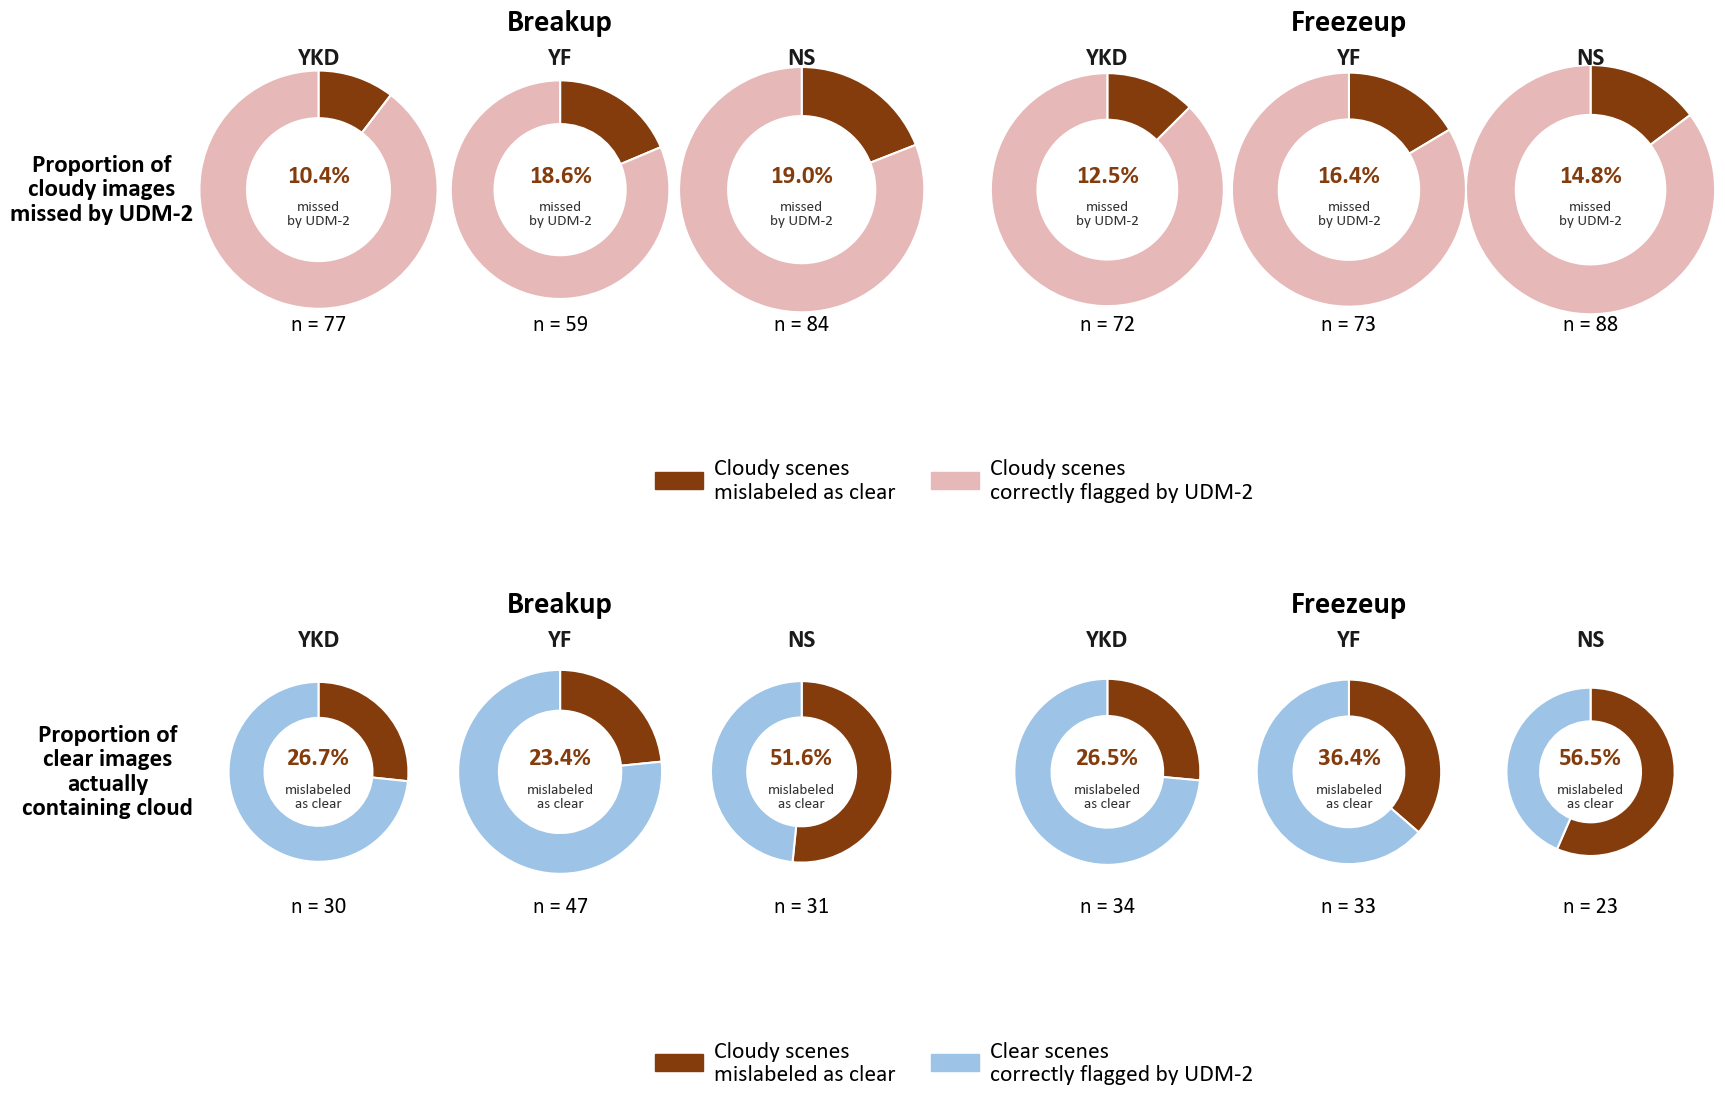

In [4]:
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
import matplotlib.gridspec as gridspec
import pandas as pd
import xml.etree.ElementTree as ET
from pathlib import Path
import os

# ============================================================
# CONFIGURATION
# ============================================================
CLOUD_THRESHOLD = 0.5
BASE_DIR = r"E:\planetscope_lake_ice\Data\Input\PS Cloud Validation"
SITE_DIRS   = ['YKD_FullCloud', 'YF_FullCloud', 'NS_FullCloud']
SITE_LABELS = ['YKD', 'YF', 'NS']
SEASONS     = ['Breakup', 'Freezeup']

# ============================================================
# STYLING & SIZING (Journal Optimized)
# ============================================================
SITE_FONTSIZE      = 18
SEASON_FONTSIZE    = 22
N_LABEL_FONTSIZE   = 16  
PCT_LABEL_FONTSIZE = 18  
PCT_SUB_FONTSIZE   = 11  
LEGEND_FONTSIZE    = 17  # Bumped up by 3
ROW_LABEL_FONTSIZE = 18
        
COLOR_DARK_RED  = '#843C0C'#'#8B0000'
COLOR_LIGHT_RED = "#E6B8B7"
COLOR_BLUE      = '#9DC3E6' #'#A8C8DC'

# ============================================================
# DATA-PROCESSING HELPERS
# ============================================================
def find_xml_file(base_path, datetime_str):
    base_path = Path(base_path)
    for xml_file in base_path.rglob('*.xml'):
        if datetime_str in xml_file.name: return xml_file
    return None

def extract_cloud_percentage(xml_path):
    try:
        tree = ET.parse(xml_path)
        root = tree.getroot()
        for elem in root.iter():
            if 'cloudCoverPercentage' in elem.tag: return float(elem.text)
        return None
    except Exception: return None

def extract_datetime_from_image(image_name):
    parts = image_name.split('_')
    return f"{parts[0]}_{parts[1]}" if len(parts) >= 2 else None

def process_site_data(site_name, season_filter, cloud_threshold):
    csv_path = os.path.join(BASE_DIR, site_name, 'cloud_analysis_output.csv')
    site_dir = os.path.join(BASE_DIR, site_name)
    if not os.path.exists(csv_path): return {'clear_clear': 0, 'clear_cloudy': 0, 'cloudy_cloudy': 0, 'cloudy_clear': 0}
    
    df = pd.read_csv(csv_path)
    df = df[df['season'] == season_filter].copy()
    df['udm2_label'] = None
    df['manual_binary'] = None

    for idx, row in df.iterrows():
        dt_str = extract_datetime_from_image(row['image'])
        if not dt_str: continue
        xml_file = find_xml_file(site_dir, dt_str)
        if not xml_file: continue
        cloud_pct = extract_cloud_percentage(xml_file)
        if cloud_pct is None: continue
        
        df.at[idx, 'udm2_label'] = 'cloudy' if cloud_pct > cloud_threshold else 'clear'
        m_label = row['label']
        if m_label in ['cloudy', 'very_cloudy']: df.at[idx, 'manual_binary'] = 'cloudy'
        elif m_label == 'no_clouds': df.at[idx, 'manual_binary'] = 'clear'

    df = df.dropna(subset=['udm2_label', 'manual_binary'])
    return {
        'clear_clear':   len(df[(df['udm2_label'] == 'clear')  & (df['manual_binary'] == 'clear')]),
        'clear_cloudy':  len(df[(df['udm2_label'] == 'clear')  & (df['manual_binary'] == 'cloudy')]),
        'cloudy_cloudy': len(df[(df['udm2_label'] == 'cloudy') & (df['manual_binary'] == 'cloudy')]),
        'cloudy_clear':  len(df[(df['udm2_label'] == 'cloudy') & (df['manual_binary'] == 'clear')]),
    }

# ============================================================
# DATA PREP
# ============================================================
DATA_CLOUDY = {s: {} for s in SEASONS}
DATA_CLEAR  = {s: {} for s in SEASONS}

for season in SEASONS:
    for site_dir, site_label in zip(SITE_DIRS, SITE_LABELS):
        counts = process_site_data(site_dir, season, CLOUD_THRESHOLD)
        DATA_CLOUDY[season][site_label] = {'missed': counts['clear_cloudy'], 'correct': counts['cloudy_cloudy']}
        DATA_CLEAR[season][site_label]  = {'cloudy': counts['clear_cloudy'], 'clear': counts['clear_clear']}

all_totals = [d[k] for s in SEASONS for d_set in [DATA_CLOUDY[s], DATA_CLEAR[s]] for d in d_set.values() for k in d]
MAX_N = max(all_totals) if all_totals else 1
MIN_R, MAX_R, EXP = 0.53, 1.33, 0.55

def get_radius(n):
    return MIN_R + (MAX_R - MIN_R) * (n / MAX_N) ** EXP

# ============================================================
# LAYOUT
# ============================================================
fig = plt.figure(figsize=(18, 14.0)) 
LEFT_MARGIN = 0.15 

# Narrowed hspace to pull rows together
outer = gridspec.GridSpec(4, 1, figure=fig, height_ratios=[1, 0.05, 1, 0.05], 
                          hspace=0.18, left=LEFT_MARGIN, right=0.98, top=0.90, bottom=0.1)

def make_inner_gs(outer_cell):
    # Narrowed horizontal spacing between season blocks
    return gridspec.GridSpecFromSubplotSpec(1, 7, subplot_spec=outer_cell, 
                                            width_ratios=[1, 1, 1, 0.2, 1, 1, 1], wspace=0.1)

gs_top = make_inner_gs(outer[0])
gs_bot = make_inner_gs(outer[2])

# ============================================================
# DRAWING
# ============================================================
def draw_row(gs, row_data, slice_keys, colors, internal_sub):
    axes_by_season = {}
    for season in SEASONS:
        col_off = 0 if season == 'Breakup' else 4
        axs = []
        for i, site in enumerate(SITE_LABELS):
            ax = fig.add_subplot(gs[0, col_off + i])
            ax.set_aspect('equal'); ax.set_xlim(-1.5, 1.5); ax.set_ylim(-1.5, 1.5); ax.axis('off')
            axs.append(ax)

            d = row_data[season][site]
            minor, major = d[slice_keys[0]], d[slice_keys[1]]
            total = minor + major
            pct = (minor / total * 100) if total else 0
            r = get_radius(total)

            ax.pie([minor, major], colors=list(colors), startangle=90, counterclock=False,
                    radius=r, wedgeprops=dict(width=r*0.4, edgecolor='white', linewidth=1.5))

            ax.text(0, 0.15, f"{pct:.1f}%", ha='center', va='center', fontsize=PCT_LABEL_FONTSIZE, fontweight='bold', color=COLOR_DARK_RED)
            ax.text(0, -0.28, internal_sub, ha='center', va='center', fontsize=PCT_SUB_FONTSIZE, color='#333333', linespacing=1.1)
            ax.set_title(site, fontsize=SITE_FONTSIZE, fontweight='bold', pad=10)
        axes_by_season[season] = axs
    return axes_by_season

top_axes = draw_row(gs_top, DATA_CLOUDY, ('missed', 'correct'), (COLOR_DARK_RED, COLOR_LIGHT_RED), "missed\nby UDM-2")
bot_axes = draw_row(gs_bot, DATA_CLEAR, ('cloudy', 'clear'), (COLOR_DARK_RED, COLOR_BLUE), "mislabeled\nas clear")

# ============================================================
# TEXT & LEGENDS
# ============================================================
for axes_by_season, row_data, skeys in [(top_axes, DATA_CLOUDY, ('missed', 'correct')), (bot_axes, DATA_CLEAR, ('cloudy', 'clear'))]:
    for season, axs in axes_by_season.items():
        p = [ax.get_position() for ax in axs]
        fig.text((min(pos.x0 for pos in p) + max(pos.x1 for pos in p))/2, max(pos.y1 for pos in p) + 0.03, 
                  season, ha='center', va='bottom', fontsize=SEASON_FONTSIZE, fontweight='bold')
        for ax, site in zip(axs, SITE_LABELS):
            total = sum(row_data[season][site].values())
            pos = ax.get_position()
            fig.text(pos.x0 + pos.width/2, pos.y0 - 0.01, f"n = {total}", ha='center', va='top', fontsize=N_LABEL_FONTSIZE)

def add_v_label(axes_dict, text, gap=0.008):
    all_p = [ax.get_position() for axs in axes_dict.values() for ax in axs]
    x_right = min(p.x0 for p in all_p) - gap          # just left of the first chart
    y_mid   = (min(p.y0 for p in all_p) + max(p.y1 for p in all_p)) / 2
    fig.text(x_right, y_mid, text, ha='right', va='center',
             fontsize=ROW_LABEL_FONTSIZE, fontweight='bold', rotation=0,
             multialignment='center', linespacing=1.2)

add_v_label(top_axes, "Proportion of\ncloudy images\nmissed by UDM-2")
add_v_label(bot_axes, "Proportion of\nclear images\nactually\ncontaining cloud")

def add_leg(idx, handles):
    ax_leg = fig.add_subplot(outer[idx]); ax_leg.axis('off')
    ax_leg.legend(handles=handles, loc='center', ncol=2, frameon=False, fontsize=LEGEND_FONTSIZE,
                  columnspacing=1.5, handletextpad=0.5)

# Original legend text restored
add_leg(1, [mpatches.Patch(color=COLOR_DARK_RED, label='Cloudy scenes\nmislabeled as clear'), 
            mpatches.Patch(color=COLOR_LIGHT_RED, label='Cloudy scenes\ncorrectly flagged by UDM-2')])

add_leg(3, [mpatches.Patch(color=COLOR_DARK_RED, label='Cloudy scenes\nmislabeled as clear'), 
            mpatches.Patch(color=COLOR_BLUE, label='Clear scenes\ncorrectly flagged by UDM-2')])

plt.show()

# Section 4.1: Mean annual ice duration and standard deviations

In [7]:
import pandas as pd
import numpy as np
from pathlib import Path
import warnings

# Configuration
ROOT = Path(r"C:\Users\nj142\Desktop\Time Series")
SITES = ["NS", "YF", "YKD"]
DATASETS = [("S2", "Sentinel-2"), ("PS", "PlanetScope")]

def load_dates(site, event, dataset_key):
    """Loads event dates and returns a dataframe."""
    path = ROOT / dataset_key / event / f"{site}_{event.lower()}_dates.csv"
    if not path.exists():
        return pd.DataFrame(columns=["lake_id", f"{event.lower()}_date"])
    
    with warnings.catch_warnings():
        warnings.simplefilter("ignore")
        df = pd.read_csv(path, low_memory=False)
        
    date_col = f"{event.lower()}_date"
    df[date_col] = pd.to_datetime(df[date_col], format="mixed", errors="coerce")
    df = df.dropna(subset=[date_col]).copy()
    df["lake_id"] = pd.to_numeric(df["lake_id"], errors="coerce").astype("Int64").astype(str)
    
    return df[["lake_id", date_col]]

def calculate_ice_duration():
    records = []
    
    for site in SITES:
        for ds_key, ds_name in DATASETS:
            # Load breakup and freezeup dates
            bu = load_dates(site, "Breakup", ds_key)
            fu = load_dates(site, "Freezeup", ds_key)
            
            if bu.empty or fu.empty:
                continue
            
            # Define 'Ice Year' based on breakup year. 
            # Freeze-up from Year Y-1 belongs to Ice Year Y.
            bu["ice_year"] = bu["breakup_date"].dt.year
            fu["ice_year"] = fu["freezeup_date"].dt.year + 1
            
            # Merge on lake_id and the aligned Ice Year
            merged = pd.merge(bu, fu, on=["lake_id", "ice_year"], how="inner")
            
            # Calculate duration in exact days
            merged["ice_duration_days"] = (merged["breakup_date"] - merged["freezeup_date"]).dt.days
            
            # Drop negative or illogical durations if any bad data exists
            merged = merged[merged["ice_duration_days"] > 0].copy()
            
            merged["site"] = site
            merged["dataset"] = ds_name
            records.append(merged)
            
    if not records:
        print("No valid paired dates found for duration calculation.")
        return

    all_durations = pd.concat(records, ignore_index=True)
    
    print("=" * 80)
    print("MEAN ICE DURATION PER SITE (Fall 2019 - Spring 2025)")
    print("=" * 80)
    print(f"{'Site':<6}{'Dataset':<14}{'N (Lakes)':<12}{'Mean (Days)':<14}{'Std Dev':<10}{'Min':<6}{'Max':<6}")
    print("-" * 80)
    
    # Group and calculate stats
    stats = all_durations.groupby(["site", "dataset"])["ice_duration_days"].agg(
        ['count', 'mean', 'std', 'min', 'max']
    ).reset_index()
    
    for _, row in stats.iterrows():
        print(f"{row['site']:<6}{row['dataset']:<14}{int(row['count']):<12}{row['mean']:<14.1f}"
              f"{row['std']:<10.1f}{int(row['min']):<6}{int(row['max']):<6}")
    print("=" * 80)

if __name__ == "__main__":
    calculate_ice_duration()

MEAN ICE DURATION PER SITE (Fall 2019 - Spring 2025)
Site  Dataset       N (Lakes)   Mean (Days)   Std Dev   Min   Max   
--------------------------------------------------------------------------------
NS    PlanetScope   11990       248.6         7.9       223   271   
NS    Sentinel-2    11045       253.3         8.3       226   290   
YF    PlanetScope   7911        213.2         9.9       182   281   
YF    Sentinel-2    9826        210.2         8.9       174   275   
YKD   PlanetScope   39134       196.2         9.9       162   253   
YKD   Sentinel-2    39914       198.9         11.6      156   255   


# Fig 6. Timing of Ice-on and Ice-off

Loading data…


C:\Users\nj142\AppData\Local\Temp\ipykernel_31612\3085272699.py:68: DtypeWarning: Columns (129,130,133,134,137,138,141,142,145,146,149,150) have mixed types. Specify dtype option on import or set low_memory=False.
  df = pd.read_csv(path)
C:\Users\nj142\AppData\Local\Temp\ipykernel_31612\3085272699.py:68: DtypeWarning: Columns (85,86,89,90,93,94) have mixed types. Specify dtype option on import or set low_memory=False.
  df = pd.read_csv(path)
C:\Users\nj142\AppData\Local\Temp\ipykernel_31612\3085272699.py:68: DtypeWarning: Columns (79,80,83,84,87,88,91,92) have mixed types. Specify dtype option on import or set low_memory=False.
  df = pd.read_csv(path)
C:\Users\nj142\AppData\Local\Temp\ipykernel_31612\3085272699.py:68: DtypeWarning: Columns (39,40,43,44) have mixed types. Specify dtype option on import or set low_memory=False.
  df = pd.read_csv(path)
C:\Users\nj142\AppData\Local\Temp\ipykernel_31612\3085272699.py:68: DtypeWarning: Columns (173,174,177,178,181,182) have mixed types. 


── Figure: Ridgeline KDE (per-lake median across years) ──


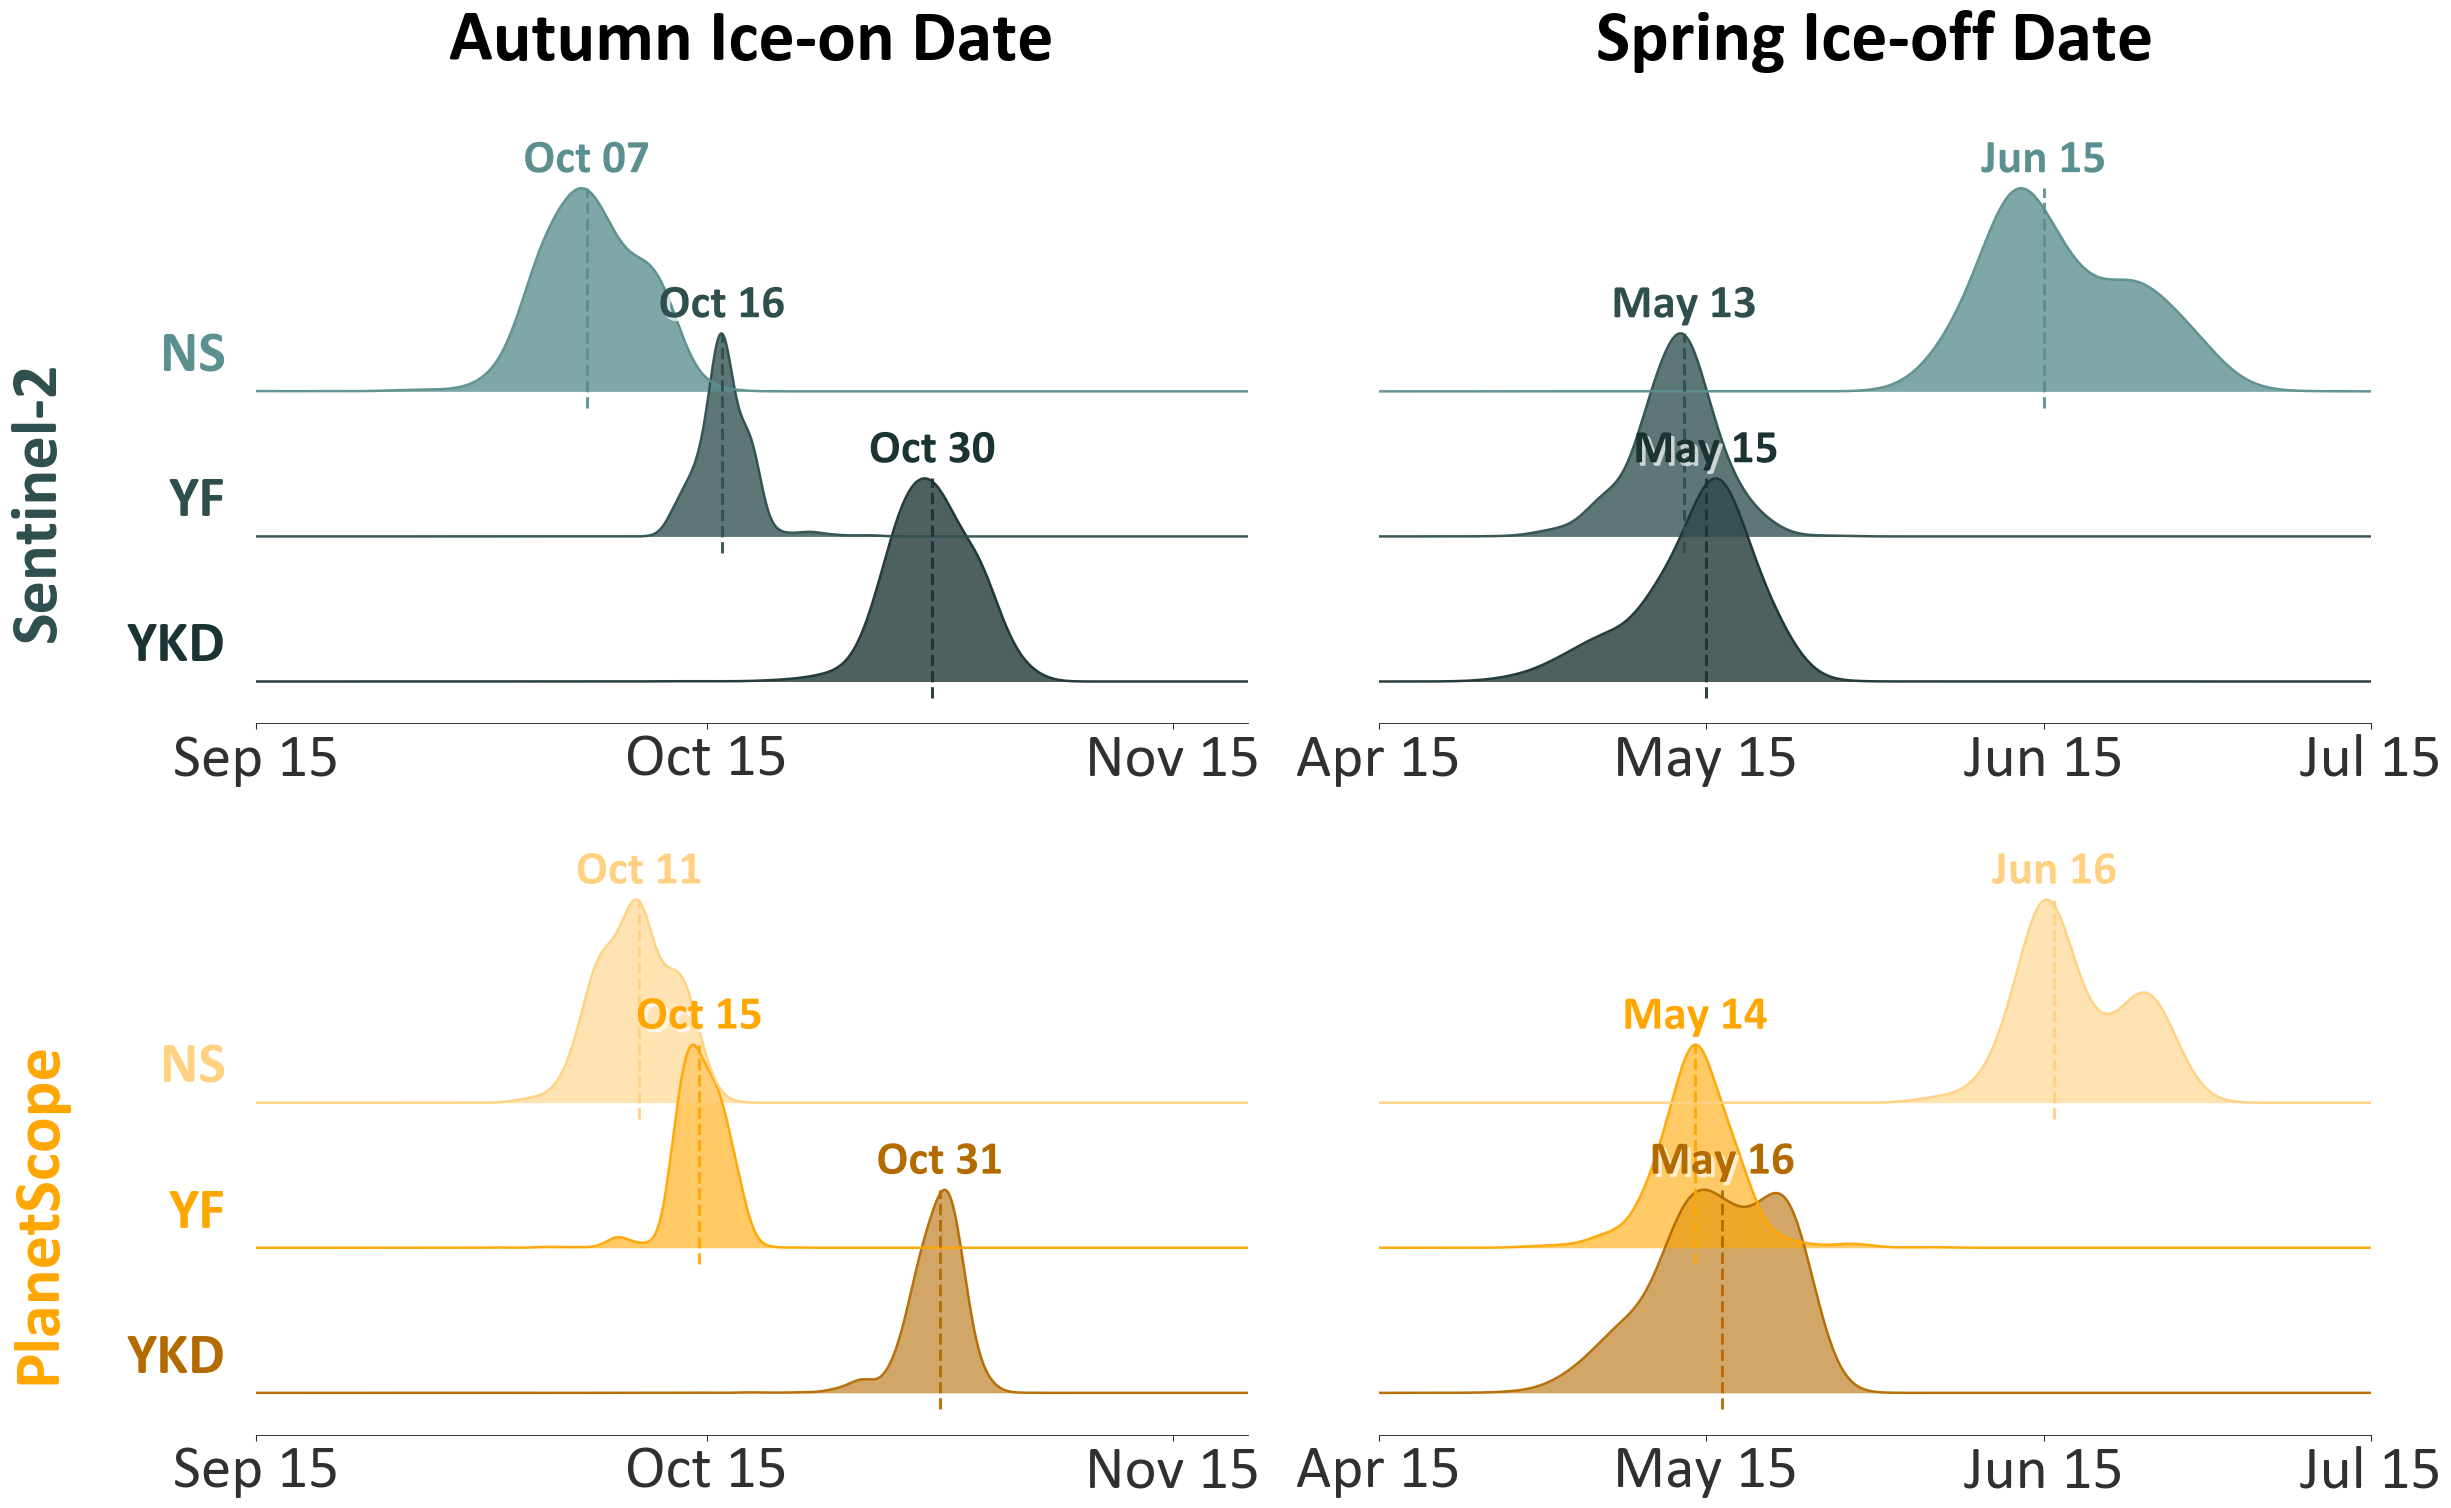


Sample sizes per panel (n lakes, for figure caption):
  Sentinel-2   Freezeup   n = 15,758
  Sentinel-2   Breakup    n = 15,885
  PlanetScope  Freezeup   n = 15,602
  PlanetScope  Breakup    n = 15,797
  shown  ridgeline_KDE (lakes, centre = median)

  saved  mean_DOY_yearly.csv  (84 rows)
  saved  lake_median_DOY.csv

1. PER-SITE SUMMARY  (DOY = day of year; calendar date shown for the mean)

--- BREAKUP ---
Site Dataset         N   Mean   (Date)   Med   Std  Min  Max  Range
NS   Sentinel-2  39582  167.7   Jun 17 167.0   8.1  141  209     68
NS   PlanetScope 32636  167.3   Jun 16 167.0   6.2  142  181     39
YF   Sentinel-2  12889  132.9   May 13 133.0   7.5  107  195     88
YF   PlanetScope 12664  135.0   May 15 134.0   7.8  113  176     63
YKD  Sentinel-2  57601  134.9   May 15 135.0  10.3   96  175     79
YKD  PlanetScope 55654  137.0   May 17 137.0   9.3   94  174     80

--- FREEZEUP ---
Site Dataset         N   Mean   (Date)   Med   Std  Min  Max  Range
NS   Sentinel-2  14732  

In [38]:
from pathlib import Path
from datetime import datetime, timedelta
from itertools import combinations

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
import matplotlib.patheffects as pe
from scipy import stats

# ============================================================================
# FONT — Calibri everywhere, all sizes ×2.5
# ============================================================================
plt.rcParams["font.family"]      = "Calibri"
plt.rcParams["mathtext.fontset"] = "dejavusans"
plt.rcParams["font.size"]        = 44        # +4
plt.rcParams["axes.titlesize"]   = 49        # +4
plt.rcParams["axes.labelsize"]   = 46        # +4
plt.rcParams["xtick.labelsize"]  = 44        # +4
plt.rcParams["ytick.labelsize"]  = 44        # +4
plt.rcParams["legend.fontsize"]  = 54        # +4
plt.rcParams["figure.titlesize"] = 64        # +4

# ============================================================================
# CONFIG
# ============================================================================
ROOT       = Path(r"C:\Users\nj142\Desktop\Time Series")
OUTPUT_DIR = ROOT / "output"
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

SITES    = ["NS", "YF", "YKD"]
METRICS  = ["breakup", "freezeup"]
DATASETS = [("S2", "Sentinel-2"), ("PS", "PlanetScope")]
YEARS    = list(range(2019, 2026))

def csv_path(site: str, metric: str, dataset: str) -> Path:
    return ROOT / dataset / metric.capitalize() / f"{site}_{metric}_dates.csv"

PLANET_COLOR   = "#ffa600"
SENTINEL_COLOR = "#2f4f4f"
COLORS         = {"S2": SENTINEL_COLOR, "PS": PLANET_COLOR}

# Per-dataset site shades:
#   Sentinel-2 (dark slate #2f4f4f): YKD = darkest, YF = base, NS = lightest
#   PlanetScope     (orange    #ffa600):  YKD = darkest, YF = base, NS = lightest
SITE_SHADES = {
    "S2": {
        "YKD": "#1c3333",   # darker slate
        "YF":  "#2f4f4f",   # base Sentinel-2 colour
        "NS":  "#5c8f8f",   # lighter slate
    },
    "PS": {
        "YKD": "#b36b00",   # darker orange
        "YF":  "#ffa600",   # base PlanetScope colour
        "NS":  "#ffd180",   # lighter orange
    },
}

# ============================================================================
# DATA
# ============================================================================
def load_doy(path: Path, metric: str) -> pd.DataFrame:
    if not path.exists():
        print(f"  [missing] {path}")
        return pd.DataFrame(columns=["lake_id", "year", "doy"])

    df = pd.read_csv(path)
    date_col = f"{metric}_date"

    df[date_col] = pd.to_datetime(df[date_col], errors="coerce")
    df = df.dropna(subset=[date_col]).copy()

    df["doy"]  = df[date_col].dt.dayofyear
    df["year"] = df[date_col].dt.year

    return df[["lake_id", "year", "doy"]]


def load_all():
    """Return (means dict, tidy yearly-means DataFrame, long per-observation DataFrame)."""
    means   = {}
    rows    = []
    records = []

    for site in SITES:
        for metric in METRICS:
            for ds_key, ds_name in DATASETS:
                df = load_doy(csv_path(site, metric, ds_key), metric)

                df_tagged = df.copy()
                df_tagged["site"]    = site
                df_tagged["metric"]  = metric
                df_tagged["dataset"] = ds_name

                records.append(df_tagged)

                m = df.groupby("year")["doy"].mean().to_dict()
                c = df.groupby("year")["doy"].count().to_dict()

                means[(site, metric, ds_key)] = m

                for y in YEARS:
                    rows.append({
                        "site":           site,
                        "metric":         metric,
                        "dataset":        ds_name,
                        "year":           y,
                        "mean_doy":       round(m.get(y, float("nan")), 2),
                        "n_observations": int(c.get(y, 0)),
                    })

    tidy     = pd.DataFrame(rows)
    all_data = pd.concat(records, ignore_index=True)
    all_data["doy"] = pd.to_numeric(all_data["doy"], errors="coerce")

    return means, tidy, all_data

# ============================================================================
# HELPERS
# ============================================================================
def doy_to_date(doy):
    if np.isnan(doy):
        return "n/a"
    return (datetime(2023, 1, 1) + timedelta(days=int(round(doy)) - 1)).strftime("%b %d")


def lake_medians(all_data: pd.DataFrame) -> pd.DataFrame:
    """One row per lake: median DOY across all years (per site/metric/dataset)."""
    return (
        all_data
        .groupby(["site", "metric", "dataset", "lake_id"], as_index=False)["doy"]
        .median()
    )

# ============================================================================
# FIGURE — ridgeline KDE of per-lake medians
#
#   Layout : 2 rows (Sentinel-2 / PlanetScope)  ×  2 cols (freeze-up / break-up)
#   Column headers  : "Autumn Ice-on Date" | "Spring Ice-off Date"  (top row only)
#   Row labels      : "Sentinel-2" | "PlanetScope"     (left border, vertical,
#                     just left of and centred on the YKD/YF/NS site labels)
#   X-axes          : date ticks only, no axis titles
#   Top row alpha   : 0.78  (slightly darker than bottom row's 0.60)
#
#   centre_stat : "median" → dashed line at median of values (per-lake medians)
#                 "mean"   → dashed line at mean of values
#   unit        : label for the sample-size printout ("lakes" / "observations")
# ============================================================================
def plot_ridgeline(all_data: pd.DataFrame,
                   centre_stat: str = "median",
                   unit: str = "lakes"):
    ds_order     = [("S2", "Sentinel-2"), ("PS", "PlanetScope")]
    metric_order = ["freezeup", "breakup"]
    overlap      = 1.4
    ROW_ALPHA    = [0.78, 0.60]

    # Row-label colours = central (YF / base) shade of each dataset
    ROW_COLORS = {
        "Sentinel-2": SENTINEL_COLOR,   # #2f4f4f
        "PlanetScope":     PLANET_COLOR,     # #ffa600
    }

    # Row-label font size and the gap (in character heights) between the
    # row label and the site labels. Smaller gap → closer to the axes.
    ROW_LABEL_FS  = 48
    ROW_LABEL_GAP = 0.9

    # Fixed calendar-date ticks per metric.
    METRIC_TICK_DAYS = {
        "freezeup": [(9, 15), (10, 15), (11, 15)],          # Sep 15 → Nov 15
        "breakup":  [(4, 15), (5, 15), (6, 15), (7, 15)],   # Apr 15 → Jul 15
    }
    METRIC_X_RANGE = {
        "freezeup": ((9, 15), (11, 20)),  # Sep 15 → Nov 20
        "breakup":  ((4, 15), (7, 15)),   # Apr 15 → Jul 15
    }
    METRIC_TITLE = {
        "breakup":  "Spring Ice-off Date",
        "freezeup": "Autumn Ice-on Date",
    }

    REF_YEAR = 2023  # non-leap reference for DOY mapping

    fig, axes = plt.subplots(
        len(ds_order), len(metric_order),
        figsize=(26, 18),
        sharex=False, sharey=False,
    )

    # Pre-compute shared x-range (and ticks) per column so both rows match.
    column_x_ranges = {}
    column_ticks    = {}
    for metric in metric_order:
        tick_doys, tick_labels = [], []
        for month, day in METRIC_TICK_DAYS[metric]:
            d = datetime(REF_YEAR, month, day)
            tick_doys.append(d.timetuple().tm_yday)
            tick_labels.append(d.strftime("%b %d"))

        (lo_m, lo_d), (hi_m, hi_d) = METRIC_X_RANGE[metric]
        lo_doy = datetime(REF_YEAR, lo_m, lo_d).timetuple().tm_yday
        hi_doy = datetime(REF_YEAR, hi_m, hi_d).timetuple().tm_yday

        column_x_ranges[metric] = (lo_doy, hi_doy)
        column_ticks[metric]    = (tick_doys, tick_labels)

    n_per_panel = []
    site_label_texts = {row: [] for row in range(len(ds_order))}

    for row, (ds_key, ds_name) in enumerate(ds_order):
        alpha = ROW_ALPHA[row]

        for col, metric in enumerate(metric_order):
            ax  = axes[row, col]
            sub = all_data[
                (all_data.metric  == metric) &
                (all_data.dataset == ds_name)
            ].copy()

            x_lo, x_hi = column_x_ranges[metric]
            x = np.linspace(x_lo, x_hi, 600)

            if sub.empty:
                ax.text(0.5, 0.5, "No data",
                        ha="center", va="center", transform=ax.transAxes)
                ax.set_xlim(x_lo, x_hi)
                continue

            all_doys = sub["doy"].dropna()
            n_per_panel.append((ds_name, metric.capitalize(), len(all_doys)))

            for i, site in enumerate(reversed(SITES)):   # bottom → top
                vals = sub[sub.site == site]["doy"].dropna().values.astype(float)
                if len(vals) < 3 or np.ptp(vals) == 0:
                    continue

                kde    = stats.gaussian_kde(vals, bw_method=0.4)
                y_raw  = kde(x)
                y_nrm  = y_raw / y_raw.max()
                offset = i / overlap
                color  = SITE_SHADES[ds_key][site]

                ax.fill_between(x, offset, offset + y_nrm,
                                color=color, alpha=alpha, linewidth=0)
                ax.plot(x, offset + y_nrm,
                        color=color, linewidth=1.8, alpha=0.95)

                # Site labels only in the left column (rows are shared), so
                # the right column needs no left margin.
                if col == 0:
                    t = ax.text(x_lo - 2, offset + 0.05, site,
                                ha="right", va="bottom",
                                fontsize=42, color=color, fontweight="bold")
                    site_label_texts[row].append(t)

                # ── Centre line (median of lake medians, or mean) ──
                centre_doy = np.median(vals) if centre_stat == "median" else vals.mean()

                ax.plot(
                    [centre_doy, centre_doy],
                    [offset - 0.08, offset + 1.0],          # extend line to ridge top
                    color=color, linestyle="--", linewidth=2.2, alpha=0.92,
                    zorder=5,
                )

                ax.text(
                    centre_doy,
                    offset + 1.0 + 0.04,                    # anchor label to ridge top
                    doy_to_date(centre_doy),
                    ha="center", va="bottom",
                    fontsize=34, color=color, fontweight="bold",
                    zorder=6,
                    path_effects=[
                        pe.SimplePatchShadow(
                            offset=(2.5, -2.5),
                            shadow_rgbFace="white",
                            alpha=0.7,
                            rho=0.4,
                        ),
                        pe.Normal(),
                    ],
                )

            # ── X-axis: fixed date ticks, hard-clipped to that range ────
            tick_doys, tick_labels = column_ticks[metric]
            ax.set_xlim(x_lo, x_hi)
            ax.set_xticks(tick_doys)
            ax.set_xticklabels(tick_labels, rotation=0, ha="center")
            ax.set_yticks([])
            ax.set_xlabel("")

            # ── Column titles ───────────────────────────────────────────
            if row == 0:
                ax.set_title(
                    METRIC_TITLE[metric],
                    fontsize=52, fontweight="bold", color="black",
                    pad=74,
                )

            for sp in ("top", "right", "left"):
                ax.spines[sp].set_visible(False)

    fig.tight_layout(rect=[0.06, 0.10, 1.0, 1.0], w_pad=0.5)

    # ── Row labels ─────────────────────────────────────────────────────
    # Placed relative to the actual rendered site labels (YKD / YF / NS):
    # just to their left, and centred on their vertical span.
    fig.canvas.draw()
    to_fig = fig.transFigure.inverted()
    gap_px = ROW_LABEL_GAP * ROW_LABEL_FS * fig.dpi / 72

    for row, (_, ds_name) in enumerate(ds_order):
        ax0   = axes[row, 0]
        texts = site_label_texts[row]
        if texts:
            # Centre vertically on the span of the YKD / YF / NS labels.
            extents = [t.get_window_extent() for t in texts]
            left_px = min(e.x0 for e in extents)
            y_px    = (min(e.y0 for e in extents) + max(e.y1 for e in extents)) / 2
        else:
            bbox    = ax0.get_window_extent()
            left_px = bbox.x0
            y_px    = (bbox.y0 + bbox.y1) / 2

        x_fig, y_fig = to_fig.transform((left_px - gap_px, y_px))

        fig.text(
            x_fig, y_fig, ds_name,
            ha="right", va="center",
            rotation=90,
            fontsize=ROW_LABEL_FS, fontweight="bold",
            color=ROW_COLORS[ds_name],
        )

    plt.show()

    print(f"\nSample sizes per panel (n {unit}, for figure caption):")
    for ds_name, metric_cap, n in n_per_panel:
        print(f"  {ds_name:<12} {metric_cap:<10} n = {n:,}")

    print(f"  shown  ridgeline_KDE ({unit}, centre = {centre_stat})")

# ============================================================================
# FIGURE 2 — annual box plots  (same 1×3 layout as original, per metric)
# ============================================================================
def plot_annual_boxplots(all_data: pd.DataFrame):
    """
    Two figures (breakup / freezeup), each with 3 panels (YKD / YF / NS).
    Each year gets two side-by-side vertical box plots — one S2, one PlanetScope.
    ylim is computed globally across ALL sites for this metric.
    """
    half_gap = 0.22
    box_w    = 0.32

    for metric in METRICS:
        fig, axes = plt.subplots(1, 3, figsize=(16, 5.2), sharey=True)

        all_metric_vals = all_data[
            all_data.metric == metric
        ]["doy"].dropna().values

        if len(all_metric_vals):
            global_lo  = all_metric_vals.min()
            global_hi  = all_metric_vals.max()
            global_pad = max(3, (global_hi - global_lo) * 0.08)
            global_ylim = (global_lo - global_pad, global_hi + global_pad)
        else:
            global_ylim = None

        for ax, site in zip(axes, SITES):
            sub = all_data[
                (all_data.site   == site) &
                (all_data.metric == metric)
            ]

            for ds_key, ds_name in DATASETS:
                color = COLORS[ds_key]
                dx = -half_gap if ds_key == "S2" else +half_gap

                positions = []
                box_data  = []

                for year in YEARS:
                    vals = sub[
                        (sub.dataset == ds_name) &
                        (sub.year    == year)
                    ]["doy"].dropna().values

                    if len(vals) >= 2:
                        positions.append(year + dx)
                        box_data.append(vals)

                if not box_data:
                    continue

                bp = ax.boxplot(
                    box_data,
                    positions=positions,
                    widths=box_w,
                    patch_artist=True,
                    notch=False,
                    showfliers=True,
                    manage_ticks=False,
                    medianprops=dict(color="white", linewidth=2.0),
                )

                for patch in bp["boxes"]:
                    patch.set_facecolor(color)
                    patch.set_alpha(0.75)
                    patch.set_linewidth(0)

                for element in ("whiskers", "caps"):
                    for line in bp[element]:
                        line.set_color(color)
                        line.set_linewidth(1.4)

                for flier in bp["fliers"]:
                    flier.set(marker="o", markerfacecolor=color,
                              markeredgewidth=0, alpha=0.55, markersize=4)

            ax.set_xticks(YEARS)
            ax.set_xticklabels(YEARS, rotation=45, ha="right", fontsize=13)
            ax.set_xlim(YEARS[0] - 0.65, YEARS[-1] + 0.65)
            ax.set_xlabel("Year", fontsize=15)
            ax.set_title(rf"$\bf{{{site}}}$", fontsize=17)
            ax.grid(True, axis="y", alpha=0.25, linewidth=0.6)

            if global_ylim:
                ax.set_ylim(global_ylim)

            for sp in ("top", "right"):
                ax.spines[sp].set_visible(False)

        axes[0].set_ylabel("Day of Year", fontsize=17)

        handles = [
            mpatches.Patch(facecolor=COLORS[ds_key], alpha=0.75, label=ds_name)
            for ds_key, ds_name in DATASETS
        ]
        fig.legend(
            handles, [ds_name for _, ds_name in DATASETS],
            loc="upper center", bbox_to_anchor=(0.5, -0.06),
            ncol=2, frameon=False, fontsize=18,
        )

        fig.suptitle(f"{metric.capitalize()} - Annual DOY Distribution",
                     fontsize=22, y=1.02)
        fig.tight_layout()
        plt.show()
        print(f"  shown  annual_boxplots_{metric}")

# ============================================================================
# STATS
# ============================================================================
def print_stats(all_data: pd.DataFrame):
    def get(site, metric, dataset):
        return all_data[
            (all_data.site    == site) &
            (all_data.metric  == metric) &
            (all_data.dataset == dataset)
        ]["doy"].values

    print("=" * 84)
    print("1. PER-SITE SUMMARY  (DOY = day of year; calendar date shown for the mean)")
    print("=" * 84)

    for metric in METRICS:
        print(f"\n--- {metric.upper()} ---")
        print(f"{'Site':<5}{'Dataset':<12}{'N':>5}{'Mean':>7}{'(Date)':>9}"
              f"{'Med':>6}{'Std':>6}{'Min':>5}{'Max':>5}{'Range':>7}")

        for site in SITES:
            for _, ds_name in DATASETS:
                d = get(site, metric, ds_name)
                if len(d) == 0:
                    continue
                print(
                    f"{site:<5}{ds_name:<12}{len(d):>5}"
                    f"{d.mean():>7.1f}{doy_to_date(d.mean()):>9}"
                    f"{np.median(d):>6.1f}{d.std():>6.1f}"
                    f"{int(d.min()):>5d}{int(d.max()):>5d}"
                    f"{int(d.max()-d.min()):>7d}"
                )

    print("\n" + "=" * 84)
    print("2. INTER-SITE TEST  (do YKD / YF / NS differ in mean timing?)")
    print("=" * 84)
    print("ANOVA assumes normality; Kruskal-Wallis does not. p < 0.05 → sites differ.\n")

    for metric in METRICS:
        for _, ds_name in DATASETS:
            groups = [get(s, metric, ds_name) for s in SITES]
            if any(len(g) < 2 for g in groups):
                continue
            F, p_a  = stats.f_oneway(*groups)
            H, p_kw = stats.kruskal(*groups)
            means_  = {s: g.mean() for s, g in zip(SITES, groups)}
            spread  = max(means_.values()) - min(means_.values())
            print(
                f"{metric:<9}{ds_name:<12} ANOVA F={F:5.2f} p={p_a:.4f}   "
                f"KW H={H:5.2f} p={p_kw:.4f}   "
                f"site-mean spread = {spread:5.1f} d  "
                f"({', '.join(f'{s}:{means_[s]:.0f}' for s in SITES)})"
            )

    print("\n" + "=" * 84)
    print("3. PAIRWISE SITE DIFFERENCES  (Δ = first - second, in days)")
    print("=" * 84)
    print("Positive Δ → first site's event happens later in the year.  * = p < 0.05\n")

    for metric in METRICS:
        for _, ds_name in DATASETS:
            print(f"{metric:<9} {ds_name}")
            for s1, s2 in combinations(SITES, 2):
                a, b = get(s1, metric, ds_name), get(s2, metric, ds_name)
                if len(a) < 2 or len(b) < 2:
                    continue
                delta = a.mean() - b.mean()
                try:
                    _, p = stats.mannwhitneyu(a, b, alternative="two-sided")
                except ValueError:
                    p = np.nan
                sig = " *" if (not np.isnan(p) and p < 0.05) else ""
                print(f"   {s1} − {s2}:  Δ = {delta:+6.1f} d   p = {p:.4f}{sig}")
            print()

    print("=" * 84)
    print("4. SENTINEL-2 vs PLANET  (per site / metric)")
    print("=" * 84)
    print("Δ = S2 mean - PlanetScope mean.  Small |Δ| + high p → sensors agree.\n")

    for metric in METRICS:
        for site in SITES:
            s2 = get(site, metric, "Sentinel-2")
            ps = get(site, metric, "PlanetScope")
            if len(s2) < 2 or len(ps) < 2:
                continue
            delta = s2.mean() - ps.mean()
            try:
                _, p = stats.mannwhitneyu(s2, ps, alternative="two-sided")
            except ValueError:
                p = np.nan
            sig = " *" if (not np.isnan(p) and p < 0.05) else ""
            print(
                f"{metric:<9} {site:<4} S2 mean={s2.mean():6.1f}  "
                f"PS mean={ps.mean():6.1f}  Δ={delta:+5.1f} d  p={p:.4f}{sig}"
            )


def print_synchrony(all_data: pd.DataFrame):
    """
    Intra-annual SD  = spread among lakes within a year (averaged over years)
    Interannual SD   = spread of a single lake across years (averaged over lakes)
    Inter/Intra > 1 → lakes move together year to year (high synchrony; variance is temporal)
    Inter/Intra < 1 → lakes differ consistently from each other (low synchrony; variance is spatial)
    """
    # collapse to one value per lake-year first
    ly = (all_data
          .groupby(["site", "metric", "dataset", "lake_id", "year"], as_index=False)["doy"]
          .median())

    print("\n" + "=" * 84)
    print("5. SYNCHRONY  (intra-annual among-lake SD vs. interannual within-lake SD, days)")
    print("=" * 84)
    print("Inter/Intra > 1 → lakes synchronous (variance mostly year-to-year).")
    print("Inter/Intra < 1 → lakes asynchronous (variance mostly between lakes).\n")
    print(f"{'Metric':<9}{'Dataset':<12}{'Site':<5}{'nLakes':>7}"
          f"{'Intra SD':>10}{'Inter SD':>10}{'Inter/Intra':>13}")

    for metric in METRICS:
        for _, ds_name in DATASETS:
            for site in SITES:
                d = ly[(ly.metric == metric) & (ly.dataset == ds_name) & (ly.site == site)]
                if d.empty:
                    continue
                intra = d.groupby("year")["doy"].std().dropna()      # among lakes, per year
                inter = d.groupby("lake_id")["doy"].std().dropna()   # across years, per lake
                if intra.empty or inter.empty:
                    continue
                ratio = inter.mean() / intra.mean() if intra.mean() > 0 else np.nan
                print(f"{metric:<9}{ds_name:<12}{site:<5}{d.lake_id.nunique():>7}"
                      f"{intra.mean():>10.1f}{inter.mean():>10.1f}{ratio:>13.2f}")

# ============================================================================
# MAIN
# ============================================================================
def main():
    print("Loading data…")
    means, tidy, all_data = load_all()

    # ── Ridgeline KDE: per-lake median across years ───────────────────────
    print("\n── Figure: Ridgeline KDE (per-lake median across years) ──")
    plot_ridgeline(lake_medians(all_data), centre_stat="median", unit="lakes")

    # ── CSV output ────────────────────────────────────────────────────────
    csv_out = OUTPUT_DIR / "mean_DOY_yearly.csv"
    tidy.to_csv(csv_out, index=False)
    print(f"\n  saved  {csv_out.name}  ({len(tidy)} rows)")

    lake_med_out = OUTPUT_DIR / "lake_median_DOY.csv"
    lake_medians(all_data).to_csv(lake_med_out, index=False)
    print(f"  saved  {lake_med_out.name}\n")

    # ── Summary statistics ────────────────────────────────────────────────
    print_stats(all_data)
    print_synchrony(all_data)


if __name__ == "__main__":
    main()

# Stat X: Uncertainty metrics from paragraphs

In [2]:
import pandas as pd
from pathlib import Path

ROOT = Path(r"C:\Users\nj142\Desktop\Time Series")
SATS = {"S2": "Sentinel-2", "PS": "PlanetScope"}
SEASON_FOLDERS = {"Breakup": "breakup", "Freezeup": "freezeup"}
SITE_NAMES = {"YKD": "Yukon-Kuskokwim Delta", "YF": "Yukon Flats", "NS": "North Slope"}
SEASON_LABEL = {"breakup": "breakup", "freezeup": "freeze-up", "combined": "breakup + freeze-up combined"}
MAX_UNC = 15  # days; averaged uncertainty above this = NOT observed

# ---------- Load ----------
frames = []
for sat in SATS:
    for folder, season in SEASON_FOLDERS.items():
        for f in sorted((ROOT / sat / folder).glob("*.csv")):
            if "_dates" not in f.stem.lower():
                continue
            date_col = f"{season}_date"
            keep = {"lake_id", "year", date_col, "error_days_negative", "error_days_positive"}
            df = pd.read_csv(f, usecols=lambda c: c.strip().lower() in keep)
            df.columns = df.columns.str.strip().str.lower()
            df = df.rename(columns={date_col: "date"})
            df["satellite"], df["season"], df["site"] = sat, season, f.stem.split("_")[0].upper()
            frames.append(df)
            print(f"Loaded {sat}/{folder}/{f.name}: {len(df)} lake-years")

data = pd.concat(frames, ignore_index=True)
for c in ["error_days_negative", "error_days_positive"]:
    data[c] = pd.to_numeric(data[c], errors="coerce")

data["observed"] = data["date"].notna() & (data["date"].astype(str).str.strip() != "")
data["unc"] = (data["error_days_negative"] + data["error_days_positive"]) / 2
data["valid"] = data["observed"] & (data["unc"] <= MAX_UNC)

SITES = sorted(data["site"].unique()) + ["ALL"]

# ---------- Per site-season-year cells ----------
# Every metric is first computed per (satellite, site, season, year). Aggregates
# (ALL sites, combined seasons) are plain means of these cells, so each site and
# each season gets equal weight regardless of how many lakes it has.
KEYS = ["satellite", "site", "season", "year"]
cells = data.groupby(KEYS).agg(observed=("observed", "mean"), valid=("valid", "mean"),
                               n_valid=("valid", "sum"))
cells["unc"] = data[data["valid"]].groupby(KEYS)["unc"].mean()
cells = cells.reset_index()

def cell_subset(sat, site, season):
    m = cells["satellite"] == sat
    if site != "ALL":
        m &= cells["site"] == site
    if season != "combined":
        m &= cells["season"] == season
    return cells[m]

def site_label(site):
    return "ALL STUDY SITES COMBINED (each site weighted equally)" if site == "ALL" \
        else f"{SITE_NAMES.get(site, site)} ({site})"

def unit_label(site, season):
    parts = (["site"] if site == "ALL" else []) + (["season"] if season == "combined" else []) + ["year"]
    return "-".join(parts)

def header(title):
    print("\n" + "=" * 78 + f"\n{title}\n" + "=" * 78)

# ---------- 1A / 1B: Detection rates (mean of site-season-year rates) ----------
def detection_block(flag, title):
    header(title)
    for sat, sat_name in SATS.items():
        print(f"\n######## {sat_name} ########")
        for site in SITES:
            print(f"\n  {site_label(site)}")
            for season in SEASON_LABEL:
                v = cell_subset(sat, site, season)[flag]
                if v.empty:
                    print(f"    {SEASON_LABEL[season].capitalize()}: n/a")
                    continue
                print(f"    {SEASON_LABEL[season].capitalize()}: {sat_name} detected {v.mean():.1%} of lake-years "
                      f"(mean of {len(v)} {unit_label(site, season)} rates, SD {v.std():.1%})")

detection_block("observed", "1A. RAW DETECTION RATE (any date recorded), averaged across years")
detection_block("valid", f"1B. FILTERED DETECTION RATE (averaged uncertainty <= {MAX_UNC} days), averaged across years")

# ---------- 2: Uncertainty (mean of site-season-year means, valid events only) ----------
header(f"2. UNCERTAINTY FOR VALID LAKE-YEARS (averaged uncertainty <= {MAX_UNC} days), averaged across years")
for sat, sat_name in SATS.items():
    print(f"\n######## {sat_name} ########")
    for site in SITES:
        print(f"\n  {site_label(site)}")
        for season in SEASON_LABEL:
            c = cell_subset(sat, site, season)
            u = c["unc"].dropna()
            if u.empty:
                print(f"    {SEASON_LABEL[season].capitalize()}: no valid observations")
                continue
            print(f"    {SEASON_LABEL[season].capitalize()}: {sat_name} detected {c['valid'].mean():.1%} of lake-years, "
                  f"mean uncertainty ±{u.mean():.2f} days, median ±{u.median():.2f} days "
                  f"(SD across {unit_label(site, season)}s {u.std():.2f}, n = {len(u)}, "
                  f"{int(c['n_valid'].sum())} valid lake-years)")

Loaded S2/Breakup/NS_breakup_dates.csv: 39858 lake-years
Loaded S2/Breakup/YF_breakup_dates.csv: 13006 lake-years
Loaded S2/Breakup/YKD_breakup_dates.csv: 58331 lake-years
Loaded S2/Freezeup/NS_freezeup_dates.csv: 39858 lake-years
Loaded S2/Freezeup/YF_freezeup_dates.csv: 13006 lake-years
Loaded S2/Freezeup/YKD_freezeup_dates.csv: 58331 lake-years
Loaded PS/Breakup/NS_breakup_dates.csv: 39858 lake-years
Loaded PS/Breakup/YF_breakup_dates.csv: 12903 lake-years
Loaded PS/Breakup/YKD_breakup_dates.csv: 58331 lake-years
Loaded PS/Freezeup/NS_freezeup_dates.csv: 39816 lake-years
Loaded PS/Freezeup/YF_freezeup_dates.csv: 12775 lake-years
Loaded PS/Freezeup/YKD_freezeup_dates.csv: 58331 lake-years

1A. RAW DETECTION RATE (any date recorded), averaged across years

######## Sentinel-2 ########

  North Slope (NS)
    Breakup: Sentinel-2 detected 99.3% of lake-years (mean of 7 year rates, SD 1.3%)
    Freeze-up: Sentinel-2 detected 37.0% of lake-years (mean of 7 year rates, SD 38.0%)
    Breaku

# Fig 7. Effective Revisit Rate Bar Charts

SEASON LENGTHS (days)
  NS   Ice-on    : 60.0000 days
  NS   Ice-off   : 107.0000 days
  YF   Ice-on    : 76.0000 days
  YF   Ice-off   : 92.0000 days
  YKD  Ice-on    : 91.0000 days
  YKD  Ice-off   : 91.0000 days
LAKES PER SITE
  NS  : 5694 lakes
  YF  : 1858 lakes
  YKD : 8333 lakes
MEAN ERR PER SITE & SEASON  (days, averaged across all years 2019-2025)
  site season      Sentinel-2  PlanetScope
  NS   Ice-on           12.21        26.33
  NS   Ice-off           6.75        11.28
  YF   Ice-on           10.18        18.20
  YF   Ice-off           3.57         6.64
  YKD  Ice-on           12.41        12.29
  YKD  Ice-off           8.79         6.88
AGGREGATE MEAN ERR PER SENSOR  (days, across all 3 sites & all years)
  season      Sentinel-2  PlanetScope
  Ice-on           11.60        18.94
  Ice-off           6.37         8.27
MEAN DETECTION RATE PER SITE & SEASON  (% of lakes, uncertainty <= 15 d, averaged across 2019-2025)
  site season      Sentinel-2  PlanetScope
  NS   Ice-on

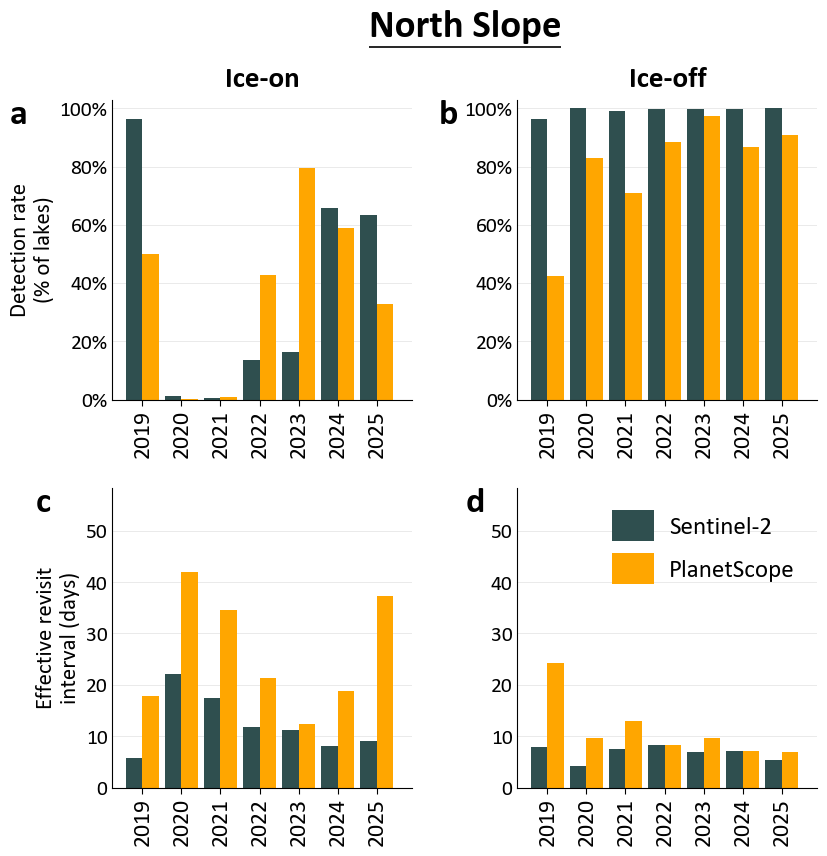

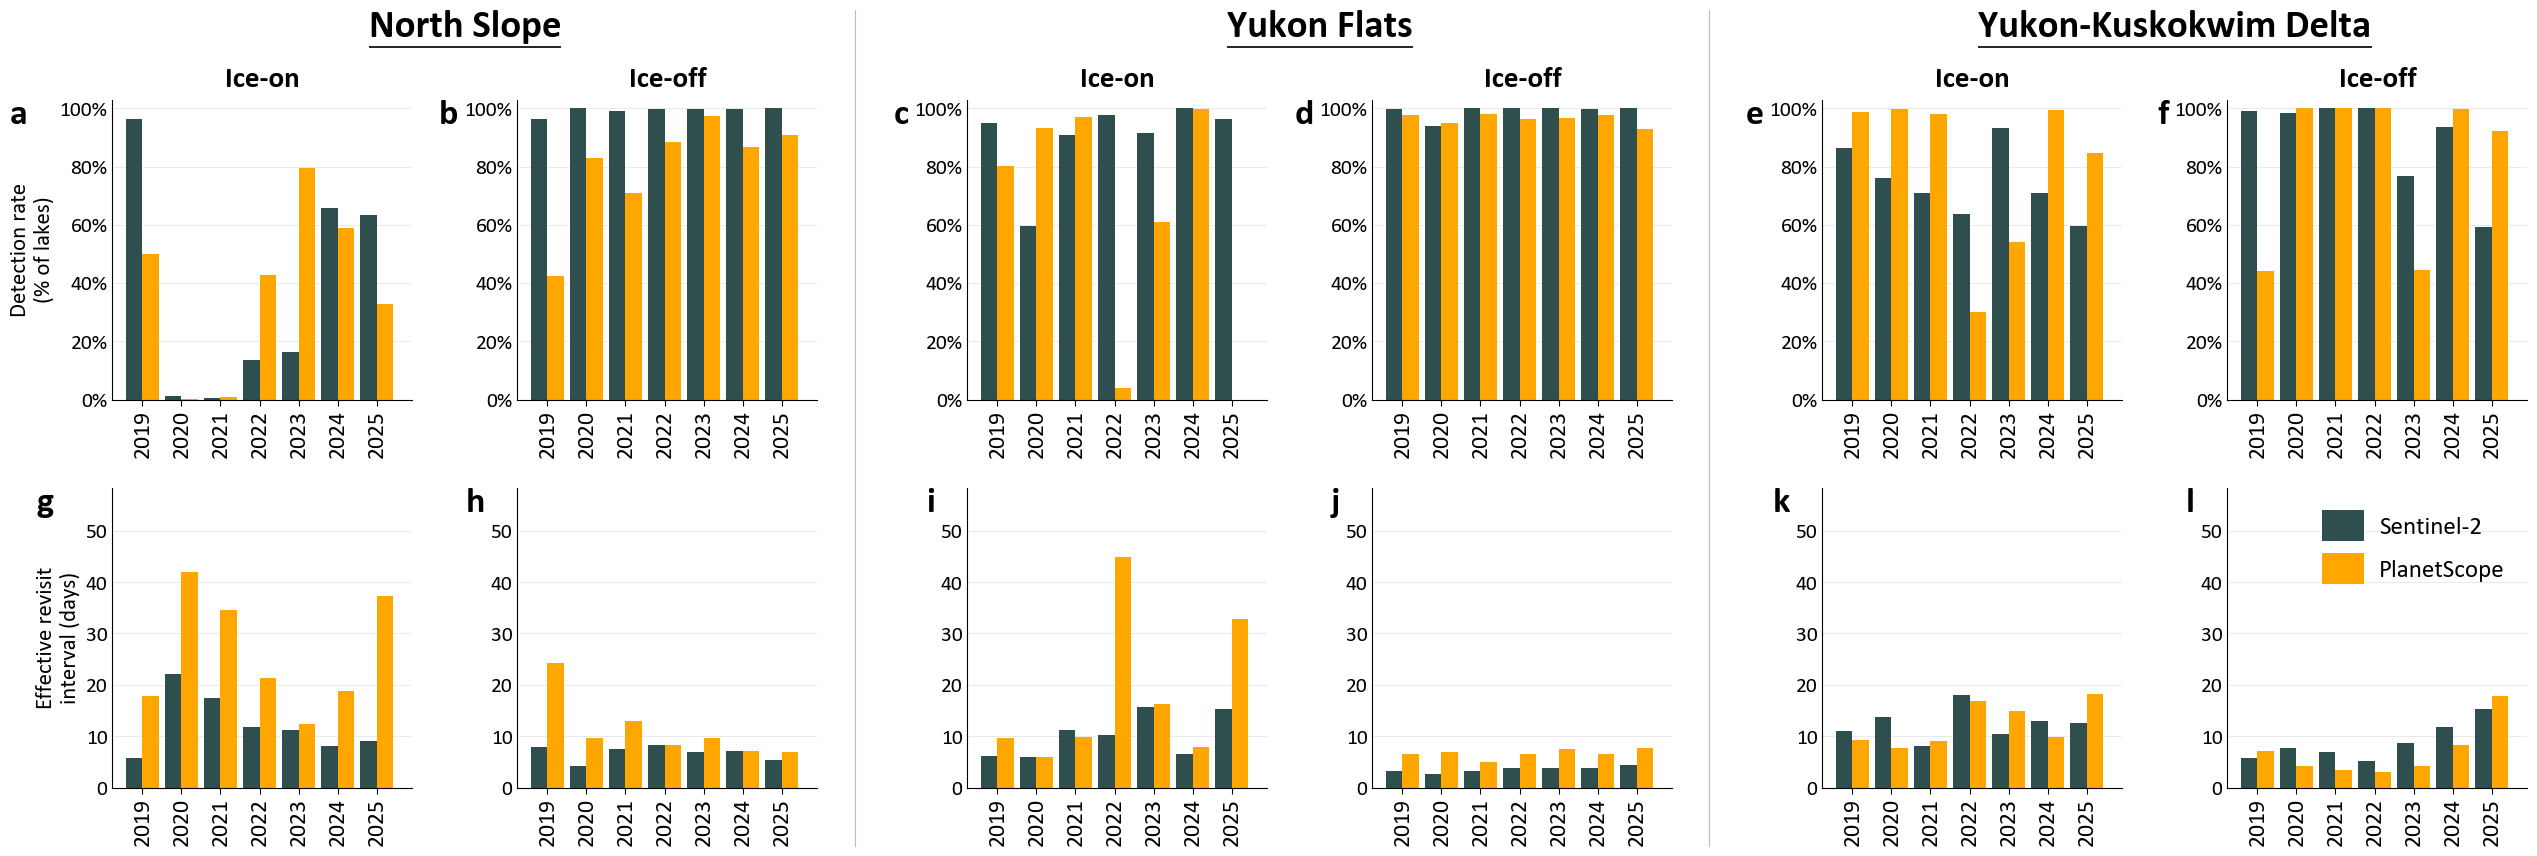

In [9]:
#!/usr/bin/env python3
# ------------------------------------------------------------------------------------
# Lake-ice ice-on / ice-off:  Effective Revisit Interval (ERR) + Detection rate
# Compares Sentinel-2 (S2) vs PlanetScope (PS) across sites NS, YKD, YF, 2019-2025.
#
# Reads the 12 real CSVs (3 sites x 2 sensors x 2 seasons). No synthetic data.
#
# Metrics (computed per SITE, per YEAR, from ALL lakes in that site):
#   1. ERR (all lakes)      -> mean days between valid observations, averaged over
#                              EVERY lake, including lakes with 0 observations.
#   2. Detection rate (%)   -> % of the site's lakes with an ice-off / ice-on date
#                              detected that year AND averaged uncertainty
#                              ((error_days_negative + error_days_positive) / 2)
#                              <= MAX_UNC days.
#
# ERR for a single lake-year:
#       N = total_observations_after_filtering
#           N == 0  -> ERR = season_len
#           N == 1  -> ERR = season_len / 2
#           N >= 2  -> ERR = season_len / N
#   (Flip ERR_MODE to "n_plus_1" for season_len / (N+1) everywhere.)
#
# Figures (each site = 2x2 block headed by an underlined site title; neighbouring blocks
# separated by a light vertical hairline; columns: Ice-on | Ice-off, rows: Detection on
# top, ERR on bottom; panels lettered across the whole top row first, then the whole
# bottom row; y-axis titles only on the far-left panels, aligned with each other, since
# all panels in a row share the same y-scale):
#   - revisit_detection_NS          : North Slope 2x2 block alone
#   - revisit_detection_all_sites   : NS | YF | YKD 2x2 blocks side by side
# ------------------------------------------------------------------------------------

import os
import string
import numpy as np
import pandas as pd
from datetime import datetime
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
from matplotlib.lines import Line2D
from matplotlib.transforms import Bbox
from matplotlib.ticker import PercentFormatter

# ── CONFIG ─────────────────────────────────────────────────────────────────────────

BASE_DIR = os.environ.get("LAKE_ICE_BASE_DIR", r"C:\Users\nj142\Desktop\Time Series")

DATASETS      = ["S2", "PS"]
SITES         = ["NS", "YF", "YKD"]
SEASONS_LIST  = ["Breakup", "Freezeup"]          # matches folder/file/column names; don't rename
DISPLAY_ORDER = ["Freezeup", "Breakup"]          # console table order: ice-on first, ice-off second
SEASON_COLS   = ["Freezeup", "Breakup"]          # figure columns, left -> right (Ice-on | Ice-off)
SEASON_LABELS = {"Breakup": "Ice-off", "Freezeup": "Ice-on"}
ALL_YEARS     = [2019, 2020, 2021, 2022, 2023, 2024, 2025]

OBS_COL   = "total_observations_after_filtering"
ERR_NEG   = "error_days_negative"
ERR_POS   = "error_days_positive"
MAX_UNC   = 15              # days; detections with averaged uncertainty above this don't count
ERR_MODE  = "special_n1"    # "special_n1" or "n_plus_1"

FONT_BUMP = 6

PANEL_LETTER_SIZE     = 20 + FONT_BUMP # pt
PANEL_LETTER_NUDGE_IN = 0.0            # inches; 0 = top of letter level with top of axes (+ up, - down)
PANEL_LETTER_PAD_IN   = 0.06           # inches; gap between letter and y tick labels (unlabelled panels)

SITE_TITLE_SIZE     = 22 + FONT_BUMP # pt
COL_HEADER_SIZE     = 15 + FONT_BUMP # pt, "Ice-on" / "Ice-off"
COL_HEADER_PAD_IN   = 0.08           # gap (inches) between top of the panel and the column header
SITE_TITLE_PAD_IN   = 0.56           # gap (inches) between top of the panels and the bottom of the site title

# Site title underline
TITLE_UL_FRAC   = 1.0                # underline length as a fraction of the title's text width
TITLE_UL_GAP_IN = 0.03               # gap (inches) between bottom of the title text and the underline
TITLE_UL_LW     = 1.2                # (pt)

# Figure spacing (inches)
M_LEFT, M_RIGHT, M_TOP, M_BOTTOM = 1.5, 0.3, 1.3, 0.95
WGAP = 1.05                          # between Ice-on and Ice-off panels (tick labels + letter)
HGAP = 0.88                          # between rows (rotated year labels)
BGAP = 1.5                           # between site blocks (tick labels + letter + separator)

# Vertical separators between site blocks
SEP_COLOR = "#bdbdbd"
SEP_LW    = 0.8                      # (pt); 0 to hide
SEP_STYLE = "-"                      # "-" solid, or e.g. (0, (4, 3)) for dashed

SENTINEL_COLOR = "#2f4f4f"
PLANET_COLOR   = "#ffa600"

SITE_NAMES = {
    "NS":  "North Slope",
    "YKD": "Yukon-Kuskokwim Delta",
    "YF":  "Yukon Flats",
}

SEASONS = {
    "NS":  {"Breakup":  ("{year}-04-15T00:00:00Z", "{year}-07-30T23:59:59Z"),
            "Freezeup": ("{year}-09-01T00:00:00Z", "{year}-10-30T23:59:59Z")},
    "YKD": {"Breakup":  ("{year}-04-01T00:00:00Z", "{year}-06-30T23:59:59Z"),
            "Freezeup": ("{year}-09-01T00:00:00Z", "{year}-11-30T23:59:59Z")},
    "YF":  {"Breakup":  ("{year}-04-15T00:00:00Z", "{year}-07-15T23:59:59Z"),
            "Freezeup": ("{year}-09-01T00:00:00Z", "{year}-11-15T23:59:59Z")},
}

# ── HELPERS ────────────────────────────────────────────────────────────────────────

def csv_path(dataset, site, season):
    return os.path.join(BASE_DIR, dataset, season, f"{site}_{season.lower()}_dates.csv")

def date_col_for(season):
    return f"{season.lower()}_date"

def season_length_days(site, season, year=2021):
    s_tpl, e_tpl = SEASONS[site][season]
    s = datetime.fromisoformat(s_tpl.format(year=year).replace("Z", "+00:00"))
    e = datetime.fromisoformat(e_tpl.format(year=year).replace("Z", "+00:00"))
    return (e - s).total_seconds() / 86400.0

def is_detected(val):
    if pd.isna(val):
        return False
    s = str(val).strip()
    return s != "" and s.lower() not in ("nan", "nat", "none", "null")

def err_for_n(n_obs, season_len):
    n = int(n_obs)
    if ERR_MODE == "n_plus_1":
        return season_len / (n + 1.0)
    if n <= 0:
        return season_len
    if n == 1:
        return season_len / 2.0
    return season_len / float(n)

# ── LOAD + COMPUTE ───────────────────────────────────────────────────────────────────

stats       = {site: {yr: {} for yr in ALL_YEARS} for site in SITES}
lake_counts = {}
season_len_cache = {}

ds_prefix = {"S2": "s2", "PS": "ps"}
se_suffix = {"Breakup": "bu", "Freezeup": "fu"}

for site in SITES:
    for season in SEASONS_LIST:
        season_len = season_length_days(site, season)
        season_len_cache[(site, season)] = season_len
        dcol = date_col_for(season)

        for dataset in DATASETS:
            path = csv_path(dataset, site, season)
            if not os.path.exists(path):
                raise FileNotFoundError(f"Missing file: {path}")

            df = pd.read_csv(path, usecols=lambda c: c in ("lake_id", "year", dcol, OBS_COL, ERR_NEG, ERR_POS))
            df["year"] = pd.to_numeric(df["year"], errors="coerce")
            df[OBS_COL] = pd.to_numeric(df[OBS_COL], errors="coerce").fillna(0)
            unc = (pd.to_numeric(df[ERR_NEG], errors="coerce") + pd.to_numeric(df[ERR_POS], errors="coerce")) / 2

            lakes = df["lake_id"].dropna().unique()
            n_lakes = len(lakes)
            lake_counts[(dataset, site)] = n_lakes

            obs_lookup, det_lookup = {}, {}
            for lk, yr, nobs, dval, u in zip(df["lake_id"], df["year"], df[OBS_COL], df[dcol], unc):
                key = (lk, yr)
                if key not in obs_lookup:
                    obs_lookup[key] = nobs
                    det_lookup[key] = is_detected(dval) and u <= MAX_UNC   # NaN uncertainty -> not detected

            for year in ALL_YEARS:
                err_all = [err_for_n(obs_lookup.get((lk, year), 0), season_len) for lk in lakes]
                n_detected = sum(det_lookup.get((lk, year), False) for lk in lakes)
                p, s = ds_prefix[dataset], se_suffix[season]
                stats[site][year][f"{p}_err_all_{s}"] = np.mean(err_all) if err_all else np.nan
                stats[site][year][f"{p}_det_{s}"]     = 100.0 * n_detected / n_lakes if n_lakes else np.nan

# ── CONSOLE OUTPUT ───────────────────────────────────────────────────────────────────

print("=" * 74)
print("SEASON LENGTHS (days)")
for site in SITES:
    for season in DISPLAY_ORDER:
        print(f"  {site:<4} {SEASON_LABELS[season]:<9} : {season_len_cache[(site, season)]:.4f} days")

print("=" * 74)
print("LAKES PER SITE")
for site in SITES:
    counts = {ds: lake_counts.get((ds, site)) for ds in DATASETS}
    if len(set(counts.values())) == 1:
        print(f"  {site:<4}: {next(iter(counts.values()))} lakes")
    else:
        print(f"  {site:<4}: {counts}   <-- S2 and PS lake counts differ!")

def mean_over(site_list, seasons, prefix, metric):
    # Mean of per-site-year values for metric ("err_all" or "det") across sites/seasons/years
    vals = [stats[st][yr].get(f"{prefix}_{metric}_{se_suffix[se]}", np.nan)
            for st in site_list for se in seasons for yr in ALL_YEARS]
    vals = [v for v in vals if np.isfinite(v)]
    return np.mean(vals) if vals else np.nan

def print_site_table(title, metric):
    print("=" * 74)
    print(title)
    print(f"  {'site':<5}{'season':<10}{'Sentinel-2':>12}{'PlanetScope':>13}")
    for site in SITES:
        for season in DISPLAY_ORDER:
            print(f"  {site:<5}{SEASON_LABELS[season]:<10}{mean_over([site], [season], 's2', metric):>12.2f}"
                  f"{mean_over([site], [season], 'ps', metric):>13.2f}")

def print_aggregate_table(title, metric, include_combined=False):
    print("=" * 74)
    print(title)
    print(f"  {'season':<10}{'Sentinel-2':>12}{'PlanetScope':>13}")
    rows = [(SEASON_LABELS[se], [se]) for se in DISPLAY_ORDER]
    if include_combined:
        rows.append(("Combined", SEASONS_LIST))
    for label, seasons in rows:
        print(f"  {label:<10}{mean_over(SITES, seasons, 's2', metric):>12.2f}"
              f"{mean_over(SITES, seasons, 'ps', metric):>13.2f}")

print_site_table("MEAN ERR PER SITE & SEASON  (days, averaged across all years 2019-2025)", "err_all")
print_aggregate_table("AGGREGATE MEAN ERR PER SENSOR  (days, across all 3 sites & all years)", "err_all")
print_site_table(f"MEAN DETECTION RATE PER SITE & SEASON  (% of lakes, uncertainty <= {MAX_UNC} d, "
                 f"averaged across 2019-2025)", "det")
print_aggregate_table(f"AGGREGATE DETECTION RATE PER SENSOR  (% of lakes, uncertainty <= {MAX_UNC} d, "
                      f"across all 3 sites & all years)", "det", include_combined=True)
print("=" * 74)

# ── FIGURES ──────────────────────────────────────────────────────────────────────────
# Each site = one 2x2 block (cols: Ice-on / Ice-off, rows: Detection / ERR) under an
# underlined site title; blocks separated by thin vertical hairlines. Each year = one
# touching S2|PS pair; small gap between years.

BARW, PAIR_GAP, SITE_GAP = 1.0, 0.35, 1.8

def make_layout(sites):
    layout, site_centers, x = [], {}, 0.0      # layout: (site, year, pair_center)
    for site in sites:
        start = x
        for yr in ALL_YEARS:
            layout.append((site, yr, x + BARW))
            x += 2 * BARW + PAIR_GAP
        site_centers[site] = (start + x - PAIR_GAP) / 2
        x += SITE_GAP - PAIR_GAP
    return layout, site_centers, x - SITE_GAP + PAIR_GAP

def draw(ax, sites, k_s2, k_ps):
    layout, site_centers, x_max = make_layout(sites)
    for site, yr, xc in layout:
        for key, color, xb in ((k_s2, SENTINEL_COLOR, xc - BARW / 2),
                               (k_ps, PLANET_COLOR,   xc + BARW / 2)):
            v = stats[site][yr].get(key, np.nan)
            if np.isfinite(v):
                ax.bar(xb, v, width=BARW, color=color, linewidth=0, edgecolor="none", zorder=2)
    ax.set_xticks([xc for _, _, xc in layout])               # tick at every S2|PS seam
    ax.set_xticklabels([str(yr) for _, yr, _ in layout], rotation=90, fontsize=11 + FONT_BUMP)
    ax.set_xlim(-0.8, x_max + 0.8)
    ax.set_facecolor("none")
    for sp in ("top", "right"):
        ax.spines[sp].set_visible(False)
    ax.yaxis.grid(True, color="#e6e6e6", lw=0.6, zorder=0)
    ax.set_axisbelow(True)
    ax.tick_params(axis="x", length=4, width=0.8)
    ax.tick_params(axis="y", length=0, labelsize=9.5 + FONT_BUMP)

def row_top(sites, metric):
    # Max of metric over both sensors, both seasons, all years for the given sites
    vals = [stats[s][yr].get(f"{p}_{metric}_{se_suffix[se]}", np.nan)
            for p in ds_prefix.values() for se in SEASONS_LIST
            for s in sites for yr in ALL_YEARS]
    vals = [v for v in vals if np.isfinite(v)]
    return max(vals) if vals else 1.0

def add_panel_letter(fig, ax, letter, renderer):
    # Top of the letter level with the top of its axes (+ PANEL_LETTER_NUDGE_IN).
    # Panels with a y-axis title: letter left edge flush with that title.
    # Panels without one: letter sits just left of the y tick labels.
    to_fig = fig.transFigure.inverted()
    W, H = fig.get_size_inches()
    y = ax.get_position().y1 + PANEL_LETTER_NUDGE_IN / H
    if ax.get_ylabel():
        x = ax.yaxis.label.get_window_extent(renderer).transformed(to_fig).x0
        ha = "left"
    else:
        x = ax.yaxis.get_tightbbox(renderer).transformed(to_fig).x0 - PANEL_LETTER_PAD_IN / W
        ha = "right"
    return fig.text(x, y, letter, ha=ha, va="top",
                    fontsize=PANEL_LETTER_SIZE, fontweight="bold")

def add_title_underline(fig, title, renderer):
    # Thin underline centred under the site title, TITLE_UL_FRAC of the text width
    bb = title.get_window_extent(renderer).transformed(fig.transFigure.inverted())
    half = bb.width * TITLE_UL_FRAC / 2
    xc = (bb.x0 + bb.x1) / 2
    y = bb.y0 - TITLE_UL_GAP_IN / fig.get_size_inches()[1]
    fig.add_artist(Line2D([xc - half, xc + half], [y, y], transform=fig.transFigure,
                          color="black", lw=TITLE_UL_LW, solid_capstyle="butt"))

def extent(fig, artists, renderer):
    # Union of the artists' drawn extents, in figure coordinates
    return Bbox.union([a.get_tightbbox(renderer) for a in artists]).transformed(fig.transFigure.inverted())

# Each row: (ylabel, metric key, kind)  -- top row first
METRIC_ROWS = [
    ("Detection rate\n(% of lakes)",       "det",     "pct"),
    ("Effective revisit\ninterval (days)", "err_all", "days"),
]

def make_figure(site_blocks, out_stem, panel_w, panel_h, err_top=None):
    # One 2x2 block per site, blocks placed left-to-right.
    # Everything in inches: panel size is fixed, figure size is built around it.
    nb = len(site_blocks)
    block_w = 2 * panel_w + WGAP
    W = M_LEFT + nb * block_w + (nb - 1) * BGAP + M_RIGHT
    H = M_BOTTOM + 2 * panel_h + HGAP + M_TOP
    fig = plt.figure(figsize=(W, H), facecolor="white")

    blocks = []                      # per site: 2x2 list of axes [row][col]
    block_texts = []                 # per site: [site title, column headers...]
    for b, site in enumerate(site_blocks):
        x_block = M_LEFT + b * (block_w + BGAP)
        axes = [[None, None], [None, None]]
        for ri, (ylabel, metric, kind) in enumerate(METRIC_ROWS):
            if kind == "pct":
                top = 103
            else:
                top = err_top if err_top is not None else row_top([site], metric) * 1.3
            for ci, season in enumerate(SEASON_COLS):
                s = se_suffix[season]
                x0 = x_block + ci * (panel_w + WGAP)
                y0 = M_BOTTOM + (1 - ri) * (panel_h + HGAP)
                ax = fig.add_axes([x0 / W, y0 / H, panel_w / W, panel_h / H])
                draw(ax, [site], f"s2_{metric}_{s}", f"ps_{metric}_{s}")
                ax.set_ylim(0, top)
                if b == 0 and ci == 0:   # y-axis title only on the far-left panel of each row
                    ax.set_ylabel(ylabel, fontsize=10.5 + FONT_BUMP, linespacing=1.25)
                if kind == "pct":
                    ax.yaxis.set_major_formatter(PercentFormatter(decimals=0))
                axes[ri][ci] = ax
        blocks.append(axes)

        texts = []
        # Site title centred over this block, SITE_TITLE_PAD_IN above the top panels
        bx0 = axes[0][0].get_position().x0
        bx1 = axes[0][1].get_position().x1
        by1 = axes[0][0].get_position().y1
        texts.append(fig.text((bx0 + bx1) / 2, by1 + SITE_TITLE_PAD_IN / H, SITE_NAMES.get(site, site),
                              ha="center", va="bottom", fontsize=SITE_TITLE_SIZE, fontweight="bold"))

        # Ice-on / Ice-off column headers centred over each column's top panel
        for ci, season in enumerate(SEASON_COLS):
            pos = axes[0][ci].get_position()
            texts.append(fig.text((pos.x0 + pos.x1) / 2, pos.y1 + COL_HEADER_PAD_IN / H,
                                  SEASON_LABELS[season], ha="center", va="bottom",
                                  fontsize=COL_HEADER_SIZE, fontweight="bold"))
        block_texts.append(texts)

    # Both far-left y-axis titles share the same x (the further-left one, from the wider % tick labels)
    fig.align_ylabels([blocks[0][0][0], blocks[0][1][0]])

    # Legend once, in the bottom-right panel of the last block
    blocks[-1][1][1].legend(handles=[mpatches.Patch(facecolor=SENTINEL_COLOR, label="Sentinel-2"),
                                     mpatches.Patch(facecolor=PLANET_COLOR,   label="PlanetScope")],
                            loc="upper right", ncol=1, frameon=False,
                            fontsize=12 + FONT_BUMP, handlelength=1.7, handleheight=1.5,
                            columnspacing=1.4, handletextpad=0.6)

    # Letters, underlines and separators need real text positions, so draw once first.
    fig.canvas.draw()
    renderer = fig.canvas.get_renderer()
    extents = []
    for b, (site, axes) in enumerate(zip(site_blocks, blocks)):
        # Letters run across the whole top row (all sites), then the whole bottom row:
        # e.g. 3 sites -> top row a-f, bottom row g-l
        letters = []
        for ri in range(2):
            for ci in range(2):
                idx = ri * (2 * nb) + b * 2 + ci
                letters.append(add_panel_letter(fig, axes[ri][ci], string.ascii_lowercase[idx], renderer))
        add_title_underline(fig, block_texts[b][0], renderer)
        extents.append(extent(fig, [ax for row in axes for ax in row] + letters + block_texts[b], renderer))

    # Thin vertical separators centred in the gap between neighbouring blocks
    if SEP_LW > 0:
        y_lo = min(e.y0 for e in extents)
        y_hi = max(e.y1 for e in extents)
        for left, right in zip(extents[:-1], extents[1:]):
            x_sep = (left.x1 + right.x0) / 2
            fig.add_artist(Line2D([x_sep, x_sep], [y_lo, y_hi], transform=fig.transFigure,
                                  color=SEP_COLOR, lw=SEP_LW, linestyle=SEP_STYLE))

err_top = row_top(SITES, "err_all") * 1.3   # shared ERR scale across sites

# North Slope on its own
make_figure(["NS"], "revisit_detection_NS", 3.0, 3.0, err_top=err_top)

# NS | YF | YKD blocks side by side
make_figure(["NS", "YF", "YKD"], "revisit_detection_all_sites", 3.0, 3.0, err_top=err_top)
plt.show()

# Fig. 8 - Manual Accuracy Assessment


Break-up
  NS  (rows in df: 250)
    PlanetScope   n=203  MAE=2.5 d  bias=+0.8 d  RMSE=3.7 d
    Sentinel-2    n=248  MAE=1.9 d  bias=-0.5 d  RMSE=2.8 d
  YF  (rows in df: 244)
    PlanetScope   n=237  MAE=4.1 d  bias=+0.8 d  RMSE=6.6 d
    Sentinel-2    n=244  MAE=3.6 d  bias=-1.1 d  RMSE=6.0 d
  YKD  (rows in df: 250)
    PlanetScope   n=244  MAE=5.9 d  bias=+5.1 d  RMSE=9.6 d
    Sentinel-2    n=248  MAE=3.5 d  bias=+2.1 d  RMSE=6.0 d

Freeze-up
  NS  (rows in df: 250)
    PlanetScope   n=166  MAE=6.8 d  bias=+6.3 d  RMSE=8.3 d
    Sentinel-2    n=180  MAE=2.6 d  bias=+1.2 d  RMSE=3.5 d
  YF  (rows in df: 250)
    PlanetScope   n=156  MAE=4.3 d  bias=+3.7 d  RMSE=5.3 d
    Sentinel-2    n=232  MAE=3.8 d  bias=+3.8 d  RMSE=5.3 d
  YKD  (rows in df: 250)
    PlanetScope   n=219  MAE=4.5 d  bias=+2.4 d  RMSE=6.8 d
    Sentinel-2    n=220  MAE=5.6 d  bias=+3.0 d  RMSE=8.4 d



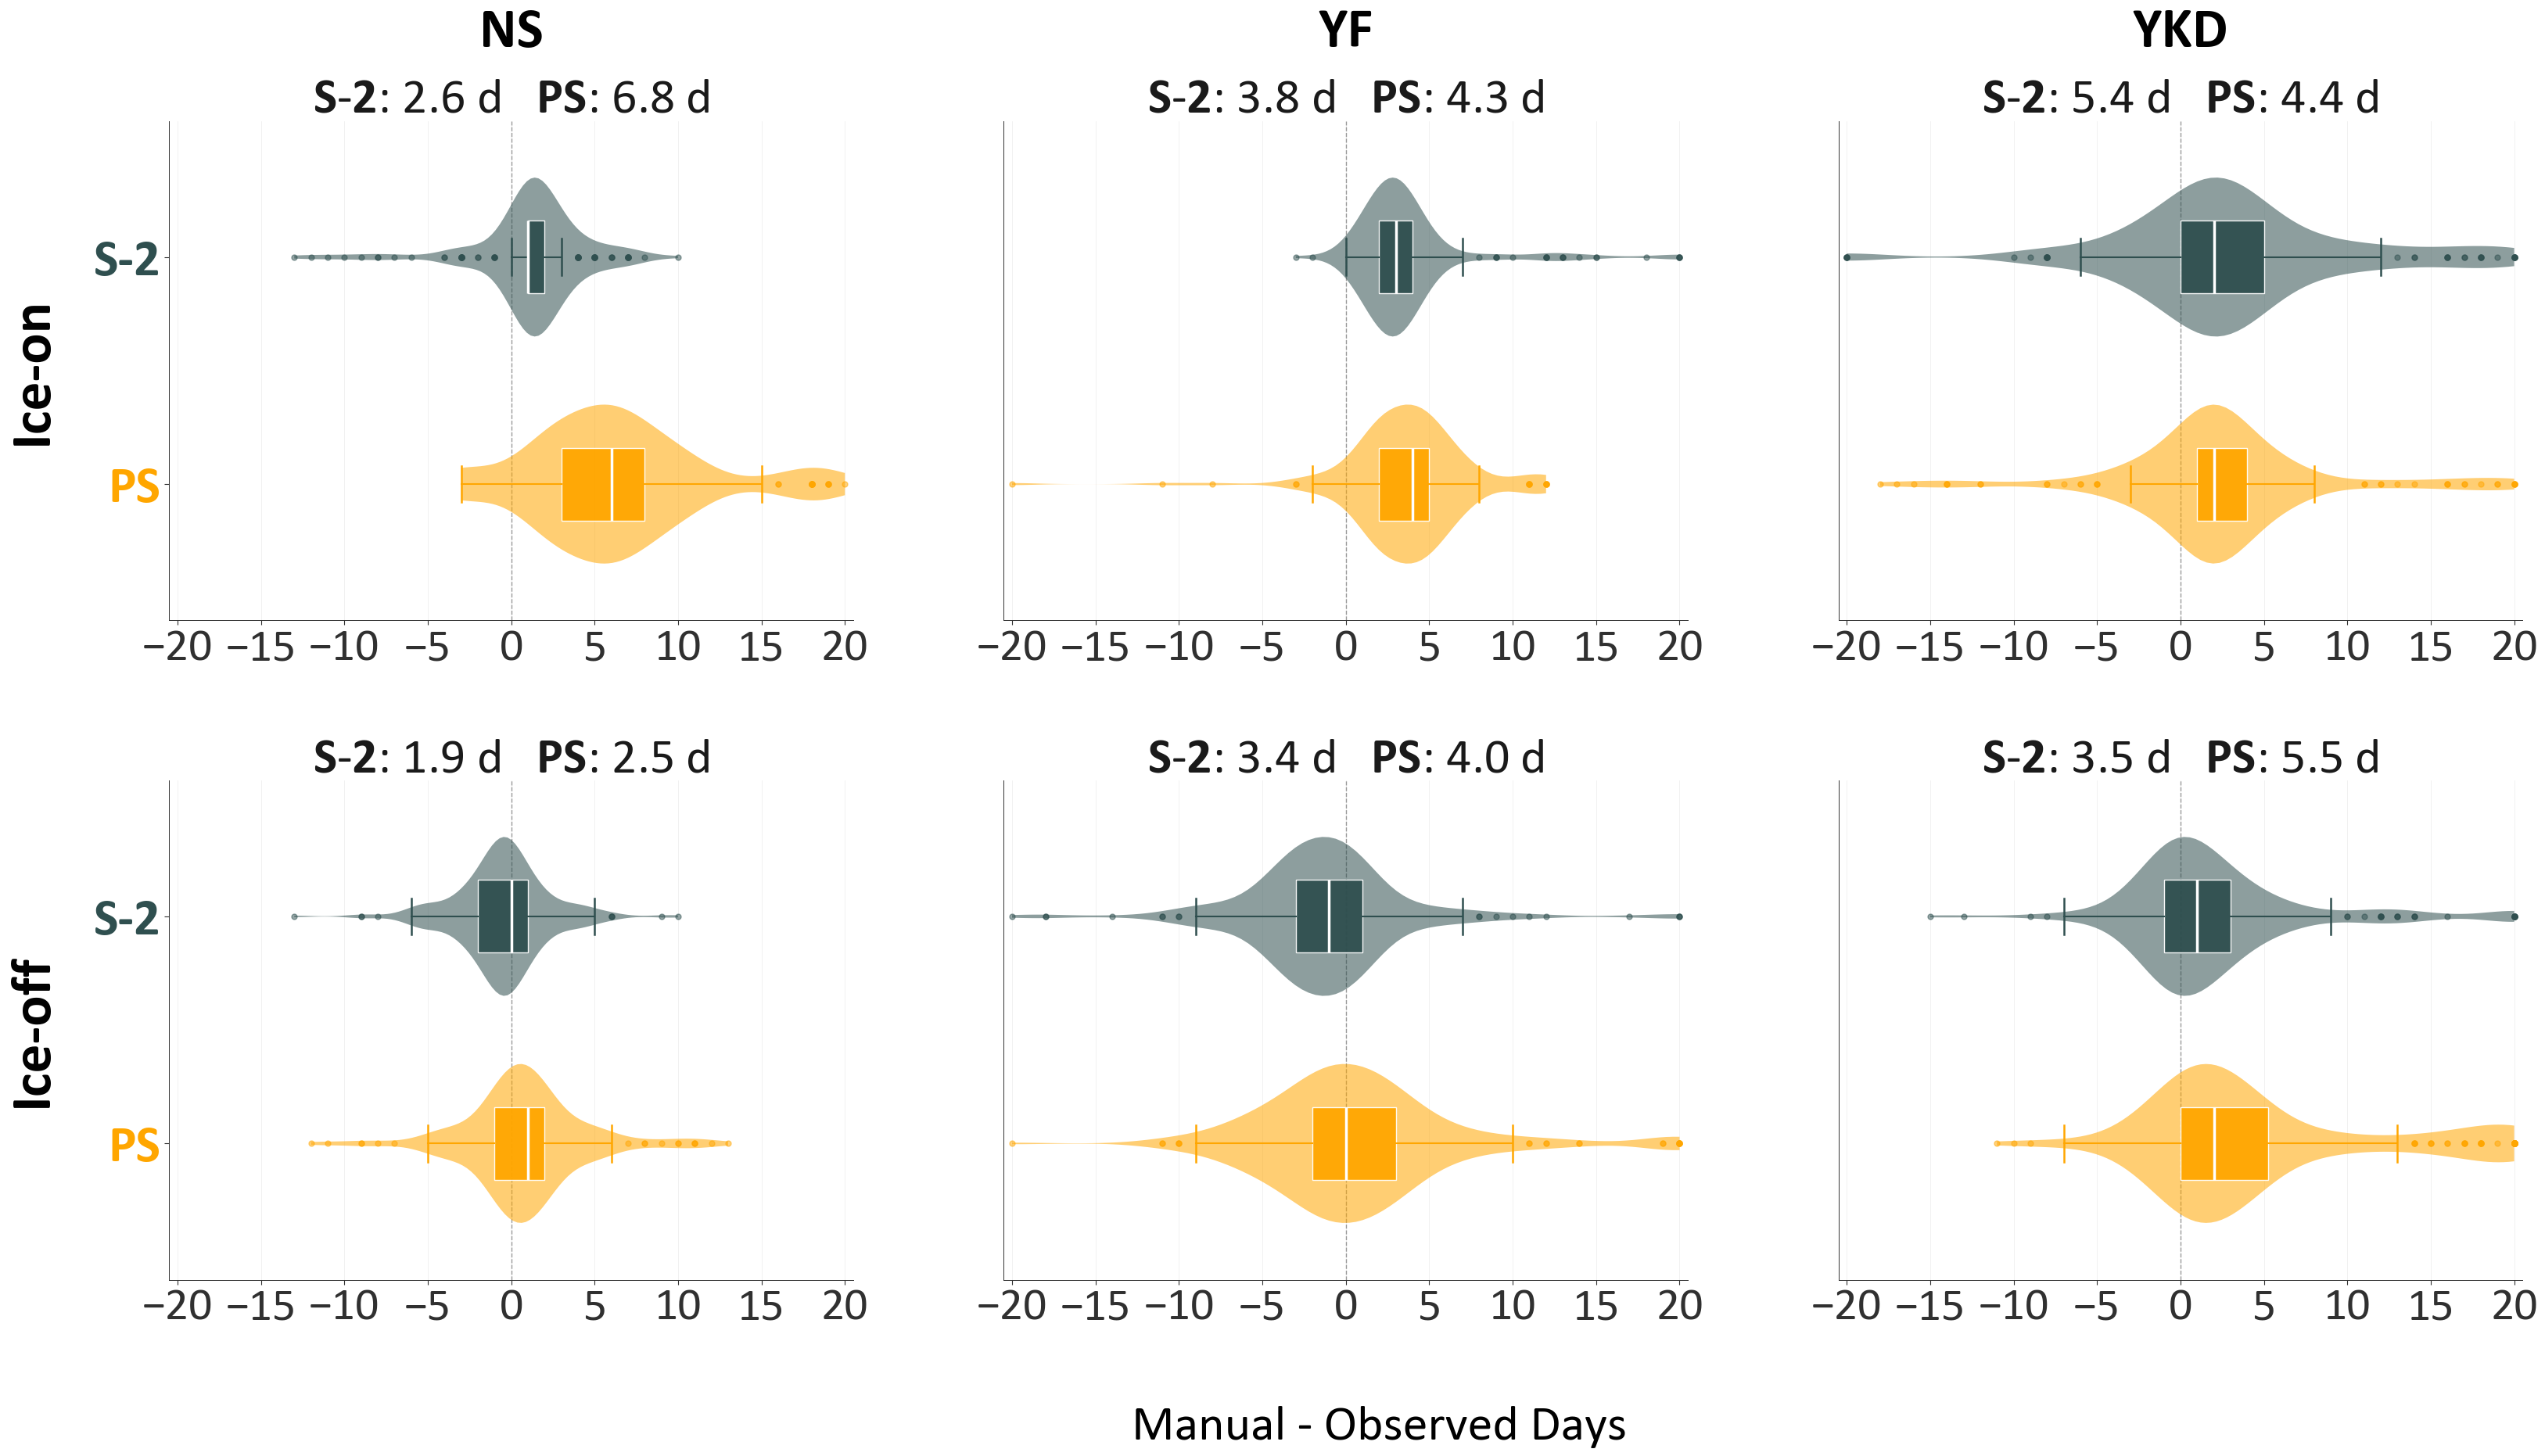

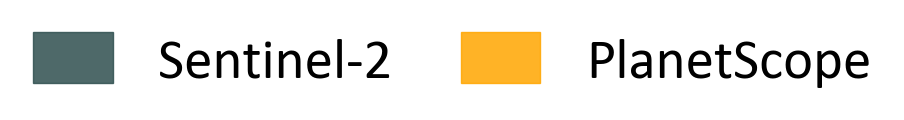

In [35]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches

# Colours
PLANET_COLOR   = '#ffa600'
SENTINEL_COLOR = '#2f4f4f'

# Config
FREEZEUP_CSV = r'E:\planetscope_lake_ice\Data\Output\Freezeup\manual_freezeup_review.csv'
BREAKUP_CSV  = r'E:\planetscope_lake_ice\Data\Output\Breakup\manual_breakup_review.csv'

SITES   = ['NS', 'YF', 'YKD']
X_CLIP  = 20
x_ticks = np.arange(-X_CLIP, X_CLIP + 1, 5)

# Title / label spacing controls
TITLE_PAD       = 3    # points between axis top and MAE subtitle
SITE_LABEL_OFFS = 59   # points between axis top and site label (sits just above subtitle)  # CHANGED (was 58, follows +1 font)
ROW_LABEL_PAD   = 34   # points between y tick labels (PS / S-2) and Ice-on / Ice-off       # CHANGED (was 8)

# Helper: parse dates, coercing anything unparseable to NaT
def _parse_dates(df, cols):
    for col in cols:
        if col in df.columns:
            df[col] = pd.to_datetime(df[col], format='mixed', errors='coerce', dayfirst=False)
    return df

# Load freeze-up
df_fu = pd.read_csv(FREEZEUP_CSV)
df_fu = _parse_dates(df_fu, ['planet_freezeup_date', 'sentinel_freezeup_date', 'manual_freezeup_date'])
df_fu['planet_error']   = (df_fu['planet_freezeup_date']   - df_fu['manual_freezeup_date']).dt.days
df_fu['sentinel_error'] = (df_fu['sentinel_freezeup_date'] - df_fu['manual_freezeup_date']).dt.days
df_fu = df_fu[df_fu['planet_error'].notna() | df_fu['sentinel_error'].notna()]

# Load break-up
df_bu = pd.read_csv(BREAKUP_CSV)
df_bu = _parse_dates(df_bu, ['planet_breakup_date', 'sentinel_breakup_date', 'manual_breakup_date'])
df_bu['planet_error']   = (df_bu['planet_breakup_date']   - df_bu['manual_breakup_date']).dt.days
df_bu['sentinel_error'] = (df_bu['sentinel_breakup_date'] - df_bu['manual_breakup_date']).dt.days
df_bu = df_bu[df_bu['planet_error'].notna() | df_bu['sentinel_error'].notna()]

# Print summary stats
for event, df_ev in [('Break-up', df_bu), ('Freeze-up', df_fu)]:
    print(f"\n{event}")
    for site in SITES:
        sub = df_ev[df_ev['study_site'] == site]
        print(f"  {site}  (rows in df: {len(sub)})")
        for lbl, col in [('PlanetScope', 'planet_error'), ('Sentinel-2', 'sentinel_error')]:
            err = sub[col].dropna()
            if len(err):
                print(f"    {lbl:12s}  n={len(err):3d}  "
                      f"MAE={err.abs().mean():.1f} d  "
                      f"bias={err.mean():+.1f} d  "
                      f"RMSE={np.sqrt((err**2).mean()):.1f} d")
            else:
                print(f"    {lbl:12s}  n=0  (no valid data)")
print()

# Global style  # CHANGED (all sizes +1)
plt.rcParams.update({
    "font.family":        "Calibri",
    "mathtext.fontset":   "custom",
    "mathtext.rm":        "Calibri",
    "mathtext.bf":        "Calibri:bold",
    "mathtext.it":        "Calibri:italic",
    "font.size":          46,
    "axes.titlesize":     46,
    "axes.labelsize":     46,
    "xtick.labelsize":    43,
    "ytick.labelsize":    46,
    "legend.fontsize":    46,
    "figure.titlesize":   49,
    "axes.linewidth":     0.7,
    "xtick.direction":    "out",
    "ytick.direction":    "out",
    "xtick.major.size":   4,
    "ytick.major.size":   4,
})

def _style_ax(ax):
    ax.spines['top'].set_visible(False)
    ax.spines['right'].set_visible(False)
    ax.xaxis.grid(True, color='#ebebeb', linewidth=0.5, zorder=0)
    ax.set_axisbelow(True)

def _draw_violin_box(ax, s_err, p_err):
    """
    Horizontal violin + slim boxplot overlay.
    S-2 at y=2, PS at y=1.
    """
    for vals, pos, col in [(s_err, 2, SENTINEL_COLOR), (p_err, 1, PLANET_COLOR)]:
        n = len(vals)
        if n == 0:
            continue
        elif n == 1:
            ax.scatter(vals.values[0], pos, color=col, s=120,
                       zorder=5, clip_on=True)
        else:
            parts = ax.violinplot(
                [vals.values],
                positions=[pos],
                vert=False,
                widths=0.70,
                showmedians=False,
                showextrema=False,
            )
            for body in parts['bodies']:
                body.set_facecolor(col)
                body.set_edgecolor('none')
                body.set_alpha(0.55)
                body.set_linewidth(0)
                body.set_zorder(2)

            bp = ax.boxplot(
                vals.values,
                positions=[pos],
                vert=False,
                widths=0.32,
                patch_artist=True,
                notch=False,
                whis=1.5,
                zorder=4,
                flierprops=dict(
                    marker='o',
                    markersize=5.0,
                    linestyle='none',
                    markerfacecolor=col,
                    markeredgecolor=col,
                    alpha=0.5,
                    zorder=4,
                ),
                medianprops=dict(color='white', linewidth=2.5, zorder=5),
                whiskerprops=dict(color=col, linewidth=1.5, zorder=4),
                capprops=dict(color=col, linewidth=1.8, zorder=4),
            )
            bp['boxes'][0].set_facecolor(col)
            bp['boxes'][0].set_edgecolor('white')
            bp['boxes'][0].set_linewidth(1.0)
            bp['boxes'][0].set_alpha(0.95)

def _make_subtitle(p_err, s_err):
    p_mae = p_err.abs().mean() if len(p_err) else float('nan')
    s_mae = s_err.abs().mean() if len(s_err) else float('nan')
    ps_txt = rf"$\bf{{PS}}$: {p_mae:.1f} d" if not np.isnan(p_mae) else r"$\bf{PS}$: n/a"
    s2_txt = rf"$\bf{{S}}$-$\bf{{2}}$: {s_mae:.1f} d" if not np.isnan(s_mae) else r"$\bf{S}$-$\bf{2}$: n/a"
    return f"{s2_txt}   {ps_txt}"

# Row definitions
ROWS = [
    {'label': 'Ice-on',  'df': df_fu},
    {'label': 'Ice-off', 'df': df_bu},
]

# Shared x-axis label text
SHARED_XLABEL = 'Manual - Observed Days'

# Figure
fig, axes = plt.subplots(2, 3, figsize=(34, 19))
fig.subplots_adjust(hspace=0.32, wspace=0.22,
                    left=0.075, right=0.96,         # CHANGED (was left=0.07)
                    top=0.90, bottom=0.12)

for row_idx, row_cfg in enumerate(ROWS):
    df_row = row_cfg['df']

    for col_idx, site in enumerate(SITES):
        sub   = df_row[df_row['study_site'] == site]
        p_err = sub['planet_error'].dropna().astype(float).clip(-X_CLIP, X_CLIP)
        s_err = sub['sentinel_error'].dropna().astype(float).clip(-X_CLIP, X_CLIP)

        ax = axes[row_idx, col_idx]

        _draw_violin_box(ax, s_err, p_err)

        ax.axvline(0, color='#999999', linewidth=1.0, linestyle='--', zorder=1)
        ax.set_xlim(-X_CLIP - 0.5, X_CLIP + 0.5)
        ax.set_xticks(x_ticks)
        ax.set_ylim(0.4, 2.6)
        ax.set_axisbelow(True)
        ax.set_xlabel('')

        # Only apply S-2 vs PS y-axis ticks and labels to the leftmost charts
        if col_idx == 0:
            y_labels = []
            for err_arr, lbl in [(p_err, 'PS'), (s_err, 'S-2')]:
                n = len(err_arr)
                suffix = f' (n={n})' if n <= 1 else ''
                y_labels.append(f'{lbl}{suffix}')

            ax.set_yticks([1, 2])
            ax.set_yticklabels(y_labels, fontsize=48, fontweight='bold')  # CHANGED (was 47)

            # Recolor target text labels to match plots
            tick_labels = ax.get_yticklabels()
            if len(tick_labels) >= 2:
                tick_labels[0].set_color(PLANET_COLOR)    # Y=1 is PlanetScope
                tick_labels[1].set_color(SENTINEL_COLOR)  # Y=2 is Sentinel-2

            # Row label as a y-label so it sits right beside the tick labels
            ax.set_ylabel(row_cfg['label'],
                          fontsize=53,                    # CHANGED (was 52)
                          fontweight='bold',
                          color='black',
                          labelpad=ROW_LABEL_PAD)
        else:
            # Clean up carried-over charts by hiding ticks entirely
            ax.set_yticks([])
            ax.set_yticklabels([])

        _style_ax(ax)

        subtitle = _make_subtitle(p_err, s_err)
        ax.set_title(subtitle, loc='center', pad=TITLE_PAD, fontsize=46)  # CHANGED (was 45)

        # Site label anchored to the top-row axes, just above the subtitle
        if row_idx == 0:
            ax.annotate(site,
                        xy=(0.5, 1.0), xycoords='axes fraction',
                        xytext=(0, SITE_LABEL_OFFS), textcoords='offset points',
                        ha='center', va='bottom',
                        fontsize=52, fontweight='bold',   # CHANGED (was 51)
                        fontfamily='Calibri',
                        annotation_clip=False)

# Single, clean global X-axis label added directly to the bottom of the figure layout
fig.text(0.53, 0.035, SHARED_XLABEL,
         ha='center', va='top',
         fontsize=46,                                     # CHANGED (was 45)
         fontfamily='Calibri')

plt.show()

# Standalone legend
fig_leg, ax_leg = plt.subplots(figsize=(7, 1.8))
ax_leg.set_axis_off()
handles = [
    mpatches.Patch(color=SENTINEL_COLOR, alpha=0.85, label='Sentinel-2'),
    mpatches.Patch(color=PLANET_COLOR,   alpha=0.85, label='PlanetScope'),
]
ax_leg.legend(handles=handles, loc='center', ncol=2, frameon=False,
              fontsize=41, handlelength=1.4, handleheight=1.0, columnspacing=1.2)  # CHANGED (was 40)
plt.tight_layout()
plt.show()

# Fig. 9 - Lake Size Bins


CUZICK'S TREND TEST  (H₀: no monotonic trend across Small→Medium→Large)
Stars: *** p<0.001  ** p<0.01  * p<0.05  ns = not significant
Z > 0  →  larger lakes are later in the season

────────────────────────────────────────  ICE-ON  ────────────────────────────────────────

  [Sentinel-2]
    YKD:  Z=-22.684  p=0.0000 ***  (larger lakes EARLIER)  n=4642/3489/193  means=302.9/301.6/300.5 DOY
    YF:  Z=-4.063  p=0.0000 ***  (larger lakes EARLIER)  n=916/897/45  means=290.1/289.6/290.5 DOY
    NS:  Z=+28.223  p=0.0000 ***  (larger lakes later)  n=3031/2023/245  means=279.2/281.1/284.2 DOY

  [PlanetScope]
    YKD:  Z=-7.198  p=0.0000 ***  (larger lakes EARLIER)  n=4642/3489/193  means=302.0/301.8/300.1 DOY
    YF:  Z=+10.149  p=0.0000 ***  (larger lakes later)  n=916/897/45  means=286.6/287.7/288.5 DOY
    NS:  Z=+5.539  p=0.0000 ***  (larger lakes later)  n=3031/2023/245  means=283.1/283.4/283.4 DOY

────────────────────────────────────────  ICE-OFF  ────────────────────────────────────

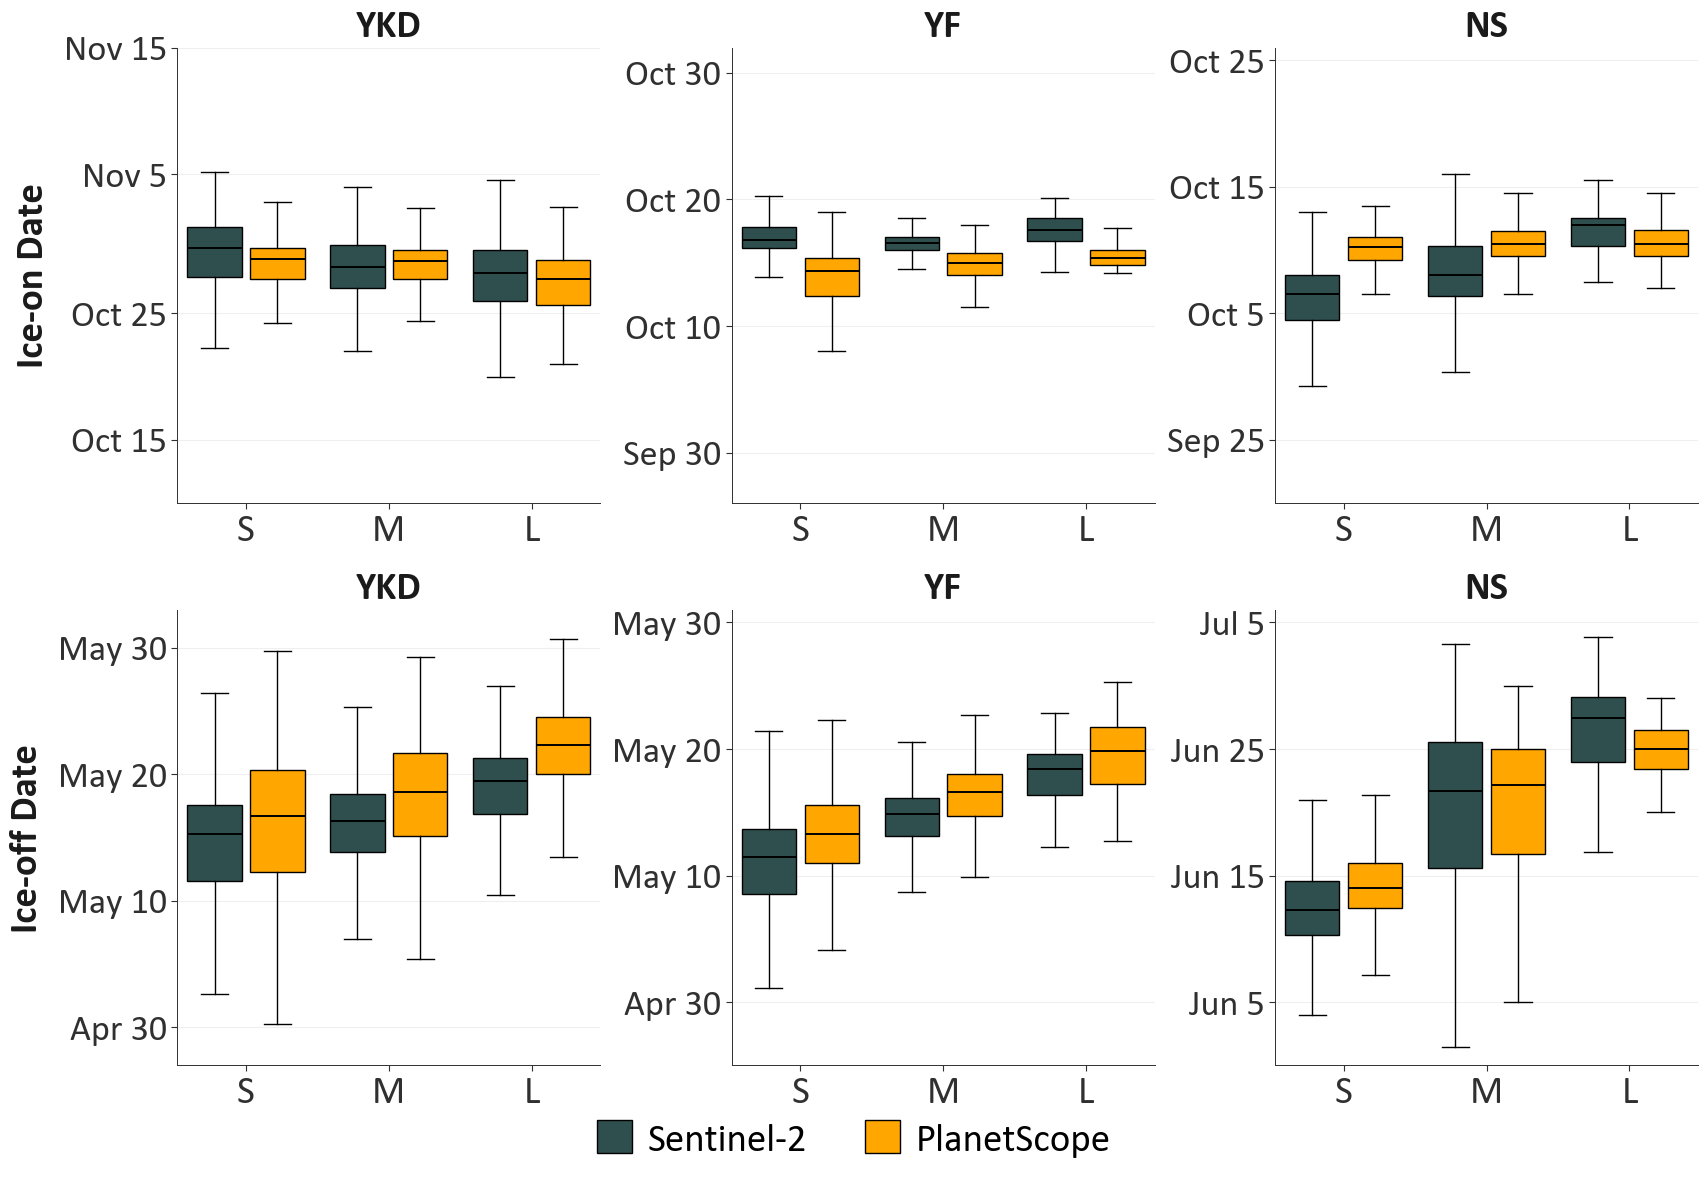

C:\Users\nj142\AppData\Local\Temp\ipykernel_31612\3416724490.py:361: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()
c:\Users\nj142\AppData\Local\anaconda3\Lib\site-packages\IPython\core\pylabtools.py:170: UserWarning: Glyph 9660 (\N{BLACK DOWN-POINTING TRIANGLE}) missing from current font.
  fig.canvas.print_figure(bytes_io, **kw)
c:\Users\nj142\AppData\Local\anaconda3\Lib\site-packages\IPython\core\pylabtools.py:170: UserWarning: Glyph 9650 (\N{BLACK UP-POINTING TRIANGLE}) missing from current font.
  fig.canvas.print_figure(bytes_io, **kw)


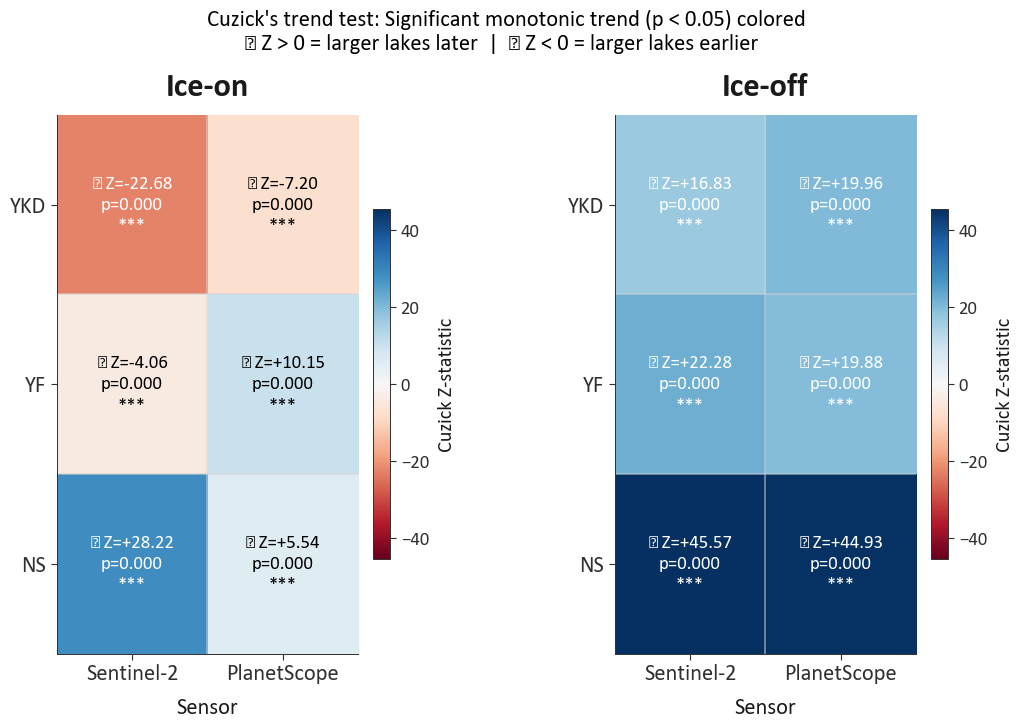

In [31]:
import pandas as pd
import geopandas as gpd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
from scipy import stats
import warnings
from datetime import datetime, timedelta


# Changed font family to Calibri
plt.rcParams["font.family"] = "Calibri"

# ----------------------------------------------------------------------
# Config
# ----------------------------------------------------------------------
TEXT_SCALE = 1.8
SITES   = ["YKD", "YF", "NS"]
SENSORS = ["S2", "PS"]                   # order = legend left-to-right, heatmap left-to-right
EVENTS  = ["Ice-on", "Ice-off"]          # order = top-to-bottom rows in boxplot figure
SENSOR_LABELS = {"PS": "PlanetScope", "S2": "Sentinel-2"}

# Event -> DOY column used throughout the analysis
EVENT_COL = {"Ice-on": "iceon_doy", "Ice-off": "iceoff_doy"}

# Event -> y-axis label on the boxplot figure (left column of each row)
EVENT_YLABEL = {"Ice-on": "Ice-on Date", "Ice-off": "Ice-off Date"}

# Event -> name used in the CSV folders/files on disk
# (change these if your folders are named differently)
EVENT_FILE_NAME = {"Ice-on": "Freezeup", "Ice-off": "Breakup"}

# ---- Boxplot y-axis zoom settings ------------------------------------
# Every panel gets the SAME y-span (the largest data extent across all
# 6 panels), centred on that panel's own data, so all panels share one
# scale but each is zoomed tight on its own boxes.
#
# USE_WHISKER_EXTENT=True : extent = whisker ends (1.5*IQR), matching what
#                           is drawn, since outliers are hidden. Tightest.
# USE_WHISKER_EXTENT=False: extent = full data min/max (includes the
#                           hidden outliers).
USE_WHISKER_EXTENT = True
Y_PAD_FRAC = 0.04     # padding added to the shared span (fraction, each side)

CSV_TEMPLATE = r"C:\Users\nj142\Desktop\Time Series\{sensor}\{event}\{site}_{event_lower}_dates.csv"
SHP_TEMPLATE = (
    r"E:\planetscope_lake_ice\Data\Input\Study Sites - Manual ALPOD Data"
    r"\{site} 50x50 km\{site} Lakes from ALPOD Shapefile\{site}_50x50km_lakes.shp"
)
SMALL_THRESHOLD  = 0.01
MEDIUM_THRESHOLD = 0.5

PLANET_COLOR   = "#ffa600"
SENTINEL_COLOR = "#2f4f4f"

def _ramp(base):
    return {"Small": base, "Medium": base, "Large": base}

SENSOR_COLORS = {"PS": _ramp(PLANET_COLOR), "S2": _ramp(SENTINEL_COLOR)}
SIZE_ORDER       = ["Small", "Medium", "Large"]
SIZE_SHORT_LABEL = {"Small": "S", "Medium": "M", "Large": "L"}
# Ordered integer scores for Cuzick's test
SIZE_SCORES      = {"Small": 1, "Medium": 2, "Large": 3}
ID_CANDIDATES = ["lake_id", "Lake_id", "LAKE_ID", "id", "ID",
                 "alpod_id", "ALPOD_ID", "Hylak_id", "OBJECTID", "FID"]

# ----------------------------------------------------------------------
# Loaders & Caches
# ----------------------------------------------------------------------
_event_cache, _areas_cache, _assemble_cache = {}, {}, {}

def load_lake_areas(site):
    if site in _areas_cache: return _areas_cache[site].copy()
    gdf = gpd.read_file(SHP_TEMPLATE.format(site=site), engine="fiona")
    id_col = next((c for c in ID_CANDIDATES if c in gdf.columns), None)
    gdf_proj = gdf.to_crs("EPSG:6933") if gdf.crs.is_geographic else gdf
    gdf["area_km2"] = gdf_proj.geometry.area / 1e6
    out = gdf[[id_col, "area_km2"]].rename(columns={id_col: "lake_id"})
    out["lake_id"] = pd.to_numeric(out["lake_id"], errors="coerce").astype("Int64").astype(str)
    _areas_cache[site] = out
    return out.copy()

def load_event(sensor, site, event):
    """event is 'Ice-on' or 'Ice-off'; file names come from EVENT_FILE_NAME."""
    key = (sensor, site, event)
    if key in _event_cache: return _event_cache[key].copy()
    file_event = EVENT_FILE_NAME[event]
    csv = CSV_TEMPLATE.format(sensor=sensor, event=file_event,
                              event_lower=file_event.lower(), site=site)
    with warnings.catch_warnings():
        warnings.simplefilter("ignore")
        df = pd.read_csv(csv, low_memory=False)
    date_col = f"{file_event.lower()}_date"
    parsed = pd.to_datetime(df[date_col], format="%m/%d/%Y %H:%M", errors="coerce")
    if parsed.isna().mean() > 0.5: parsed = pd.to_datetime(df[date_col], format="mixed", errors="coerce")
    df[date_col] = parsed
    df = df.dropna(subset=[date_col])
    df["doy"] = df[date_col].dt.dayofyear
    df["lake_id"] = pd.to_numeric(df["lake_id"], errors="coerce").astype("Int64").astype(str)
    result = df.groupby("lake_id", as_index=False)["doy"].mean()
    _event_cache[key] = result
    return result.copy()

def classify_size(a):
    if a < SMALL_THRESHOLD:  return "Small"
    if a < MEDIUM_THRESHOLD: return "Medium"
    return "Large"

def assemble(sensor, site):
    key = (sensor, site)
    if key in _assemble_cache: return _assemble_cache[key].copy()
    df = load_lake_areas(site)
    for event in EVENTS:
        ev_df = load_event(sensor, site, event).rename(columns={"doy": EVENT_COL[event]})
        df = df.merge(ev_df, on="lake_id", how="left")
    df["size_class"] = df["area_km2"].apply(classify_size)
    _assemble_cache[key] = df
    return df.copy()

# ----------------------------------------------------------------------
# Restrict to lakes observed by BOTH sensors (paired comparison)
# ----------------------------------------------------------------------
def restrict_to_common_lakes(all_dfs, per_event=True):
    """
    Keep only lakes observed by BOTH sensors. Sets the event DOY to NaN
    for any lake not seen by both PS and S2, so all downstream .dropna()
    logic works unchanged and the two sensors are compared over an
    identical set of lakes.

    per_event=True : intersection computed separately for ice-on and
                     ice-off (a lake can qualify for one event but not
                     the other). Maximizes retained data.
    per_event=False: a lake must be paired on BOTH events to be kept for
                     either. Stricter, smaller n, one fixed cohort.
    """
    out = {k: v.copy() for k, v in all_dfs.items()}

    for site in SITES:
        ps = out[("PS", site)]
        s2 = out[("S2", site)]

        common_by_event = {}
        for event in EVENTS:
            col = EVENT_COL[event]
            ps_ids = set(ps.loc[ps[col].notna(), "lake_id"])
            s2_ids = set(s2.loc[s2[col].notna(), "lake_id"])
            common_by_event[event] = ps_ids & s2_ids

        if not per_event:
            both = common_by_event["Ice-on"] & common_by_event["Ice-off"]
            common_by_event = {ev: both for ev in EVENTS}

        for df in (ps, s2):
            for event in EVENTS:
                col = EVENT_COL[event]
                mask = ~df["lake_id"].isin(common_by_event[event])
                df.loc[mask, col] = np.nan

    return out

# ----------------------------------------------------------------------
# Cuzick's trend test
# ----------------------------------------------------------------------

def pval_stars(p):
    if p < 0.001: return "***"
    if p < 0.01:  return "**"
    if p < 0.05:  return "*"
    return "ns"

def cuzick_test(groups, scores):
    """
    Cuzick's non-parametric test for a monotonic trend across ordered groups.
    """
    arrays = [np.asarray(g, dtype=float) for g in groups]
    n_i    = np.array([len(a) for a in arrays])
    l_i    = np.array(scores, dtype=float)
    N      = int(n_i.sum())

    if N < 3 or np.any(n_i < 1):
        return np.nan, np.nan

    all_vals = np.concatenate(arrays)
    all_ranks = stats.rankdata(all_vals)          # average-rank tie handling

    # Group rank sums (W_i)
    idx = 0
    W_i = np.empty(len(arrays))
    for k, a in enumerate(arrays):
        W_i[k] = all_ranks[idx : idx + len(a)].sum()
        idx += len(a)

    T   = float(l_i @ W_i)
    E_T = ((N + 1) / 2.0) * float(l_i @ n_i)

    sum_R2  = float((all_ranks ** 2).sum())
    term_R  = sum_R2 - N * (N + 1) ** 2 / 4.0
    term_l  = float(n_i @ (l_i ** 2)) - float(n_i @ l_i) ** 2 / N
    var_T   = term_R * term_l / (N - 1)

    if var_T <= 0:
        return np.nan, np.nan

    z_stat = (T - E_T) / np.sqrt(var_T)
    p_two  = float(2.0 * (1.0 - stats.norm.cdf(abs(z_stat))))
    return z_stat, p_two


def run_cuzick(all_dfs):
    scores = [SIZE_SCORES[sc] for sc in SIZE_ORDER]   # [1, 2, 3]
    results = []
    for sensor in SENSORS:
        for site in SITES:
            df = all_dfs[(sensor, site)]
            for event in EVENTS:
                col = EVENT_COL[event]
                groups = [
                    df.loc[df["size_class"] == sc, col].dropna().values
                    for sc in SIZE_ORDER
                ]
                ns = [len(g) for g in groups]
                if any(n < 3 for n in ns):
                    continue
                z_stat, p_two = cuzick_test(groups, scores)
                group_means = [g.mean() for g in groups]
                results.append({
                    "sensor":       sensor,
                    "site":         site,
                    "event":        event,
                    "n_small":      ns[0],
                    "n_medium":     ns[1],
                    "n_large":      ns[2],
                    "mean_small":   group_means[0],
                    "mean_medium":  group_means[1],
                    "mean_large":   group_means[2],
                    "z_stat":       z_stat,
                    "p_value":      p_two,
                    "stars":        pval_stars(p_two),
                })
    return pd.DataFrame(results)


def print_cuzick_summary(cuzick_df):
    print("\n" + "=" * 80)
    print("CUZICK'S TREND TEST  (H₀: no monotonic trend across Small→Medium→Large)")
    print("Stars: *** p<0.001  ** p<0.01  * p<0.05  ns = not significant")
    print("Z > 0  →  larger lakes are later in the season")
    print("=" * 80)
    for event in EVENTS:
        print(f"\n{'─'*40}  {event.upper()}  {'─'*40}")
        sub = cuzick_df[cuzick_df["event"] == event]
        for sensor in SENSORS:
            print(f"\n  [{SENSOR_LABELS[sensor]}]")
            s = sub[sub["sensor"] == sensor]
            for site in SITES:
                row = s[s["site"] == site]
                if row.empty:
                    continue
                r = row.iloc[0]
                direction = "larger lakes later" if r["z_stat"] > 0 else "larger lakes EARLIER"
                print(
                    f"    {site}:  Z={r['z_stat']:+6.3f}  p={r['p_value']:.4f} {r['stars']:3s}"
                    f"  ({direction})"
                    f"  n={r['n_small']}/{r['n_medium']}/{r['n_large']}"
                    f"  means={r['mean_small']:.1f}/{r['mean_medium']:.1f}/{r['mean_large']:.1f} DOY"
                )
    print("=" * 80 + "\n")


# ----------------------------------------------------------------------
# Stats figure: heatmap of Z-statistics from Cuzick's test
# ----------------------------------------------------------------------
def make_stats_figure(cuzick_df):
    n_rows = len(SITES)
    n_cols = len(SENSORS)
    col_labels = [SENSOR_LABELS[sn] for sn in SENSORS]

    fig, axes = plt.subplots(
        1, len(EVENTS),
        figsize=(12, 7),
        gridspec_kw={"wspace": 0.50}
    )

    cmap = plt.get_cmap("RdBu").copy()
    cmap.set_bad(color="white")

    all_z   = cuzick_df["z_stat"].dropna().values
    abs_max = np.nanmax(np.abs(all_z)) if len(all_z) else 3.0
    vmin, vmax = -abs_max, abs_max

    for ax, event in zip(axes, EVENTS):
        sub = cuzick_df[cuzick_df["event"] == event]

        display_mat = np.full((n_rows, n_cols), np.nan)
        z_mat       = np.full((n_rows, n_cols), np.nan)
        p_mat       = np.ones((n_rows, n_cols))

        for r_idx, site in enumerate(SITES):
            for c_idx, sensor in enumerate(SENSORS):
                match = sub[(sub["site"] == site) & (sub["sensor"] == sensor)]
                if not match.empty:
                    z_val = match["z_stat"].values[0]
                    p_val = match["p_value"].values[0]
                    z_mat[r_idx, c_idx] = z_val
                    p_mat[r_idx, c_idx] = p_val
                    if p_val < 0.05:
                        display_mat[r_idx, c_idx] = z_val

        im = ax.imshow(display_mat, cmap=cmap, vmin=vmin, vmax=vmax, aspect="auto")

        for r in range(n_rows):
            for c in range(n_cols):
                z_val  = z_mat[r, c]
                p_val  = p_mat[r, c]
                if np.isnan(z_val):
                    continue
                stars  = pval_stars(p_val)
                direction_arrow = "▲" if z_val > 0 else "▼"

                if p_val >= 0.05:
                    text_color = "black"
                else:
                    norm_val = (z_val - vmin) / (vmax - vmin)
                    text_color = "white" if (norm_val < 0.35 or norm_val > 0.65) else "black"

                cell_text = (
                    f"{direction_arrow} Z={z_val:+.2f}\n"
                    f"p={p_val:.3f}\n"
                    f"{stars}"
                )
                ax.text(
                    c, r, cell_text,
                    ha="center", va="center",
                    fontsize=7.5 * TEXT_SCALE,
                    color=text_color,
                    linespacing=1.4
                )

        ax.set_xticks(range(n_cols))
        ax.set_xticklabels(col_labels, fontsize=9 * TEXT_SCALE)
        ax.set_yticks(range(n_rows))
        ax.set_yticklabels(SITES, fontsize=9 * TEXT_SCALE)
        ax.set_title(event, fontsize=13 * TEXT_SCALE, fontweight="bold", pad=14)
        ax.set_xlabel("Sensor", fontsize=9 * TEXT_SCALE, labelpad=10)

        for sep in [0.5, 1.5]:
            ax.axhline(sep, color="lightgray", linewidth=1.2, alpha=0.6)
        ax.axvline(0.5, color="lightgray", linewidth=1.2, alpha=0.6)

        cbar = fig.colorbar(im, ax=ax, shrink=0.65, pad=0.04)
        cbar.set_label("Cuzick Z-statistic", fontsize=8 * TEXT_SCALE)
        cbar.ax.tick_params(labelsize=7.5 * TEXT_SCALE)

    fig.suptitle(
        "Cuzick's trend test: Significant monotonic trend (p < 0.05) colored\n"
        "▲ Z > 0 = larger lakes later  |  ▼ Z < 0 = larger lakes earlier  ",
        fontsize=9 * TEXT_SCALE,
        y=1.03
    )

    plt.tight_layout()
    plt.show()


# ----------------------------------------------------------------------
# Main Figure — boxplots (2 rows x 3 cols, shared span, per-panel centre)
# ----------------------------------------------------------------------

def doy_to_label(doy):
    """DOY -> 'Jun 5' using a non-leap reference year."""
    d = datetime(2023, 1, 1) + timedelta(days=int(round(doy)) - 1)
    return f"{d.strftime('%b')} {d.day}"

def date_ticks_for_range(doy_lo, doy_hi):
    """Date ticks labeled like 'Jun 5'; density adapts to the span."""
    span = doy_hi - doy_lo
    if span <= 25:
        tick_days = (1, 5, 10, 15, 20, 25)
    elif span <= 75:
        tick_days = (5, 15, 25)
    else:
        tick_days = (15,)
    ticks, labels = [], []
    for month in range(1, 13):
        for day in tick_days:
            d = datetime(2023, month, day)   # non-leap reference year
            doy = d.timetuple().tm_yday
            if doy_lo <= doy <= doy_hi:
                ticks.append(doy)
                labels.append(f"{d.strftime('%b')} {d.day}")
    return ticks, labels

def _box_extent(vals):
    """(lo, hi) of what a boxplot draws: whisker ends, or full min/max."""
    vals = np.asarray(vals, dtype=float)
    if not USE_WHISKER_EXTENT:
        return vals.min(), vals.max()
    q1, q3 = np.percentile(vals, [25, 75])
    iqr = q3 - q1
    lo = vals[vals >= q1 - 1.5 * iqr].min()
    hi = vals[vals <= q3 + 1.5 * iqr].max()
    return lo, hi

def panel_extent(all_dfs, event, site):
    """Data extent for one panel across both sensors and all size classes."""
    col = EVENT_COL[event]
    los, his = [], []
    for sensor in SENSORS:
        df = all_dfs[(sensor, site)]
        for sc in SIZE_ORDER:
            vals = df.loc[df["size_class"] == sc, col].dropna().values
            if len(vals) == 0:
                continue
            lo, hi = _box_extent(vals)
            los.append(lo)
            his.append(hi)
    if not los:
        return None
    return min(los), max(his)

def compute_panel_ylims(all_dfs):
    """
    One shared span (largest panel extent + padding, rounded up to whole
    days) applied to every panel, centred on each panel's own data.
    Returns {(event, site): (lo, hi)} with hi - lo identical for all.
    """
    extents = {(ev, s): panel_extent(all_dfs, ev, s) for ev in EVENTS for s in SITES}
    valid = [e for e in extents.values() if e is not None]
    max_extent = max(hi - lo for lo, hi in valid) if valid else 30
    span = int(np.ceil(max_extent * (1 + 2 * Y_PAD_FRAC)))

    ylims = {}
    for key, ext in extents.items():
        if ext is None:
            ylims[key] = (0, span)
            continue
        center = (ext[0] + ext[1]) / 2.0
        lo = int(np.round(center - span / 2.0))
        ylims[key] = (lo, lo + span)
    return ylims, span

def date_ticks_for_range(doy_lo, doy_hi, n_ticks=4):
    """
    Exactly `n_ticks` date ticks on days divisible by 5, ~10 days apart.
    Tries both the 5/15/25 and 10/20/30 sets and keeps whichever fits
    n_ticks inside [doy_lo, doy_hi] with its ticks best centred on the
    axis. The axis range itself is never changed.
    """
    def candidates(days):
        out = []
        for month in range(1, 13):
            for day in days:
                try:
                    d = datetime(2023, month, day)   # non-leap reference year
                except ValueError:                   # e.g. Feb 30
                    continue
                doy = d.timetuple().tm_yday
                if doy_lo <= doy <= doy_hi:
                    out.append((doy, f"{d.strftime('%b')} {d.day}"))
        return out

    axis_mid = (doy_lo + doy_hi) / 2.0
    best, best_score = None, None
    for days in [(5, 15, 25), (10, 20, 30)]:
        cands = candidates(days)
        # every run of n_ticks consecutive ticks in this set
        for i in range(len(cands) - n_ticks + 1):
            run = cands[i:i + n_ticks]
            run_mid = (run[0][0] + run[-1][0]) / 2.0
            score = abs(run_mid - axis_mid)
            if best_score is None or score < best_score:
                best, best_score = run, score

    if best is None:                                  # span too short for n_ticks
        best = max((candidates(d) for d in [(5, 15, 25), (10, 20, 30)]), key=len)

    return [t for t, _ in best], [lab for _, lab in best]


def make_combined_figure(all_dfs):
    ylims, span = compute_panel_ylims(all_dfs)

    print("\nBoxplot y-axis ranges (shared span = "
          f"{span} days, {'whisker' if USE_WHISKER_EXTENT else 'min/max'} extent):")
    for ev in EVENTS:
        for site in SITES:
            lo, hi = ylims[(ev, site)]
            print(f"  {ev:<8}{site:<5} {doy_to_label(lo):>7} – {doy_to_label(hi):<7}"
                  f"  (DOY {lo}–{hi})")

    pair_offsets = {"S2": -0.22, "PS": +0.22}   # Sentinel-2 left, PlanetScope right
    box_width    = 0.38
    group_centers = [0, 1, 2]

    date_tick_size = (10 * TEXT_SCALE) + 8      # 23: y-axis date labels (unchanged)
    label_size     = date_tick_size + 2         # 25: titles, row labels, S/M/L, legend

    fig, axes = plt.subplots(
        len(EVENTS), len(SITES),
        figsize=(17, 12),
        constrained_layout=True,
    )
    fig.get_layout_engine().set(w_pad=0.06, h_pad=0.08, wspace=0.02, hspace=0.04)

    for r_idx, ev in enumerate(EVENTS):
        col = EVENT_COL[ev]
        for c_idx, site in enumerate(SITES):
            ax = axes[r_idx, c_idx]

            for sensor in SENSORS:
                df = all_dfs[(sensor, site)]
                positions, data, colors = [], [], []
                for sz_idx, sc in enumerate(SIZE_ORDER):
                    vals = df.loc[df["size_class"] == sc, col].dropna().values
                    positions.append(group_centers[sz_idx] + pair_offsets[sensor])
                    data.append(vals)
                    colors.append(SENSOR_COLORS[sensor][sc])

                bp = ax.boxplot(
                    data, positions=positions, widths=box_width, patch_artist=True,
                    medianprops=dict(color="black", linewidth=1.4),
                    showfliers=False,                   # no outliers drawn
                )
                for patch, c in zip(bp["boxes"], colors):
                    patch.set_facecolor(c)
                    patch.set_edgecolor("black")

            # Tight zoom: shared span, centred on this panel's data
            lo, hi = ylims[(ev, site)]
            ax.set_ylim(lo, hi)
            ax.set_xlim(-0.48, 2.48)
            ax.set_xticks(group_centers)
            ax.set_xticklabels([SIZE_SHORT_LABEL[sc] for sc in SIZE_ORDER])
            ax.grid(True, axis="y", alpha=0.2)

            # Exactly 4 date ticks per panel, on days divisible by 5
            date_ticks, date_labels = date_ticks_for_range(lo, hi, n_ticks=4)
            ax.set_yticks(date_ticks)
            ax.set_yticklabels(date_labels)
            ax.tick_params(axis="y", labelsize=date_tick_size)
            ax.tick_params(axis="x", labelsize=label_size)

            # Site name only, bold, same size as the Ice-on / Ice-off labels
            ax.set_title(site, fontsize=label_size, fontweight="bold", pad=8)

            if c_idx == 0:
                ax.set_ylabel(EVENT_YLABEL[ev], fontsize=label_size,
                              fontweight="bold", labelpad=10)

    # Sensor legend below the grid (outside the data area)
    sensor_handles = [
        mpatches.Patch(facecolor=SENSOR_COLORS[sn]["Medium"], edgecolor="black",
                       label=SENSOR_LABELS[sn])
        for sn in SENSORS
    ]
    fig.legend(
        handles=sensor_handles,
        loc="outside lower center", ncol=len(SENSORS),
        fontsize=label_size,
        frameon=False,
        handlelength=0.9, handleheight=0.9, handletextpad=0.4, columnspacing=1.5,
    )

    plt.show()


def print_sample_sizes(all_dfs):
    print("\n" + "=" * 78)
    print("SAMPLE SIZES (n) by Event, Site, Sensor, and Size Class")
    print("(Paired: identical lake sets across sensors within each event/site)")
    print("=" * 78)
    for event in EVENTS:
        col = EVENT_COL[event]
        print(f"\n{event}:")
        header = f"  {'Site':<6}{'Sensor':<12}" + "".join(f"{sc:>10}" for sc in SIZE_ORDER)
        print(header)
        print("  " + "-" * (len(header) - 2))
        for site in SITES:
            for sensor in SENSORS:
                df = all_dfs[(sensor, site)]
                counts = [
                    int(df.loc[(df["size_class"] == sc) & df[col].notna()].shape[0])
                    for sc in SIZE_ORDER
                ]
                print(
                    f"  {site:<6}{SENSOR_LABELS[sensor]:<12}"
                    + "".join(f"{n:>10d}" for n in counts)
                )
    print("=" * 78 + "\n")

# ----------------------------------------------------------------------
# Entry point
# ----------------------------------------------------------------------
if __name__ == "__main__":
    all_dfs = {(sn, s): assemble(sn, s) for sn in SENSORS for s in SITES}
    all_dfs = restrict_to_common_lakes(all_dfs, per_event=True)   # pair the sensors

    cuzick_df = run_cuzick(all_dfs)
    print_cuzick_summary(cuzick_df)

    print_sample_sizes(all_dfs)

    make_combined_figure(all_dfs)
    make_stats_figure(cuzick_df)

# Fig. 10 - Isotherm Lag Timing created in notebook "ERA5_CLIMATE_ANALYSIS.ipynb"

Loaded 356,639 lake-year rows from isotherm_merged.parquet


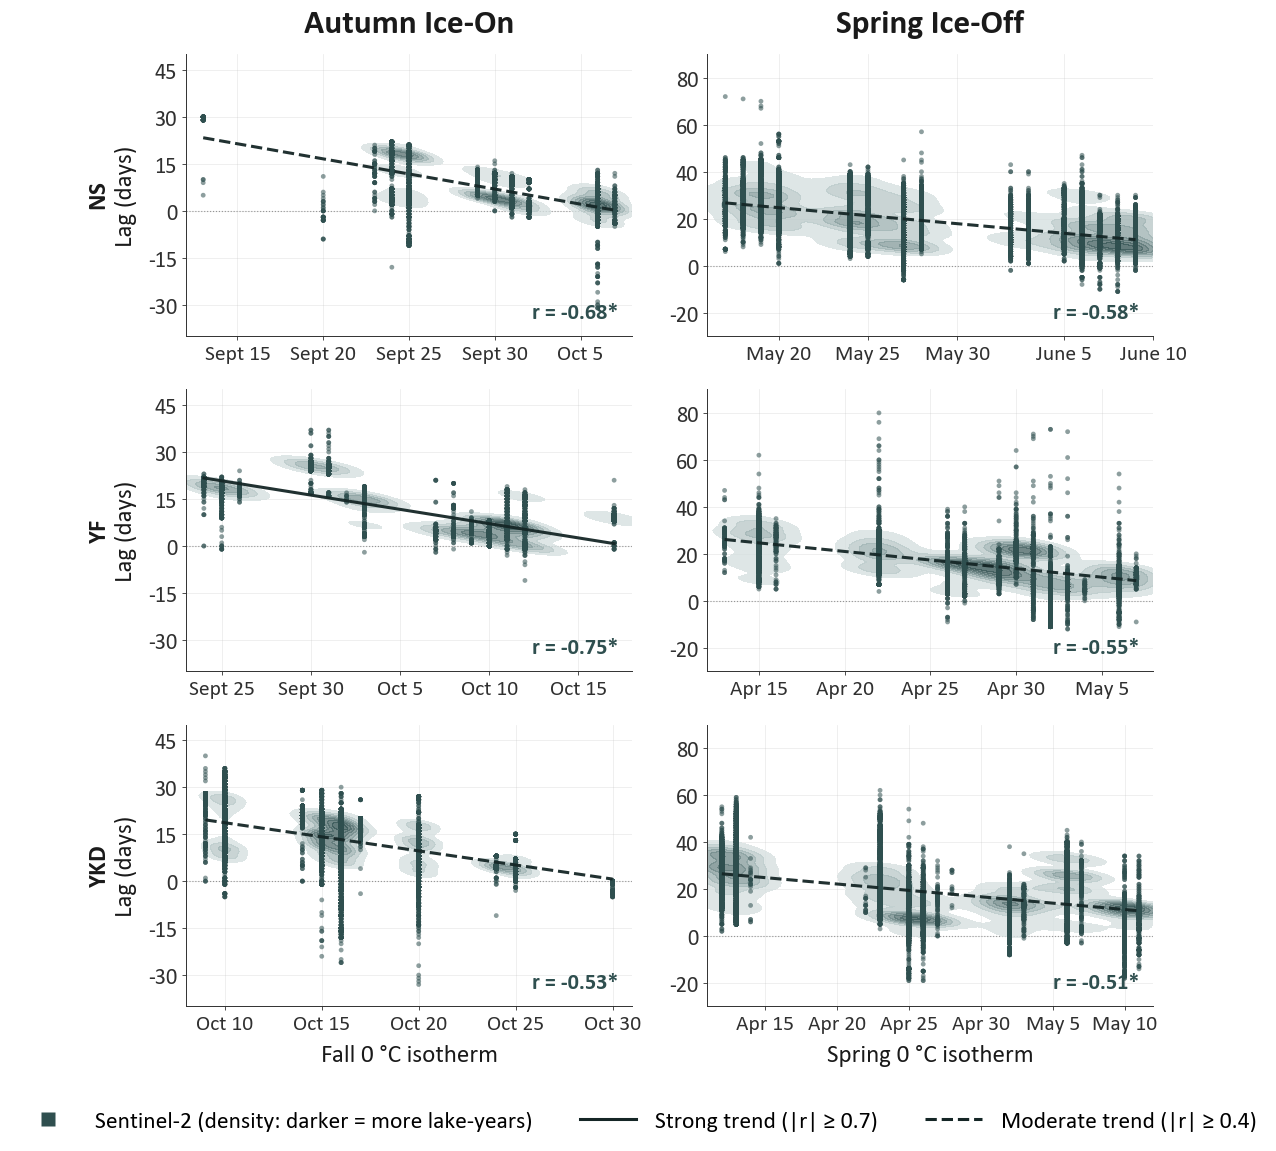

Per-lake lag vs. 0 °C isotherm timing (Sentinel-2). Each point is one lake-year; shading shows local density. Negative slope ⇒ colder years respond faster after the isotherm.

PER-PANEL REGRESSION STATISTICS  (lag_days ~ isotherm_doy, Sentinel-2)
Site  Season             n       r           95% CI     R²        slope ± SE      p-value
------------------------------------------------------------------------------------------------
NS    Autumn Ice-On  14732  -0.679   [-0.69, -0.67]  0.461    -0.964 ± 0.009    p < 0.001
NS    Spring Ice-Off 39582  -0.578   [-0.58, -0.57]  0.334    -0.681 ± 0.005    p < 0.001
YF    Autumn Ice-On  11734  -0.748   [-0.76, -0.74]  0.559    -0.911 ± 0.007    p < 0.001
YF    Spring Ice-Off 12889  -0.553   [-0.56, -0.54]  0.306    -0.730 ± 0.010    p < 0.001
YKD   Autumn Ice-On  48429  -0.528   [-0.53, -0.52]  0.279    -0.900 ± 0.007    p < 0.001
YKD   Spring Ice-Off 57573  -0.513   [-0.52, -0.51]  0.263    -0.543 ± 0.004    p < 0.001

Bonferroni-corrected thre

In [1]:
# ============================================================
# Ice-event lag vs. 0 °C isotherm timing (Sentinel-2)
# Standalone: reads the per-lake-year isotherm/phenology table written by
# Cell 4 of Notebooks/ERA5_CLIMATE_ANALYSIS.ipynb. Re-run that cell if the
# parquet below is missing or stale.
# ============================================================

import math
from datetime import datetime
from pathlib import Path

import matplotlib.lines as mlines
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from matplotlib.colors import LinearSegmentedColormap
from matplotlib.ticker import FixedLocator, FixedFormatter
from scipy.stats import pearsonr, gaussian_kde, linregress, norm

# ── Input (written by ERA5_CLIMATE_ANALYSIS.ipynb, Cell 4) ────────────────────
ERA5_ROOT            = Path(r"E:\planetscope_lake_ice\Data\Input\ERA5 Data")
ISOTHERM_MERGED_PATH = ERA5_ROOT / "Figure Inputs" / "isotherm_merged.parquet"

if not ISOTHERM_MERGED_PATH.exists():
    raise FileNotFoundError(
        f"{ISOTHERM_MERGED_PATH} not found. Run Cells 1-4 of "
        f"ERA5_CLIMATE_ANALYSIS.ipynb to generate it."
    )
isotherm_merged = pd.read_parquet(ISOTHERM_MERGED_PATH)
print(f"Loaded {len(isotherm_merged):,} lake-year rows from {ISOTHERM_MERGED_PATH.name}")

# ── Colour / style constants ──────────────────────────────────────────────────
SENTINEL_COLOR = "#2f4f4f"

# Sentinel-2 density colormap (light teal → deep teal)
SENTINEL_CMAP = LinearSegmentedColormap.from_list(
    "sentinel_density",
    ["#e3eaea", "#9bb0b0", "#5e7878", SENTINEL_COLOR],
)

plt.rcParams.update({
    "font.family":       "Calibri",
    "mathtext.fontset":  "custom",
    "mathtext.rm":       "Calibri",
    "mathtext.it":       "Calibri:italic",
    "mathtext.bf":       "Calibri:bold",
    "font.size":          17.5,
    "axes.titlesize":     18.5,
    "axes.labelsize":     18.0,
    "xtick.labelsize":    15.5,
    "ytick.labelsize":    16.0,
    "legend.fontsize":    17.0,
    "axes.spines.top":    False,
    "axes.spines.right":  False,
    "axes.linewidth":      0.7,
    "axes.edgecolor":     "#303030",
    "xtick.color":        "#303030",
    "ytick.color":        "#303030",
    "axes.labelcolor":    "#1a1a1a",
    "axes.titlecolor":    "#1a1a1a",
    "axes.labelpad":       6,
    "figure.facecolor":   "white",
    "axes.facecolor":     "white",
})

SITES_ORDER = ["NS", "YF", "YKD"]

BREAKUP_SEASON  = "Breakup"
FREEZEUP_SEASON = "Freezeup"

ICE_ON_HEADER  = "Autumn Ice-On"
ICE_OFF_HEADER = "Spring Ice-Off"

COL_CONFIG = [
    {
        "header":  ICE_ON_HEADER,
        "season":  FREEZEUP_SEASON,
        "xlabel":  "Fall 0 °C isotherm",
        "ticks":   [(m, d) for m in (8, 9, 10, 11, 12) for d in (5, 10, 15, 20, 25, 30)],
    },
    {
        "header":  ICE_OFF_HEADER,
        "season":  BREAKUP_SEASON,
        "xlabel":  "Spring 0 °C isotherm",
        "ticks":   [(m, d) for m in (2, 3, 4, 5, 6, 7) for d in (5, 10, 15, 20, 25, 30)],
    },
]

METRIC_COL = "isotherm_doy"

R_STRONG   = 0.70
R_MODERATE = 0.40

_MONTHS = ["", "Jan", "Feb", "Mar", "Apr", "May", "June",
           "July", "Aug", "Sept", "Oct", "Nov", "Dec"]


def _valid_md(month: int, day: int) -> bool:
    try:
        datetime(2023, month, day)
        return True
    except ValueError:
        return False


def _doy_from_md(month: int, day: int, year: int = 2023) -> int:
    return (datetime(year, month, day) - datetime(year, 1, 1)).days + 1


def _format_md(month: int, day: int) -> str:
    return f"{_MONTHS[month]} {day}"


def _trend_linestyle(r: float):
    ar = abs(r)
    if ar >= R_STRONG:
        return "-"
    if ar >= R_MODERATE:
        return "--"
    return None


def _compute_lags(merged: pd.DataFrame) -> pd.DataFrame:
    df = merged.copy()
    df["lag_days"] = df["event_doy"] - df[METRIC_COL]
    return df


# ── Stats helpers ────────────────────────────────────────────────────────────
def _fisher_z_test(r1, n1, r2, n2):
    """Compare two independent Pearson r values via Fisher z-transform.
    Returns (z, two-sided p)."""
    if min(n1, n2) < 4 or abs(r1) >= 1 or abs(r2) >= 1:
        return np.nan, np.nan
    z1 = np.arctanh(r1)
    z2 = np.arctanh(r2)
    se = np.sqrt(1.0 / (n1 - 3) + 1.0 / (n2 - 3))
    z  = (z1 - z2) / se
    p  = 2 * (1 - norm.cdf(abs(z)))
    return z, p


def _r_ci(r, n, alpha=0.05):
    """95% CI on Pearson r via Fisher z-transform."""
    if n < 4 or abs(r) >= 1:
        return np.nan, np.nan
    z   = np.arctanh(r)
    se  = 1.0 / np.sqrt(n - 3)
    zc  = norm.ppf(1 - alpha / 2)
    lo  = np.tanh(z - zc * se)
    hi  = np.tanh(z + zc * se)
    return lo, hi


def _compute_panel_stats(sub: pd.DataFrame) -> dict | None:
    """Compute regression + descriptive stats for one panel."""
    x = sub[METRIC_COL].to_numpy(dtype=float)
    y = sub["lag_days"].to_numpy(dtype=float)
    mask = np.isfinite(x) & np.isfinite(y)
    x, y = x[mask], y[mask]
    n = len(x)
    if n < 3:
        return None
    try:
        lr = linregress(x, y)
    except Exception:
        return None
    r_lo, r_hi = _r_ci(lr.rvalue, n)
    return {
        "n":           n,
        "r":           lr.rvalue,
        "r2":          lr.rvalue ** 2,
        "p":           lr.pvalue,
        "slope":       lr.slope,
        "slope_se":    lr.stderr,
        "intercept":   lr.intercept,
        "r_ci_lo":     r_lo,
        "r_ci_hi":     r_hi,
        "lag_mean":    np.mean(y),
        "lag_sd":      np.std(y, ddof=1) if n > 1 else np.nan,
        "lag_median":  np.median(y),
        "neg_frac":    np.mean(y < 0),
    }


def _fmt_p(p: float) -> str:
    if not np.isfinite(p):
        return "n/a"
    if p < 0.001:
        return "p < 0.001"
    return f"p = {p:.3f}"


# ── Per-panel density plot (Sentinel only) ───────────────────────────────────
def _density_panel(ax, sub: pd.DataFrame):
    x = sub[METRIC_COL].to_numpy(dtype=float)
    y = sub["lag_days"].to_numpy(dtype=float)
    mask = np.isfinite(x) & np.isfinite(y)
    x, y = x[mask], y[mask]

    if len(x) < 2:
        return None

    if len(x) >= 6:
        try:
            xy = np.vstack([x, y])
            kde = gaussian_kde(xy)
            x_pad = max((x.max() - x.min()) * 0.08, 2.0)
            y_pad = max((y.max() - y.min()) * 0.08, 1.0)
            xi, yi = np.mgrid[
                x.min() - x_pad : x.max() + x_pad : 120j,
                y.min() - y_pad : y.max() + y_pad : 120j,
            ]
            zi = kde(np.vstack([xi.flatten(), yi.flatten()])).reshape(xi.shape)
            zmax = zi.max()
            if zmax > 0:
                levels = np.linspace(zmax * 0.08, zmax, 9)
                ax.contourf(xi, yi, zi, levels=levels,
                            cmap=SENTINEL_CMAP, alpha=0.78, zorder=2)
        except Exception:
            pass

    ax.scatter(x, y, s=12, color=SENTINEL_COLOR, alpha=0.55,
               edgecolor="none", zorder=3)

    if len(x) >= 3:
        try:
            r, p = pearsonr(x, y)
            ls = _trend_linestyle(r)
            if ls is not None:
                slope, intercept = np.polyfit(x, y, 1)
                xs = np.linspace(x.min(), x.max(), 200)
                ax.plot(xs, slope * xs + intercept,
                        color="#152626", lw=2.2, linestyle=ls,
                        alpha=0.95, zorder=5)
            return r, p
        except Exception:
            return None
    return None


def _set_date_ticks(ax, ticks_md, data_range=None, pad=2):
    ticks_md  = [(m, d) for m, d in ticks_md if _valid_md(m, d)]
    positions = [_doy_from_md(m, d) for m, d in ticks_md]
    labels    = [_format_md(m, d)    for m, d in ticks_md]

    if data_range is not None and np.isfinite(data_range[0]):
        lo, hi = data_range
        filtered = [
            (pos, lab) for pos, lab in zip(positions, labels)
            if lo - pad <= pos <= hi + pad
        ]
        if filtered:
            positions, labels = zip(*filtered)
            positions, labels = list(positions), list(labels)

    ax.xaxis.set_major_locator(FixedLocator(positions))
    ax.xaxis.set_major_formatter(FixedFormatter(labels))
    ax.tick_params(axis="x", labelbottom=True, labelsize=15.5)


def _apply_y_matched_per_col(axes_2d):
    fig = axes_2d.flat[0].figure
    fig.canvas.draw()
    nrows, ncols = axes_2d.shape
    for j in range(ncols):
        col_axes = [axes_2d[i, j] for i in range(nrows)]
        ymins = [ax.get_ylim()[0] for ax in col_axes]
        ymaxs = [ax.get_ylim()[1] for ax in col_axes]

        col_lo = min(min(ymins), 0)
        col_hi = max(max(ymaxs), 0)

        lo = int(math.floor(col_lo / 5) * 5)
        hi = int(math.ceil(col_hi / 5) * 5)
        if hi == lo:
            hi = lo + 5

        step = max(5, int(math.ceil((hi - lo) / 6 / 5) * 5))

        ticks_up = list(range(0, hi + 1, step))
        ticks_dn = list(range(-step, lo - 1, -step))
        ticks    = sorted(set(ticks_up + ticks_dn))

        for ax in col_axes:
            ax.set_ylim(lo, hi)
            ax.set_yticks(ticks)
            ax.yaxis.set_major_formatter(
                plt.FuncFormatter(lambda v, _: f"{int(v)}")
            )


def _legend_handles():
    return [
        mlines.Line2D([], [], marker="s", linestyle="none",
                      color=SENTINEL_COLOR, markersize=10,
                      markeredgecolor="none",
                      label="Sentinel-2 (density: darker = more lake-years)"),
        mlines.Line2D([], [], linestyle="-",  color="#152626", lw=2.2,
                      label=f"Strong trend (|r| ≥ {R_STRONG})"),
        mlines.Line2D([], [], linestyle="--", color="#152626", lw=2.2,
                      label=f"Moderate trend (|r| ≥ {R_MODERATE})"),
    ]


# ── Stats summary printer ────────────────────────────────────────────────────
def _print_stats_summary(lags: pd.DataFrame) -> None:
    """Print a structured stats summary keyed off the same site/season grid."""
    stats_by_site_season = {}
    for site in SITES_ORDER:
        stats_by_site_season[site] = {}
        for col in COL_CONFIG:
            sub = lags[
                (lags["site"]   == site) &
                (lags["season"] == col["season"]) &
                (lags["sensor"] == "S2")
            ]
            stats_by_site_season[site][col["header"]] = _compute_panel_stats(sub)

    # Per-panel table
    print("\n" + "=" * 96)
    print("PER-PANEL REGRESSION STATISTICS  (lag_days ~ isotherm_doy, Sentinel-2)")
    print("=" * 96)
    header = (f"{'Site':<5} {'Season':<14} {'n':>5} "
              f"{'r':>7} {'95% CI':>16} {'R²':>6} "
              f"{'slope ± SE':>17} {'p-value':>12}")
    print(header)
    print("-" * 96)
    for site in SITES_ORDER:
        for col in COL_CONFIG:
            s = stats_by_site_season[site][col["header"]]
            if s is None:
                print(f"{site:<5} {col['header']:<14}  (insufficient data)")
                continue
            ci_str    = f"[{s['r_ci_lo']:+.2f}, {s['r_ci_hi']:+.2f}]"
            slope_str = f"{s['slope']:+.3f} ± {s['slope_se']:.3f}"
            print(f"{site:<5} {col['header']:<14} {s['n']:>5d} "
                  f"{s['r']:>+7.3f} {ci_str:>16} {s['r2']:>6.3f} "
                  f"{slope_str:>17} {_fmt_p(s['p']):>12}")

    # Multiple-comparison note
    pvals = [stats_by_site_season[site][col["header"]]["p"]
             for site in SITES_ORDER for col in COL_CONFIG
             if stats_by_site_season[site][col["header"]] is not None]
    if pvals:
        bonf_alpha = 0.05 / len(pvals)
        n_sig      = sum(p < bonf_alpha for p in pvals)
        print(f"\nBonferroni-corrected threshold (α=0.05, k={len(pvals)}): "
              f"p < {bonf_alpha:.4f}  →  {n_sig}/{len(pvals)} panels remain significant")

    # Descriptive stats
    print("\n" + "=" * 96)
    print("DESCRIPTIVE LAG STATISTICS")
    print("=" * 96)
    desc_header = (f"{'Site':<5} {'Season':<14} {'n':>5} "
                   f"{'mean ± SD':>16} {'median':>8} {'% neg lag':>11}")
    print(desc_header)
    print("-" * 96)
    for site in SITES_ORDER:
        for col in COL_CONFIG:
            s = stats_by_site_season[site][col["header"]]
            if s is None:
                continue
            ms = f"{s['lag_mean']:+.1f} ± {s['lag_sd']:.1f}"
            print(f"{site:<5} {col['header']:<14} {s['n']:>5d} "
                  f"{ms:>16} {s['lag_median']:>+8.1f} {100*s['neg_frac']:>10.1f}%")

    # Spring Ice-Off vs Autumn Ice-On Fisher z within each site
    print("\n" + "=" * 96)
    print("SPRING ICE-OFF vs AUTUMN ICE-ON CORRELATION COMPARISON  (Fisher z-test, within site)")
    print("=" * 96)
    print(f"{'Site':<5} {'r (ice-off)':>12} {'n':>5} {'r (ice-on)':>12} {'n':>5} "
          f"{'Δr':>7} {'z':>7} {'p':>12}")
    print("-" * 96)
    for site in SITES_ORDER:
        b = stats_by_site_season[site].get(ICE_OFF_HEADER)
        f = stats_by_site_season[site].get(ICE_ON_HEADER)
        if b is None or f is None:
            continue
        z, p = _fisher_z_test(b["r"], b["n"], f["r"], f["n"])
        dr   = f["r"] - b["r"]
        print(f"{site:<5} {b['r']:>+12.3f} {b['n']:>5d} {f['r']:>+12.3f} {f['n']:>5d} "
              f"{dr:>+7.3f} {z:>+7.2f} {_fmt_p(p):>12}")

    # Site-vs-site Fisher z within each season
    print("\n" + "=" * 96)
    print("BETWEEN-SITE CORRELATION COMPARISON  (Fisher z-test, within season)")
    print("=" * 96)
    print(f"{'Season':<14} {'Site A':<6} {'r_A':>8} {'n_A':>5} "
          f"{'Site B':<7} {'r_B':>8} {'n_B':>5} {'Δr':>7} {'z':>7} {'p':>12}")
    print("-" * 96)
    pairs = [(SITES_ORDER[i], SITES_ORDER[j])
             for i in range(len(SITES_ORDER))
             for j in range(i + 1, len(SITES_ORDER))]
    for col in COL_CONFIG:
        for a, b in pairs:
            sa = stats_by_site_season[a][col["header"]]
            sb = stats_by_site_season[b][col["header"]]
            if sa is None or sb is None:
                continue
            z, p = _fisher_z_test(sa["r"], sa["n"], sb["r"], sb["n"])
            dr   = sb["r"] - sa["r"]
            print(f"{col['header']:<14} {a:<6} {sa['r']:>+8.3f} {sa['n']:>5d} "
                  f"{b:<7} {sb['r']:>+8.3f} {sb['n']:>5d} "
                  f"{dr:>+7.3f} {z:>+7.2f} {_fmt_p(p):>12}")

    print("\n" + "=" * 96)
    print("Interpretation hints:")
    print("  • slope = days of lag change per 1-day shift in isotherm date")
    print("  • R²    = fraction of lag variance explained by isotherm timing")
    print("  • % neg lag = lake-years where ice event occurred BEFORE isotherm")
    print("  • Fisher z compares correlations; |z| > 1.96 ⇒ p < 0.05 (two-sided)")
    print("=" * 96 + "\n")


# ── Main plot ─────────────────────────────────────────────────────────────────
def plot_lag_vs_isotherm(merged: pd.DataFrame) -> None:
    lags  = _compute_lags(merged)
    nrows = len(SITES_ORDER)
    ncols = len(COL_CONFIG)

    fig, axes = plt.subplots(
        nrows, ncols,
        figsize=(11.5, 12),
        sharex=False,
        sharey=False,
    )

    for i, site in enumerate(SITES_ORDER):
        for j, col in enumerate(COL_CONFIG):
            ax = axes[i, j]

            ax.axhline(0, color="#888888", lw=0.8, linestyle=":", zorder=1)
            ax.grid(True, color="#bfbfbf", alpha=0.35, linewidth=0.5)
            ax.tick_params(length=3, width=0.6)

            sub = lags[
                (lags["site"]   == site) &
                (lags["season"] == col["season"]) &
                (lags["sensor"] == "S2")
            ]

            r_p = _density_panel(ax, sub)
            if r_p is not None:
                r, p = r_p
                sig = "*" if p < 0.05 else ""
                ax.text(0.97, 0.05, f"r = {r:.2f}{sig}",
                        transform=ax.transAxes, ha="right", va="bottom",
                        fontsize=16, fontweight="bold",
                        color=SENTINEL_COLOR)

            if i == 0:
                ax.set_title(col["header"], fontsize=24, fontweight="bold",
                             pad=16, color="#1a1a1a")

            if j == 0:
                ax.set_ylabel(f"$\\bf{{{site}}}$\nLag (days)",
                              fontsize=18, labelpad=8)

            if i == nrows - 1:
                ax.set_xlabel(col["xlabel"], labelpad=8)

    for i, site in enumerate(SITES_ORDER):
        for j, col in enumerate(COL_CONFIG):
            ax  = axes[i, j]
            sub = lags[
                (lags["site"]   == site) &
                (lags["season"] == col["season"]) &
                (lags["sensor"] == "S2")
            ]
            data_x = sub[METRIC_COL].dropna().to_numpy()
            if len(data_x):
                x_min, x_max = data_x.min(), data_x.max()
                xpad = max((x_max - x_min) * 0.03, 1.0)
                ax.set_xlim(x_min - xpad, x_max + xpad)
                _set_date_ticks(ax, col["ticks"], (x_min, x_max))
            else:
                _set_date_ticks(ax, col["ticks"])

    _apply_y_matched_per_col(axes)

    fig.legend(handles=_legend_handles(), loc="lower center",
               bbox_to_anchor=(0.5, -0.005), ncol=3, frameon=False,
               handlelength=2.4, columnspacing=2.0)

    fig.tight_layout(rect=[0, 0.045, 1, 0.97])
    plt.show()

    print(
        "Per-lake lag vs. 0 °C isotherm timing (Sentinel-2). "
        "Each point is one lake-year; shading shows local density. "
        "Negative slope ⇒ colder years respond faster after the isotherm."
    )

    _print_stats_summary(lags)


# ── Run ───────────────────────────────────────────────────────────────────────
plot_lag_vs_isotherm(isotherm_merged)